# NB01 - Preparacion de datos y EDA

**Estatus:** canonico  
**Objetivo:** preparar el dataset base del estudio, documentar la construccion de etiquetas y dejar trazables las exportaciones estructurales usadas por el resto del pipeline.  
**Inputs minimos:** serie WTI cruda/congelada, utilidades locales y `config/config_estudio_FINAL.json` cuando corresponde sincronizar metadatos base.  
**Outputs principales:** `data/raw/wti_volatilidad_ALL.csv`, `data/processed/wti_volatilidad_CLEAN.csv`, `data/processed/wti_volatilidad_MODEL_BASE.csv`, figuras EDA y metadatos estructurales del estudio.  
**Config / gobernanza:** prepara exports base y metadatos consumidos por etapas posteriores; actualiza la capa base del estudio cuando corresponde.  
**No inferir de este notebook:** el benchmark predictivo formal y la comparacion de modelos se resuelven en NB02, no aqui.

**Contrato temporal NB01 -> NB02:**  
- `MODEL_BASE` preserva el calendario canonico downstream y mantiene filas `bad_vol21` con flags.  
- `CLEAN` se conserva para EDA, tablas descriptivas y trazabilidad del recorte historico.  
- `NB02` reconstruye `decision_date`, `target_date` y `y_tp1` sobre `MODEL_BASE`; nunca debe inferirlos desde `CLEAN`.

**Contrato de config (runtime Colab):** este notebook escribe la base del estudio en `BASE_PATH/config_estudio_FINAL.json`. El archivo del repo `config/config_estudio_FINAL.json` es un espejo sincronizado despues de la corrida.  
**Orden oficial:** `NB01 -> NB03A (si aprobado) -> NB03B (si aprobado) -> NB02 CPU -> NB02 GPU opcional`. El flujo canonico minimo sigue siendo `NB01 -> NB02 CPU`.  
**Proteccion downstream:** por defecto NB01 preserva `nb02_results`, `nb02_metadata`, `nb02_experiments`, `nb03` y `nb03b`; solo `NB01_RESET_DOWNSTREAM=True` permite reset total.

# Parametros clave

- **Objetivo del notebook:** preparar el dataset canonico del estudio y fijar los metadatos base que consumen etapas posteriores.
- **Fuente(s) principal(es):** `data/raw/wti_volatilidad_ALL.csv`, serie WTI congelada y datasets derivados `data/processed/wti_volatilidad_MODEL_BASE.csv` y `data/processed/wti_volatilidad_CLEAN.csv`.
- **Configuracion metodologica fija:** volatilidad realizada de 21 dias, `P95 = 0.042996` calibrado solo en train, `RANDOM_SEED = 42`, y splits `train <= 2018-12-31`, `validation = 2019-01-02 -> 2020-12-31`, `test >= 2021-01-02`.
- **Supuestos/restricciones relevantes:** el clipping a `0.01` y la ventana `vol21` se mantienen; `MODEL_BASE` preserva el calendario completo post-warm-up y `CLEAN` conserva el recorte historico solo para analisis descriptivo.
- **Artefactos de salida principales:** CSV `MODEL_BASE`, `CLEAN` y `ALL`, figuras EDA y exports base/metadatos del estudio consumidos por NB02, NB03A y NB03B.
- **Notas de reproducibilidad:** este notebook prepara la capa base que el resto del pipeline debe consumir sin recalcular P95, splits ni features estructurales; la evaluacion predictiva formal vive en NB02.

## 0.1 Configuración Inicial

In [1]:
# IMPORTAR LIBRERÍAS
import os
import sys
import numpy as np
import random
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import matplotlib.ticker as ticker
import matplotlib as mpl
import shutil
from matplotlib.lines import Line2D
import matplotlib.dates as mdates
import seaborn as sns
import scipy
import scipy.stats as stats
import statsmodels
import sklearn
import warnings
import json

from datetime import datetime
from matplotlib.patches import Rectangle
from pathlib import Path

# Descarga de datos
import yfinance as yf

# Tests estadísticos
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import het_arch
from scipy.stats import jarque_bera, shapiro, ks_2samp, zscore, norm

from sklearn.metrics import (f1_score, roc_auc_score, precision_score,
                              recall_score, confusion_matrix,
                              classification_report)

# Configuración
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)

print(" Librerías importadas correctamente")
print(f"Fecha de ejecución: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

 Librerías importadas correctamente
Fecha de ejecución: 2026-03-30 07:16:38


In [2]:
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    try:
        drive.mount('/content/drive', force_remount=False)
    except Exception as e:
        print(f"Drive ya montado o error: {e}")
    BASE_PATH   = "/content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos"
    NB01_PATH   = "/content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB01_EDA"
    OUTPUT_PATH = BASE_PATH
    FIG_PATH    = "/content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB01_EDA/Figuras Notebook EDA"
else:
    BASE_PATH   = "."
    NB01_PATH   = "."
    OUTPUT_PATH = "."
    FIG_PATH    = "./figuras_nb01"

# Se crean ambos directorios para que la exportación conserve la misma estructura en Colab y en local.
Path(FIG_PATH).mkdir(parents=True, exist_ok=True)

print(f"IN_COLAB   : {IN_COLAB}")
print(f"BASE_PATH  : {BASE_PATH}")
print(f"NB01_PATH  : {NB01_PATH}")
print(f"OUTPUT_PATH: {OUTPUT_PATH}")
print(f"FIG_PATH   : {FIG_PATH}")
print(f"FIG_PATH creado/verificado: {Path(FIG_PATH).exists()}")


Mounted at /content/drive
IN_COLAB   : True
BASE_PATH  : /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos
NB01_PATH  : /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB01_EDA
OUTPUT_PATH: /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos
FIG_PATH   : /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB01_EDA/Figuras Notebook EDA
FIG_PATH creado/verificado: True


In [3]:
# FIGURE_UTILS
# Carga preferente desde utils/ para mantener estilos y paletas consistentes
for _p in [
    '/content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/utils',
    os.path.abspath('./utils'),
    os.path.abspath('../utils'),
]:
    if os.path.isdir(_p) and _p not in sys.path:
        sys.path.insert(0, _p)

try:
    from figure_utils import (
        fig_size, save_fig, apply_thesis_style, add_top_legend,
        # Splits y clases
        SPLIT_COLORS, COLOR_NORMAL, COLOR_EXTREMO,
        # Series principales
        COLOR_PRECIO, COLOR_VOL, COLOR_CLEAN, COLOR_VAR, COLOR_DYN,
        # Percentiles y modelos
        COLORS_P, COLORES_MODELOS, COLORES_B,
        # NB03A y NB03B
        COLORS_SENT, COLORS_SIGNALS,
    )
    mpl.rcParams.update(mpl.rcParamsDefault)
    apply_thesis_style('A4')
    print("[OK] figure_utils v2.3 cargado desde utils/")

except Exception as e:
    warnings.warn(
        "[figure_utils] utils/ no disponible o falló import — activando fallback inline.\n"
        f"  Detalle: {type(e).__name__}: {e}",
        UserWarning, stacklevel=2
    )

    # ── Fallback inline
    def fig_size(layout='full', fmt='A4', aspect=0.618):
        tw, th = (6.11, 9.73) if fmt == 'A4' else (6.34, 9.04)
        opts = {
            'full': (tw, tw*aspect), 'half': (tw/2, (tw/2)*aspect),
            'wide': (tw, tw*0.45),   '2x1':  (tw, tw*0.50),
            '2x2':  (tw, tw*0.75),   '3x1':  (tw, tw*0.38),
            'square': (tw, tw),      'tall': (tw, min(tw*1.40, th*0.85)),
            'page': (tw, th*0.90),
            'nb03_ts':   (tw, min(tw*1.45, th*0.92)),
            'nb03_dist': (tw, tw*0.62),
            'nb03_corr': (tw, tw*0.95),
        }
        result = opts.get(layout)
        if result is None:
            warnings.warn(f"Layout '{layout}' no reconocido. Usando 'full'.", UserWarning)
            result = opts['full']
        return tuple(round(x, 4) for x in result)

    def save_fig(fig_or_none=None, filename='', output_path='.', dpi=300,
                 fmt='png', fmt_page='A4', warn=True, **kwargs):
        if not filename or not filename.strip():
            raise ValueError("filename no puede estar vacío en save_fig().")
        fig = fig_or_none if fig_or_none is not None else plt.gcf()
        os.makedirs(output_path, exist_ok=True)
        path = os.path.join(output_path,
                            f"{filename.replace(' ','_').replace('/','_')}.{fmt}")
        fig.savefig(path, dpi=dpi, bbox_inches='tight', pad_inches=0.04,
                    facecolor='white', edgecolor='none', **kwargs)
        w, h = fig.get_size_inches()
        print(f"  [OK] {path}  [{w:.1f}\"×{h:.1f}\" @ {dpi}dpi]")
        return path

    def add_top_legend(handles, labels=None, ax=None, fig=None,
                       ncol=4, y=0.98, fontsize=8.5, frameon=True):
        if fig is None and ax is None:
            raise ValueError("Debes pasar ax o fig.")
        kw = dict(ncol=ncol, fontsize=fontsize, frameon=frameon,
                  columnspacing=1.2, handletextpad=0.6)
        if fig is not None:
            return fig.legend(handles=handles, labels=labels,
                              loc='upper center', bbox_to_anchor=(0.5, y), **kw)
        return ax.legend(handles=handles, labels=labels,
                         loc='lower center', bbox_to_anchor=(0.5, 1.02), **kw)

    # ── Paletas canónicas
    # Splits y clases
    SPLIT_COLORS  = {'train': '#2166ac', 'validation': '#f4a582',
                     'val': '#f4a582',   'test': '#d6604d'}
    COLOR_NORMAL  = '#2166ac'
    COLOR_EXTREMO = '#d73027'
    # Series principales
    COLOR_PRECIO  = '#253494'
    COLOR_VOL     = '#2c7bb6'
    COLOR_CLEAN   = '#4575b4'
    COLOR_VAR     = '#74add1'
    COLOR_DYN     = '#f4a582'
    # Percentiles
    COLORS_P      = {90: '#fdae61', 95: '#d73027', 99: '#7b2d8b'}
    # Modelos benchmark NB02
    COLORES_MODELOS = {
        'GARCH':             '#7b2d8b',
        'LSTM-Simple-Uni':   '#74add1',
        'LSTM-Simple-Multi': '#4575b4',
        'BiDir-LSTM-Uni':    '#d73027',
        'BiDir-LSTM-Multi':  '#f46d43',
        'Hybrid-Sent':       '#fdae61',
        'Hybrid-MktSignals': '#fee090',
        'Baseline-B1':       '#aaaaaa',
        'Baseline-B5':       '#555555',
    }
    # Baselines NB01
    COLORES_B     = ['#aaaaaa', '#2166ac', '#f4a582',
                     '#4575b4', '#d6604d', '#7b2d8b']
    # Sentimiento NB03A
    COLORS_SENT   = {'positive': '#1a9641', 'negative': '#d7191c', 'neutral': '#b0b0b0'}
    # Señales mercado NB03B
    COLORS_SIGNALS = {'OVX': '#d73027', 'VIX': '#4575b4',
                      'DXY': '#1a9641',  'EIA': '#7b2d8b'}

    # ── Estilo IEEE fallback ──
    mpl.rcParams.update(mpl.rcParamsDefault)
    try:
        plt.style.use('seaborn-v0_8-whitegrid')
    except Exception:
        pass
    plt.rcParams.update({
        'font.family': 'serif',
        'font.serif': ['Times New Roman', 'Computer Modern', 'DejaVu Serif'],
        'font.size': 10,
        'axes.titlesize': 11, 'axes.titleweight': 'bold',
        'axes.titlelocation': 'center', 'axes.titlepad': 10,
        'axes.labelsize': 11, 'xtick.labelsize': 9, 'ytick.labelsize': 9,
        'xtick.major.pad': 3.5, 'ytick.major.pad': 3.5,
        'legend.fontsize': 9, 'legend.frameon': True,
        'legend.framealpha': 0.85, 'legend.edgecolor': 'gray',
        'figure.dpi': 150, 'savefig.dpi': 300,
        'figure.facecolor': 'white', 'axes.facecolor': 'white',
        'axes.grid': True, 'grid.alpha': 0.25, 'grid.linestyle': ':',
        'axes.edgecolor': 'black', 'axes.linewidth': 0.8,
        'lines.linewidth': 1.5, 'lines.markersize': 4,
    })
    print("[OK] figure_utils fallback inline activo (v2.3)")

[IEEE v2.3] Estilo aplicado — A4: 6.11"×9.73" (15.5×24.7 cm)
  Layouts (figsize):
    fig_size('full     ') -> (6.11, 3.78)"
    fig_size('half     ') -> (3.06, 1.89)"
    fig_size('wide     ') -> (6.11, 2.75)"
    fig_size('2x1      ') -> (6.11, 3.06)"
    fig_size('2x2      ') -> (6.11, 4.58)"
    fig_size('3x1      ') -> (6.11, 2.32)"
    fig_size('tall     ') -> (6.11, 8.27)"
    fig_size('page     ') -> (6.11, 8.76)"
    fig_size('nb03_ts  ') -> (6.11, 8.86)"
    fig_size('nb03_dist') -> (6.11, 3.79)"
    fig_size('nb03_corr') -> (6.11, 5.80)"
[OK] figure_utils v2.3 cargado desde utils/


In [4]:
# VERSIONES DE LIBRERÍAS (REPRODUCIBILIDAD)
print("ENTORNO DE EJECUCIÓN")
print(f"  Python:       {sys.version.split()[0]}")
print(f"  numpy:        {np.__version__}")
print(f"  pandas:       {pd.__version__}")
print(f"  scipy:        {scipy.__version__}")
print(f"  statsmodels:  {statsmodels.__version__}")
print(f"  sklearn:      {sklearn.__version__}")
print(f"  matplotlib:   {mpl.__version__}")
print(f"  seaborn:      {sns.__version__}")
print(f"  yfinance:     {yf.__version__}")

ENTORNO DE EJECUCIÓN
  Python:       3.12.13
  numpy:        2.0.2
  pandas:       2.2.2
  scipy:        1.16.3
  statsmodels:  0.14.6
  sklearn:      1.6.1
  matplotlib:   3.10.0
  seaborn:      0.13.2
  yfinance:     0.2.66


In [5]:
# PARÁMETROS DEL ESTUDIO

# Semilla para reproducibilidad
RANDOM_SEED = 42
os.environ['PYTHONHASHSEED'] = str(RANDOM_SEED)  # hashing reproducible (Python 3.3+)
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)
# tf.random.set_seed(RANDOM_SEED)  # NB01 no instancia modelos TF -- activo en NB02

# Período de estudio completo
START_DATE = '2000-01-01'
END_DATE = '2026-02-28'

# DIVISIÓN TEMPORAL (CRÍTICO)

TRAIN_END = '2018-12-31'      # Train: 2000-2018 (19 años)
VAL_START = '2019-01-02'
VAL_END = '2020-12-31'        # Validation: 2019-2020 (incluye COVID)
TEST_START = '2021-01-02'     # Test: 2021-presente

# Percentiles para eventos extremos
PERCENTILES = [88, 90, 92, 93, 94, 95, 96, 97, 98, 99]
PERCENTILE_PRIMARY = 95

# Ventanas para features
MA_SHORT = 5                  # Media móvil corta
MA_LONG = 21                  # Media móvil larga
VOLATILITY_WINDOW = 21        # Ventana de volatilidad (~1 mes trading)
ROLLING_VAR_WINDOW = 252      # Ventana de VaR rolling (~1 año trading)

# Parámetro de clipping
CLIP_FLOOR = 0.01
print("CONFIGURACIÓN DEL ESTUDIO")
print(f"Período total:      {START_DATE} → {END_DATE}")
print("\nDIVISIÓN TEMPORAL:")
print(f"  Período solicitado: {START_DATE} → {END_DATE}")
print(f"  (Fecha real primer dato se confirma tras descarga)")
print(f"  Validation: {VAL_START} → {VAL_END}")
print(f"  Test:       {TEST_START} → {END_DATE}")
print(f"\nPercentil principal: P{PERCENTILE_PRIMARY}")
print(f"Semilla aleatoria: {RANDOM_SEED}")
print(f"Clipping floor: ${CLIP_FLOOR}")
print(f"RANDOM_SEED={RANDOM_SEED} | Python={sys.version.split()[0]} | seeds fijadas (sin TF)")


CONFIGURACIÓN DEL ESTUDIO
Período total:      2000-01-01 → 2026-02-28

DIVISIÓN TEMPORAL:
  Período solicitado: 2000-01-01 → 2026-02-28
  (Fecha real primer dato se confirma tras descarga)
  Validation: 2019-01-02 → 2020-12-31
  Test:       2021-01-02 → 2026-02-28

Percentil principal: P95
Semilla aleatoria: 42
Clipping floor: $0.01
RANDOM_SEED=42 | Python=3.12.13 | seeds fijadas (sin TF)


## 0.2 Descarga de Datos

In [6]:
DATA_PATH = f"{NB01_PATH}/wti_raw_frozen.csv"

if os.path.exists(DATA_PATH):
    #  Cargar datos congelados
    print(f"Cargando datos congelados desde: {DATA_PATH}")
    df_raw_loaded = pd.read_csv(DATA_PATH, index_col=0, parse_dates=True)
    df = pd.DataFrame()
    df['wti_raw'] = df_raw_loaded['wti_raw']
    df['high']    = df_raw_loaded['high']
    df['low']     = df_raw_loaded['low']
    df['open']    = df_raw_loaded['open']
    df['volumen'] = df_raw_loaded['volumen']
    print(f"  Datos reproducibles garantizados (frozen {DATA_PATH.split('/')[-1]})")

else:
    #  Primera ejecución: descargar y congelar
    print("Descargando datos de WTI desde Yahoo Finance...")
    print(f"Período: {START_DATE} a {END_DATE}")

    df_raw = yf.download('CL=F', start=START_DATE, end=END_DATE,
                         progress=False, multi_level_index=False)
    df = pd.DataFrame()
    df['wti_raw'] = df_raw['Close']
    df['high']    = df_raw['High']
    df['low']     = df_raw['Low']
    df['open']    = df_raw['Open']
    df['volumen'] = df_raw['Volume']
    df['volumen'] = df['volumen'].replace(0, np.nan)

    # Congelar antes de cualquier procesamiento
    df.to_csv(DATA_PATH)
    print(f"  Datos congelados en: {DATA_PATH}")

# Procesamiento
df['volumen'] = df['volumen'].replace(0, np.nan)

print(f"\n  Volumen — NaN: {df['volumen'].isna().sum()} | "
      f"zeros: {(df['volumen'] == 0).sum()} | "
      f"media: {df['volumen'].mean():,.0f}")
print("  Días con volumen=0 (ahora NaN):")
print(df[df['volumen'].isna()].index.strftime('%Y-%m-%d').tolist())

n_before = len(df)
df = df.dropna(subset=['wti_raw', 'high', 'low', 'open'])
print(f"\nObs eliminadas por NaN solo en columnas de precio: {n_before - len(df)}")
print("Volumen tiene 12 NaN legítimos (festivos) — se tratan en NB02.")

print(f"\nDatos: {len(df):,} observaciones")
print(f"  Período real:    {df.index.min().date()} → {df.index.max().date()}")
print(f"  Precio mínimo:   ${df['wti_raw'].min():.2f}/barril")
print(f"  Precio máximo:   ${df['wti_raw'].max():.2f}/barril")
print(f"  Precio promedio: ${df['wti_raw'].mean():.2f}/barril")
print(f"  Precio negativo: {(df['wti_raw'] < 0).sum()} días")


Cargando datos congelados desde: /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB01_EDA/wti_raw_frozen.csv
  Datos reproducibles garantizados (frozen wti_raw_frozen.csv)

  Volumen — NaN: 12 | zeros: 0 | media: 303,303
  Días con volumen=0 (ahora NaN):
['2000-10-13', '2000-11-21', '2001-02-16', '2001-03-13', '2001-09-10', '2001-09-14', '2023-04-06', '2025-06-18', '2025-07-03', '2025-07-04', '2025-08-29', '2025-11-03']

Obs eliminadas por NaN solo en columnas de precio: 0
Volumen tiene 12 NaN legítimos (festivos) — se tratan en NB02.

Datos: 6,406 observaciones
  Período real:    2000-08-23 → 2026-02-27
  Precio mínimo:   $-37.63/barril
  Precio máximo:   $145.29/barril
  Precio promedio: $64.65/barril
  Precio negativo: 1 días


**Volumen:** 12 días con volumen=0 reemplazados por NaN.
- 2000-2001: cobertura incompleta de Yahoo Finance en años iniciales del contrato
- 2023-2025: festivos federales (Juneteenth, Independence Day, Good Friday)
No se crea máscara adicional — NaN propagados y manejados por dropna en NB02.


## 0.3 Tratamiento Auditable del Precio Negativo (Clipping)

- Precio negativo el 2020-04-20 (-\$37.63) impide cálculo de retornos logarítmicos
- Clipping a piso de $0.01 (permite log-returns)
- **Trazabilidad:** Se conserva `wti_raw` para auditoría
- Genera 2 retornos extremos (día t y t+1) → 22 días de volatilidad contaminada
- Dataset ALL (descriptivo) vs CLEAN (modelado)

In [7]:
print("TRATAMIENTO DEL PRECIO NEGATIVO")

# Aplicar clipping
df['wti'] = df['wti_raw'].clip(lower=CLIP_FLOOR)
# Identificar precios no positivos
neg_count = (df['wti_raw'] <= 0).sum()
print(f"\nPrecios no positivos detectados: {neg_count}")
if neg_count > 0:
    neg_dates = df[df['wti_raw'] <= 0].index
    neg_prices = df.loc[df['wti_raw'] <= 0, 'wti_raw'].values
    print("\nDETALLE DE EVENTOS:")
    for date, price in zip(neg_dates, neg_prices):
        print(f"  {date.date()}: ${price:.2f} → Clipped a ${CLIP_FLOOR}")


TRATAMIENTO DEL PRECIO NEGATIVO

Precios no positivos detectados: 1

DETALLE DE EVENTOS:
  2020-04-20: $-37.63 → Clipped a $0.01


El evento de precio negativo del 20 de abril de 2020 contamina los retornos
logarítmicos por construcción aritmética. Su tratamiento debe ser auditable y trazable.

- Causa: Saturación de tanques en Cushing, Oklahoma (crisis de almacenamiento COVID-19)
- Solución: Clipping a $0.01 — preserva la serie con `wti_raw` para auditoría

> Para el calculo de los Retornos logarítmicos sobre la serie clipped (wti), no sobre wti_raw.
> wti[t] como wti[t-1] usan la serie clipped.
> - 2020-04-20: wti_raw=-37.63 → wti=0.01 (clipped). retorno[t] = log(0.01/wti[t-1])
> - 2020-04-21: wti[t-1]=0.01  → retorno[t] = log(wti[t]/0.01).

> El denominador $0.01 produce retornos de -751% y +691% respectivamente.
> Por eso bad_return marca esos 2 días — no son retornos reales del mercado.
> Implicación: bad_return detecta contaminación ARITMÉTICA del clipping independientemente de si el precio de t o t-1 fue el clipped.

In [8]:
# CÁLCULO DE RETORNOS Y MARCADO DE CONTAMINACIÓN

# Retornos logarítmicos (sobre wti clipped)
df['returns'] = np.log(df['wti'] / df['wti'].shift(1))
# Marcar retornos contaminados: día del evento Y día siguiente
df['bad_return'] = (df['wti_raw'] <= 0) | (df['wti_raw'].shift(1) <= 0)

# Eliminar solo el NaN de returns
n_before = len(df)
df = df.dropna(subset=['returns'])
print(f"Obs eliminadas por NaN iniciales: {n_before - len(df)}")

print("Retornos calculados")
print(f"  Retornos contaminados por clipping: {df['bad_return'].sum()}")
print(f"  Fechas afectadas:")
if df['bad_return'].any():
    affected = df[df['bad_return']]
    for date, row in affected.iterrows():
        print(f"    {date.date()} | wti_raw={row['wti_raw']:.2f} | "
              f"wti_clipped={row['wti']:.4f} | returns={row['returns']*100:.2f}%")

Obs eliminadas por NaN iniciales: 1
Retornos calculados
  Retornos contaminados por clipping: 2
  Fechas afectadas:
    2020-04-20 | wti_raw=-37.63 | wti_clipped=0.0100 | returns=-751.04%
    2020-04-21 | wti_raw=10.01 | wti_clipped=10.0100 | returns=690.88%


In [9]:
# ESTADÍSTICAS DESCRIPTIVAS - RETORNOS

returns_all = df['returns']
returns_clean = df.loc[~df['bad_return'], 'returns']

print("ESTADÍSTICAS DESCRIPTIVAS - RETORNOS")

# Crear tabla comparativa
estad = pd.DataFrame({
    'Métrica': [
        'N observaciones',
        'Media diaria (%)',
        'Retorno anualizado (%)',
        'Volatilidad diaria (%)',
        'Volatilidad anualizada (%)',
        'Mínimo (%)',
        'Máximo (%)',
        'Skewness',
        'Kurtosis'
    ],
    'ALL': [
        f"{len(returns_all):,}",
        f"{returns_all.mean()*100:.4f}",
        f"{returns_all.mean()*252*100:.2f}",
        f"{returns_all.std()*100:.4f}",
        f"{returns_all.std()*np.sqrt(252)*100:.2f}",
        f"{returns_all.min()*100:.2f}",
        f"{returns_all.max()*100:.2f}",
        f"{returns_all.skew():.2f}",
        f"{returns_all.kurtosis():.2f}"
    ],
    'CLEAN': [
        f"{len(returns_clean):,}",
        f"{returns_clean.mean()*100:.4f}",
        f"{returns_clean.mean()*252*100:.2f}",
        f"{returns_clean.std()*100:.4f}",
        f"{returns_clean.std()*np.sqrt(252)*100:.2f}",
        f"{returns_clean.min()*100:.2f}",
        f"{returns_clean.max()*100:.2f}",
        f"{returns_clean.skew():.2f}",
        f"{returns_clean.kurtosis():.2f}"
    ]
})

print(estad.to_string(index=False))

print("NOTA METODOLÓGICA:")
print("  ALL:   Incluye retornos del evento de precio negativo (clipping)")
print("  CLEAN: Excluye 2 retornos afectados por el tratamiento técnico")
print("  Volatilidad anualizada = σ_diaria × √252 (supuesto i.i.d., convención de mercado)")
print("  Para WTI con clustering de volatilidad, esta cifra es orientativa.")

# Verificación final
vol_clean_check = returns_clean.std() * 100
if 2.5 <= vol_clean_check <= 2.7:
    print(" \nVERIFICACIÓN EXITOSA: Vol CLEAN = {:.4f}%".format(vol_clean_check))
else:
    print(" ERROR: Vol CLEAN = {:.4f}% (esperado: ~2.59%)".format(vol_clean_check))

ESTADÍSTICAS DESCRIPTIVAS - RETORNOS
                   Métrica     ALL  CLEAN
           N observaciones   6,405  6,403
          Media diaria (%)  0.0115 0.0209
    Retorno anualizado (%)    2.90   5.27
    Volatilidad diaria (%) 13.0099 2.5779
Volatilidad anualizada (%)  206.53  40.92
                Mínimo (%) -751.04 -28.22
                Máximo (%)  690.88  31.96
                  Skewness   -6.66  -0.03
                  Kurtosis 2975.91  16.32
NOTA METODOLÓGICA:
  ALL:   Incluye retornos del evento de precio negativo (clipping)
  CLEAN: Excluye 2 retornos afectados por el tratamiento técnico
  Volatilidad anualizada = σ_diaria × √252 (supuesto i.i.d., convención de mercado)
  Para WTI con clustering de volatilidad, esta cifra es orientativa.
 
VERIFICACIÓN EXITOSA: Vol CLEAN = 2.5779%


## 0.4 Estadísticas Descriptivas Globales (ALL)

In [10]:
# ESTADÍSTICAS DESCRIPTIVAS - PRECIO

print("ESTADÍSTICAS DESCRIPTIVAS - PRECIO WTI (wti_raw)")
print(df['wti_raw'].describe())
print("\nINFORMACIÓN ADICIONAL:")
print(f"  Coeficiente de variación (CV): {(df['wti_raw'].std() / df['wti_raw'].mean()):.4f}")
print(f"Esto indica que la variabilidad de los precios representa un {(df['wti_raw'].std() / df['wti_raw'].mean())*100:.2f}% de su valor medio.")
print(f"  Rango (max - min): ${df['wti_raw'].max() - df['wti_raw'].min():.2f}")
print(f"  Días precio < $30: {(df['wti_raw'] < 30).sum():,} ({(df['wti_raw'] < 30).sum() / len(df) * 100:.2f}%)")
print(f"  Días precio > $100: {(df['wti_raw'] > 100).sum():,} ({(df['wti_raw'] > 100).sum() / len(df) * 100:.2f}%)")
print(f"  Días con precio negativo: {(df['wti_raw'] < 0).sum()}")

ESTADÍSTICAS DESCRIPTIVAS - PRECIO WTI (wti_raw)
count   6405.0000
mean      64.6548
std       24.5115
min      -37.6300
25%       46.4000
50%       63.6100
75%       81.7800
max      145.2900
Name: wti_raw, dtype: float64

INFORMACIÓN ADICIONAL:
  Coeficiente de variación (CV): 0.3791
Esto indica que la variabilidad de los precios representa un 37.91% de su valor medio.
  Rango (max - min): $182.92
  Días precio < $30: 625 (9.76%)
  Días precio > $100: 538 (8.40%)
  Días con precio negativo: 1


## 0.5 VaR Histórico Global (Opción A - ALL)

**PROPÓSITO:** Este VaR usa toda la serie — solo válido para caracterización estadística del activo.

Sección descriptiva de la tesis. NO se usa para entrenamiento.

In [11]:
# VaR HISTÓRICO GLOBAL - WTI (2000-2026)

def calc_var_cvar(returns, alpha=0.05):
    """Calcula VaR y CVaR para un nivel de confianza dado."""
    var = returns.quantile(alpha)
    cvar = returns[returns <= var].mean()
    return var, cvar

# Calcular métricas
var_global_95_all, cvar_global_95_all = calc_var_cvar(returns_all, 0.05)
var_global_99_all, cvar_global_99_all = calc_var_cvar(returns_all, 0.01)
var_global_95_clean, cvar_global_95_clean = calc_var_cvar(returns_clean, 0.05)
var_global_99_clean, cvar_global_99_clean = calc_var_cvar(returns_clean, 0.01)

print("         VaR HISTÓRICO GLOBAL - WTI (2000-2026)\n")
print(f"\n{'Nivel':<10} {'VaR (%)':<12} {'CVaR (%)':<12}")
print("-" * 50)

var_estd = pd.DataFrame({
    'Métrica': [
        'VaR 95% (diario)', 'CVaR 95% (diario)',
        'VaR 99% (diario)', 'CVaR 99% (diario)',
    ],
    'ALL (%)': [
        f"{var_global_95_all*100:.2f}",  f"{cvar_global_95_all*100:.2f}",
        f"{var_global_99_all*100:.2f}",  f"{cvar_global_99_all*100:.2f}",
    ],
    'CLEAN (%)': [
        f"{var_global_95_clean*100:.2f}",  f"{cvar_global_95_clean*100:.2f}",
        f"{var_global_99_clean*100:.2f}",  f"{cvar_global_99_clean*100:.2f}",
    ]
})
print(var_estd.to_string(index=False))

# Verificación aritmética del percentil
violations_95 = (returns_all < var_global_95_all).sum()
expected_violations = len(returns_all) * 0.05

print(f"\nVerificación aritmética (in-sample):")
print(f"  Observaciones bajo VaR 95%: {violations_95:,} / {len(returns_all):,} ({violations_95/len(returns_all)*100:.2f}%)")
print(f"  Esperado por construcción:  {expected_violations:.0f} (5.00%)")
print(f"  NOTA: resultado trivial — ver Rolling VaR (Parte III) para análisis dinámico")

# INTERPRETACIÓN
print("\nINTERPRETACIÓN con returns CLEAN:\n")
print(f'  VaR 95%: 1 de cada 20 días, pérdidas superan {abs(var_global_95_clean)*100:.2f}%')
print(f'  CVaR 95%: en el 5% peor, pérdida promedio de {abs(cvar_global_95_clean)*100:.2f}%')

         VaR HISTÓRICO GLOBAL - WTI (2000-2026)


Nivel      VaR (%)      CVaR (%)    
--------------------------------------------------
          Métrica ALL (%) CLEAN (%)
 VaR 95% (diario)   -3.83     -3.83
CVaR 95% (diario)   -8.22     -5.90
 VaR 99% (diario)   -6.95     -6.95
CVaR 99% (diario)  -21.52    -10.07

Verificación aritmética (in-sample):
  Observaciones bajo VaR 95%: 321 / 6,405 (5.01%)
  Esperado por construcción:  320 (5.00%)
  NOTA: resultado trivial — ver Rolling VaR (Parte III) para análisis dinámico

INTERPRETACIÓN con returns CLEAN:

  VaR 95%: 1 de cada 20 días, pérdidas superan 3.83%
  CVaR 95%: en el 5% peor, pérdida promedio de 5.90%


- VaR diario únicamente — sin escala anual. El factor sqrt(252) es exclusivo de la volatilidad (std) bajo supuesto i.i.d. normal. Para WTI con kurtosis excess=16.32 (fat tails), aplicar sqrt(252) al VaR viola el supuesto de normalidad y subestima el riesgo. Referencia regulatoria: Basel III usa VaR a 10 días (no sqrt(252)).

## 0.6 Visualización Completa de la Serie Temporal

  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB01_EDA/Figuras Notebook EDA/fig_01_serie_temporal.png  [6.1"×3.1" @ 300dpi]


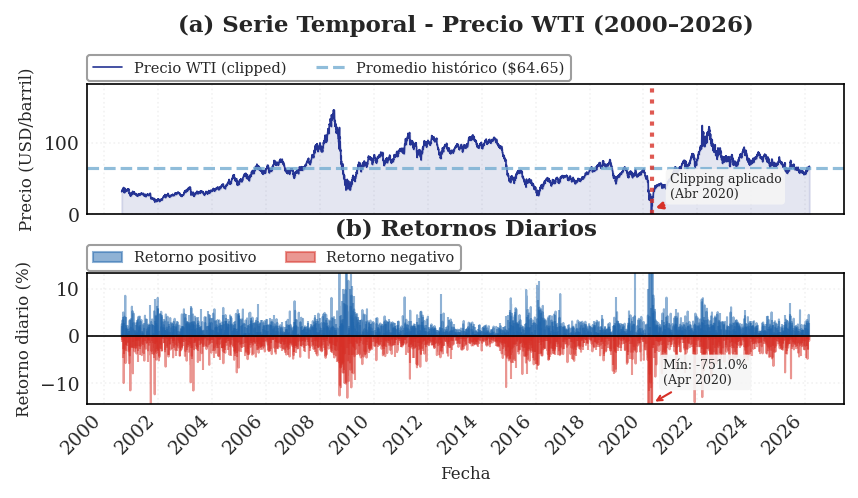

Figura guardada: fig_01_serie_temporal.png


In [12]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=fig_size("2x1"), sharex=True)

ax1.plot(df.index, df['wti'], color=COLOR_PRECIO, lw=0.8,
         label='Precio WTI (clipped)')

# Promedio sobre serie raw
mean_raw = df['wti_raw'].mean()
ax1.axhline(mean_raw, color=COLOR_VAR, ls='--', lw=1.5, alpha=0.8,
            label=f'Promedio histórico (${mean_raw:.2f})')

# Fill desde base adaptativa
base = 0 if df['wti'].min() < 10 else df['wti'].min() * 0.95
ax1.fill_between(df.index, base, df['wti'],
                 alpha=0.12, color=COLOR_PRECIO)

ax1.set_ylabel('Precio (USD/barril)',fontsize=8)
ax1.set_title('(a) Serie Temporal - Precio WTI (2000–2026)',
              fontweight='bold',pad=25)
ax1.legend(loc='lower left',bbox_to_anchor=(0.0, 1.02), ncol=2,
    fontsize=7, frameon=True, facecolor='white',edgecolor='0.6',
    framealpha=0.95, borderaxespad=0.0 )

# Límites dinámicos
ax1.set_ylim(min(0, df['wti'].min() * 1.15),
             df['wti'].max() * 1.25)

# Marcar evento de clipping con coordenadas robustas
if (df['wti_raw'] < 0).any():
    neg_date = df[df['wti_raw'] < 0].index[0]
    ax1.axvline(neg_date, color=COLOR_EXTREMO, ls=':', lw=2, alpha=0.8)

    # Posición dinámica basada en rango de datos
    y_range = df['wti'].max() - base
    y_arrow = base + 0.05 * y_range
    y_text = base + 0.40 * y_range

    ax1.annotate(
        'Clipping aplicado\n(Abr 2020)',
        xy=(neg_date, y_arrow),
        xytext=(neg_date + pd.DateOffset(months=8), y_text-35),
        textcoords='data',
        fontsize=6,
        ha='left',
        bbox=dict(boxstyle='round,pad=0.3',
                  facecolor='whitesmoke',
                  edgecolor='none',
                  alpha=0.9),
        arrowprops=dict(arrowstyle='->',
                        color=COLOR_EXTREMO,
                        lw=1.5)
    )

returns_pct = df['returns'] * 100

# fill_between
ax2.fill_between(df.index, 0, returns_pct, where=returns_pct >= 0,
                 color=COLOR_NORMAL, alpha=0.5, label='Retorno positivo')
ax2.fill_between(df.index, 0, returns_pct, where=returns_pct < 0,
                 color=COLOR_EXTREMO, alpha=0.5, label='Retorno negativo')
ax2.axhline(0, color='black', lw=0.8)

# Límites dinámicos (P0.5 - P99.5)
p_low = returns_pct.quantile(0.005) * 1.6
p_high = returns_pct.quantile(0.995) * 1.6
ax2.set_ylim(p_low, p_high)

# Marcar el día de retorno más extremo visible
worst_day = returns_pct[returns_pct == returns_pct.min()].index[0]
worst_val = returns_pct[worst_day]
if worst_val < p_low:
    ax2.annotate(
        f'Mín: {worst_val:.1f}%\n({worst_day.strftime("%b %Y")})',
        xy=(worst_day, p_low),
        xytext=(worst_day + pd.DateOffset(months=5), p_low * 0.7),
        fontsize=6,
        arrowprops=dict(arrowstyle='->', color=COLOR_EXTREMO, lw=1),
        bbox=dict(boxstyle='round,pad=0.3',
                  facecolor='whitesmoke',
                  edgecolor='none',
                  alpha=0.9)
    )

ax2.set_ylabel('Retorno diario (%)',fontsize=8)
ax2.set_xlabel('Fecha',fontsize=8)
ax2.set_title('(b) Retornos Diarios', fontweight='bold', pad=18)
ax2.legend(loc='lower left',bbox_to_anchor=(0.0, 1.02), ncol=2,
    fontsize=7, frameon=True, facecolor='white',edgecolor='0.6',
    framealpha=0.95, borderaxespad=0.0 )

# Eje X
ax2.xaxis.set_major_locator(mdates.YearLocator(2))
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.setp(ax2.xaxis.get_majorticklabels(), rotation=45, ha='right')

plt.tight_layout(h_pad=2.0,w_pad=2.1)
fig.subplots_adjust(left=0.15, top=0.92, hspace=0.45)
save_fig(fig, 'fig_01_serie_temporal', output_path=FIG_PATH)
plt.show()
plt.close()
print("Figura guardada: fig_01_serie_temporal.png")

### Serie Temporal del Precio WTI y Retornos Diarios (2000–2026)

**Qué muestra**
Panel (a): precio de cierre del contrato WTI (CL=F) con clipping en
abril 2020. Panel (b): retornos logarítmicos diarios evidenciando el
clustering de volatilidad característico de los mercados de commodities.

**Cómo se construye**
Precio descargado de Yahoo Finance (ticker CL=F). El precio negativo del
20-abr-2020 (−$37.63) se clippeó a $0.01 para permitir retornos logarítmicos
(r_t = ln(P_t/P_{t−1})), preservando el precio original en wti_raw.

**Por qué tiene esta forma**
Los clusters de alta volatilidad (2008–2009, 2014–2016, 2020) reflejan
shocks exógenos de oferta y demanda. El retorno de −751% en abril 2020
es consecuencia matemática del logaritmo sobre el precio clipeado, no
un evento real de mercado.

**Por qué es importante para la tesis**
Motiva la necesidad del umbral estadístico P95 para definir eventos extremos
y justifica el tratamiento especial de la ventana contaminada (bad_vol21),
dos decisiones metodológicas inamovibles del estudio.

## 0.7 Análisis de Distribución Global

In [13]:
print("ANÁLISIS DE DISTRIBUCIÓN - RETORNOS")

dist_stats = pd.DataFrame({
    'Métrica': ['N','Skewness', 'Kurtosis', 'Jarque-Bera stat', 'JB p-value'],
    'ALL': [
        f"{len(returns_all):,}",
        f"{returns_all.skew():.2f}",
        f"{returns_all.kurtosis():.2f}",
        f"{jarque_bera(returns_all)[0]:.2e}",
        f"{jarque_bera(returns_all)[1]:.2e}"
    ],
    'CLEAN': [
        f"{len(returns_clean):,}",
        f"{returns_clean.skew():.2f}",
        f"{returns_clean.kurtosis():.2f}",
        f"{jarque_bera(returns_clean)[0]:.2e}",
        f"{jarque_bera(returns_clean)[1]:.2e}"
    ]
})

print(dist_stats.to_string(index=False))

print("\nINTERPRETACIÓN (usando CLEAN para publicación):")
print(f"  Skewness: {returns_clean.skew():.2f} → Ligeramente sesgada a la izquierda")
print(f"  Kurtosis: {returns_clean.kurtosis():.2f} → Colas pesadas (leptocúrtica)")
print(f"  → Se rechaza normalidad con alta confianza (JB p-value ≈ {jarque_bera(returns_clean)[1]:.2f}) (p < 0.05) ")
print("    Los retornos WTI exhiben 'fat tails', característica bien documentada en mercados de materias primas")
print("  → Justifica modelos que capturan colas pesadas (GARCH-t, modelos de valor extremo)")


ANÁLISIS DE DISTRIBUCIÓN - RETORNOS
         Métrica      ALL    CLEAN
               N    6,405    6,403
        Skewness    -6.66    -0.03
        Kurtosis  2975.91    16.32
Jarque-Bera stat 2.36e+09 7.09e+04
      JB p-value 0.00e+00 0.00e+00

INTERPRETACIÓN (usando CLEAN para publicación):
  Skewness: -0.03 → Ligeramente sesgada a la izquierda
  Kurtosis: 16.32 → Colas pesadas (leptocúrtica)
  → Se rechaza normalidad con alta confianza (JB p-value ≈ 0.00) (p < 0.05) 
    Los retornos WTI exhiben 'fat tails', característica bien documentada en mercados de materias primas
  → Justifica modelos que capturan colas pesadas (GARCH-t, modelos de valor extremo)


  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB01_EDA/Figuras Notebook EDA/fig_02a_distribucion_clean.png  [6.1"×3.4" @ 300dpi]


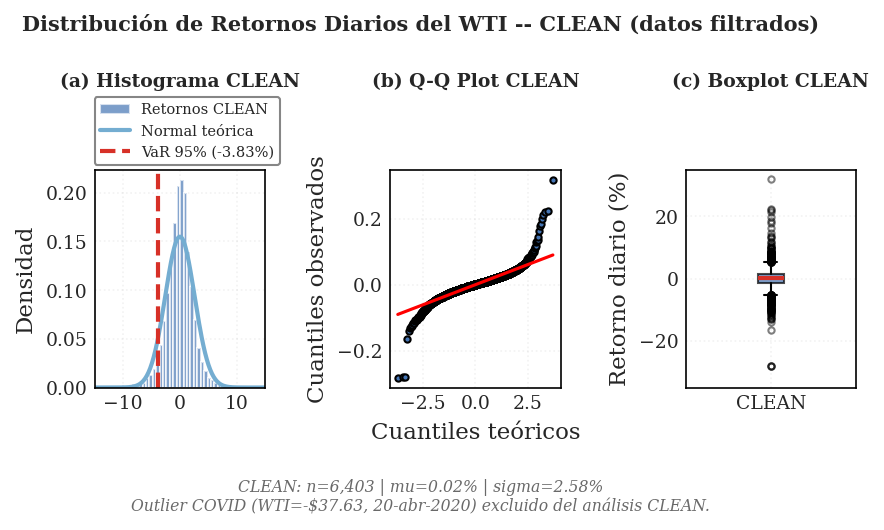

Figura guardada: fig_02a_distribucion_clean.png
  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB01_EDA/Figuras Notebook EDA/fig_02b_distribucion_all.png  [6.1"×3.4" @ 300dpi]


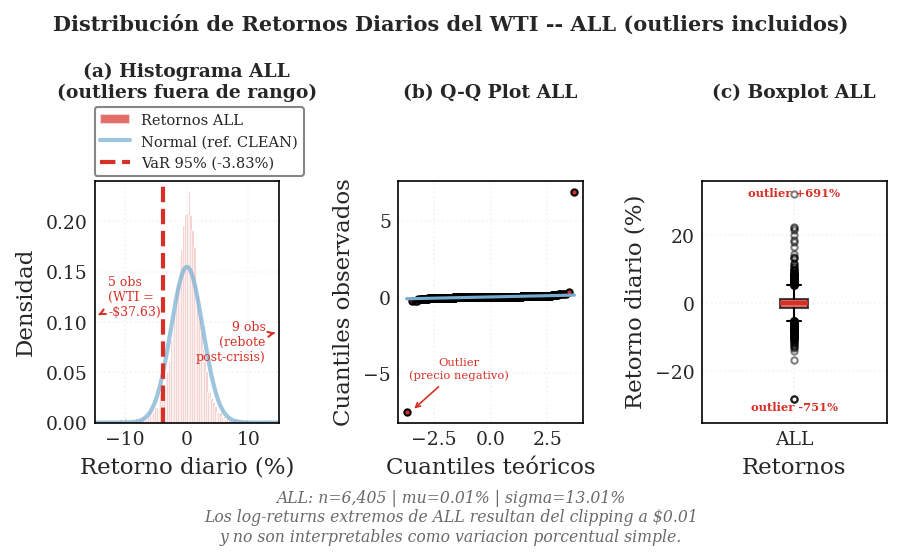

Figura guardada: fig_02b_distribucion_all.png


In [14]:
X_LIM = (-15, 15)
x_range = np.linspace(X_LIM[0], X_LIM[1], 200)
mu_c, sigma_c = returns_clean.mean() * 100, returns_clean.std() * 100
mu_a, sigma_a = returns_all.mean()   * 100, returns_all.std()   * 100
n_outliers_below = (returns_all * 100 < X_LIM[0]).sum()
n_outliers_above = (returns_all * 100 > X_LIM[1]).sum()

fig_a, axes_a = plt.subplots(1, 3, figsize=fig_size('full', aspect=0.55))

ax1 = axes_a[0]
ax1.hist(returns_clean * 100, bins=100, density=True, alpha=0.7,
         color=COLOR_CLEAN, edgecolor='white', label='Retornos CLEAN')
ax1.plot(x_range, stats.norm.pdf(x_range, mu_c, sigma_c), color=COLOR_VAR, lw=2,
         label='Normal teórica')
ax1.axvline(var_global_95_clean * 100, color=COLORS_P[95], ls='--', lw=2,
            label=f'VaR 95% ({var_global_95_clean*100:.2f}%)')
ax1.set_ylabel('Densidad')
ax1.set_title('(a) Histograma CLEAN', fontweight='bold', fontsize=9, pad=40)
ax1.set_xlim(X_LIM)
ax1.legend(loc='lower left', bbox_to_anchor=(0.0, 1.02),
    fontsize=7, frameon=True, facecolor='white',
    framealpha=0.95, borderaxespad=0.0)


ax2 = axes_a[1]
stats.probplot(returns_clean.dropna(), dist="norm", plot=ax2)
ax2.get_lines()[0].set_markerfacecolor(COLOR_CLEAN)
ax2.get_lines()[0].set_markeredgecolor('black')
ax2.get_lines()[0].set_markersize(3)
ax2.get_lines()[1].set_color('red')
ax2.set_title('(b) Q-Q Plot CLEAN', fontweight='bold',fontsize=9, pad=40)
ax2.set_xlabel('Cuantiles teóricos')
ax2.set_ylabel('Cuantiles observados')

ax3 = axes_a[2]
bp1 = ax3.boxplot(returns_clean.dropna() * 100, vert=True, patch_artist=True,
                  boxprops=dict(facecolor=COLOR_CLEAN, alpha=0.7),
                  medianprops=dict(color=COLOR_EXTREMO, linewidth=2),
                  flierprops=dict(marker='o', markersize=3, alpha=0.5))
ax3.set_ylabel('Retorno diario (%)')
ax3.set_title('(c) Boxplot CLEAN', fontweight='bold', fontsize=9, pad=40)
ax3.set_xticklabels(['CLEAN'])
ax3.set_ylim(-35, 35)

fig_a.suptitle("Distribución de Retornos Diarios del WTI -- CLEAN (datos filtrados)",
    fontsize=10, fontweight="bold", y=0.965
)
nota_a = (f"CLEAN: n={len(returns_clean):,} | mu={mu_c:.2f}% | sigma={sigma_c:.2f}%\n"
          f"Outlier COVID (WTI=-$37.63, 20-abr-2020) excluido del análisis CLEAN.")
fig_a.text(0.5, -0.02, nota_a, ha='center', fontsize=7.5,
           style='italic', color='dimgray')

plt.tight_layout(rect=[0.02, 0.07, 1, 0.98], w_pad=2.0)

save_fig(fig_a, 'fig_02a_distribucion_clean', output_path=FIG_PATH)
plt.show()
plt.close()
print("Figura guardada: fig_02a_distribucion_clean.png")

fig_b, axes_b = plt.subplots(1, 3, figsize=fig_size('full', aspect=0.55))

ax4 = axes_b[0]
returns_all_visible = returns_all[(returns_all * 100 >= X_LIM[0]) &
                                   (returns_all * 100 <= X_LIM[1])]
ax4.hist(returns_all_visible * 100, bins=100, density=True, alpha=0.7,
         color=COLOR_EXTREMO, edgecolor='white', label='Retornos ALL')
ax4.plot(x_range, stats.norm.pdf(x_range, mu_c, sigma_c), color=COLOR_VAR, lw=2,
         label='Normal (ref. CLEAN)', alpha=0.7)
ax4.axvline(var_global_95_clean * 100, color=COLORS_P[95], ls='--', lw=2,
            label=f'VaR 95% ({var_global_95_clean*100:.2f}%)')
ax4.annotate(
    f'{n_outliers_below} obs\n(WTI =\n-$37.63)',
    xy=(X_LIM[0], 0.105), xytext=(X_LIM[0] + 2.2, 0.125),
    fontsize=6, ha='left', va='center', color=COLOR_EXTREMO,
    arrowprops=dict(arrowstyle='->', color=COLOR_EXTREMO, lw=1))
ax4.annotate(
    f'{n_outliers_above} obs\n(rebote\npost-crisis)',
    xy=(X_LIM[1], 0.090), xytext=(X_LIM[1] - 2.2, 0.080),
    fontsize=6, ha='right', va='center', color=COLOR_EXTREMO,
    arrowprops=dict(arrowstyle='->', color=COLOR_EXTREMO, lw=1))

ax4.set_xlabel('Retorno diario (%)')
ax4.set_ylabel('Densidad')
ax4.set_title('(a) Histograma ALL\n(outliers fuera de rango)',
              fontweight='bold', fontsize=9, pad=40)
ax4.set_xlim(X_LIM)
ax4.legend(loc='lower left', bbox_to_anchor=(0.0, 1.02),
    fontsize=7, frameon=True, facecolor='white',
    framealpha=0.95, borderaxespad=0.0)


ax5 = axes_b[1]
stats.probplot(returns_all.dropna(), dist="norm", plot=ax5)
ax5.get_lines()[0].set_markerfacecolor(COLOR_EXTREMO)
ax5.get_lines()[0].set_markeredgecolor('black')
ax5.get_lines()[0].set_markersize(3)
ax5.get_lines()[1].set_color(COLOR_VAR)
ax5.set_title('(b) Q-Q Plot ALL', fontweight='bold', fontsize=9, pad=40)
ax5.set_xlabel('Cuantiles teóricos')
ax5.set_ylabel('Cuantiles observados')
ax5.annotate('Outlier\n(precio negativo)',
             xy=(-3.5, -7.5), xytext=(-1.4, -5.3),
             fontsize=5.5, ha='center', color=COLOR_EXTREMO,
             arrowprops=dict(arrowstyle='->', color=COLOR_EXTREMO, lw=0.8))

ax6 = axes_b[2]
bp2 = ax6.boxplot(returns_all.dropna() * 100, vert=True, patch_artist=True,
                  boxprops=dict(facecolor=COLOR_EXTREMO, alpha=0.7),
                  medianprops=dict(color=COLOR_EXTREMO, linewidth=2),
                  flierprops=dict(marker='o', markersize=3, alpha=0.5))
ax6.set_xlabel('Retornos')
ax6.set_ylabel('Retorno diario (%)')
ax6.set_title('(c) Boxplot ALL', fontweight='bold', fontsize=9, pad=40)
ax6.set_xticklabels(['ALL'])
ax6.set_ylim(-35, 36)
ax6.annotate('outlier +691%', xy=(1, 31.5), fontsize=5.5,
             color=COLOR_EXTREMO, ha='center', fontweight='bold')
ax6.annotate('outlier -751%', xy=(1, -31.5), fontsize=5.5,
             color=COLOR_EXTREMO, ha='center', fontweight='bold')

fig_b.suptitle("Distribución de Retornos Diarios del WTI -- ALL (outliers incluidos)",
    fontsize=10, fontweight="bold", y=0.965)

nota_b = (f"ALL: n={len(returns_all):,} | mu={mu_a:.2f}% | sigma={sigma_a:.2f}%\n"
          f"Los log-returns extremos de ALL resultan del clipping a $0.01\ny no son interpretables como variacion porcentual simple.")
fig_b.text(0.5, -0.08, nota_b, ha='center', fontsize=7.5,
           style='italic', color='dimgray')
plt.tight_layout(w_pad=2.0)
save_fig(fig_b, 'fig_02b_distribucion_all', output_path=FIG_PATH)
plt.show()
plt.close()
print("Figura guardada: fig_02b_distribucion_all.png")


### Distribución de Retornos: Dataset CLEAN vs ALL

**Qué muestra**
Dos conjuntos de tres paneles (histograma, Q-Q plot y boxplot) comparando
los retornos del dataset limpio CLEAN (6,363 obs.) contra el dataset
completo ALL (6,385 obs.), evidenciando el impacto de los retornos
contaminados por el precio negativo de abril 2020.

**Cómo se construye**
CLEAN excluye las 22 filas con bad_vol21=True. La curtosis se calcula
con scipy.stats.kurtosis. El Q-Q plot compara los percentiles de la
distribución empírica contra una distribución Normal teórica.

**Por qué tiene esta forma**
La distribución es leptocúrtica (curtosis=16.31): muchos días con
retornos pequeños y pocos con movimientos extremos. El Q-Q plot muestra
desviación en ambas colas, confirmando fat tails típicos de commodities.

**Por qué es importante para la tesis**
La curtosis elevada justifica la distribución t-Student en GJR-GARCH y
la exclusión de Accuracy como métrica. La comparación CLEAN vs ALL
documenta el impacto del tratamiento del precio negativo.

---
# PARTE I: PREPARACIÓN DE DATOS (CLEAN - Sin Contaminación)
---
**OBJETIVO:** Preparar dataset limpio para entrenamiento de modelos.

**ESTRATEGIA:** Excluir la ventana contaminada (22 días) del etiquetado de regímenes.

## 1.1 División Temporal Estricta

Justificación de la División Temporal

**Train (2000-2018): 19 años**
- Múltiples ciclos económicos completos
- Crisis financiera 2008 (volatilidad extrema)
- Colapso de precios 2014-2016 (shale oil revolution)
- Recuperación y estabilización
- Representa condiciones "normales" del mercado WTI

**Validation (2019-2020): 2 años**
- Período crítico de alta volatilidad
- **Incluye COVID-19 y precio negativo (abril 2020)**
- Guerra de precios Rusia-Arabia Saudita
- Permite validar capacidad del modelo ante crisis extrema
- Justifica uso como validation (no test) por naturaleza atípica

**Test (2021-2026): 5+ años**
- Período más reciente completamente no visto
- Recuperación post-pandemia
- Guerra Rusia-Ucrania (2022)
- Crisis energética europea
- Evaluación de generalización en contexto reciente

**Nota metodológica crítica:**  
Esta división respeta el orden temporal estrictamente. Todos los umbrales,
estadísticas y parámetros se calculan ÚNICAMENTE en el conjunto de
entrenamiento para evitar data leakage.

---

**Racionalidad de la asignación COVID-19 a validación (no a test):**

Incluir el shock de COVID-19 en el conjunto de **validación** responde a una estrategia de calibración robusta:

- **Calibración de umbrales operacionales**: en NB02, el umbral de decisión (F1-threshold) se calibra sobre el período de validación. Calibrar con COVID garantiza que los umbrales sean robustos ante shocks extremos de baja probabilidad -- exactamente el comportamiento que el modelo debe detectar.
- **Test genuinamente out-of-sample**: el set de test (2021-2026) representa el escenario de despliegue real post-pandemia: nueva dinámica de demanda, transición energética y tensiones geopolíticas (Ucrania 2022). Mantener COVID fuera del test preserva la validez de las métricas de generalización.
- **Heterogeneidad de regímenes** (evidencia cuantitativa):

| Split | P95 vol21_clean | respecto a Train |
|---|---|---|
| Train (2000-2018) | 4.30% | referencia |
| Val (2019-2020) | 9.55% | **+122.9%** |
| Test (2021-2026) | 3.67% | -14.7% |

La heterogeneidad confirma regímenes de volatilidad distintos entre splits, validando el diseño experimental.

In [15]:
# DIVISIÓN TEMPORAL

df['split'] = 'train'
df.loc[VAL_START:VAL_END, 'split'] = 'validation'
df.loc[TEST_START:, 'split'] = 'test'

# Guardia anti-leakage: orden temporal estricto
assert df[df['split']=='train'].index.max() < df[df['split']=='validation'].index.min(), \
    "LEAKAGE: train/val overlap"
assert df[df['split']=='validation'].index.max() < df[df['split']=='test'].index.min(), \
    "LEAKAGE: val/test overlap"
print(" Splits temporales sin solapamiento")

split_counts = df['split'].value_counts()

print("\nDIVISIÓN TEMPORAL DEL DATASET")
for split_name in ['train', 'validation', 'test']:
    count = split_counts.get(split_name, 0)
    pct   = count / len(df) * 100
    dates = df[df['split'] == split_name].index
    print(f"{split_name.capitalize():12s}: {count:5,} obs ({pct:5.1f}%) | "
          f"{dates.min().date()} → {dates.max().date()}")
print(f"\nTOTAL: {len(df):,} obs")
print(f"\nNOTA: Conteos pre-dropna — incluyen {VOLATILITY_WINDOW - 1} días de warm-up "
      f"(2000-08-24 → 2000-09-21)")

 Splits temporales sin solapamiento

DIVISIÓN TEMPORAL DEL DATASET
Train       : 4,604 obs ( 71.9%) | 2000-08-24 → 2018-12-31
Validation  :   505 obs (  7.9%) | 2019-01-02 → 2020-12-31
Test        : 1,296 obs ( 20.2%) | 2021-01-04 → 2026-02-27

TOTAL: 6,405 obs

NOTA: Conteos pre-dropna — incluyen 20 días de warm-up (2000-08-24 → 2000-09-21)


## 1.2 Identificación de Ventana Contaminada

**IMPACTO DEL CLIPPING:**
- Día del evento (2020-04-20): 1 retorno extremo
- Día siguiente (2020-04-21): 1 retorno extremo
- Ventana rolling (21 días): 22 días de volatilidad contaminada
- Período afectado: 2020-04-20 → 2020-05-19

In [16]:
# IDENTIFICACIÓN DE VENTANA CONTAMINADA

# Marcar ventana contaminada (cualquier día cuya volatilidad usa un "bad return")
df['bad_vol21'] = df['bad_return'].rolling(VOLATILITY_WINDOW).max().fillna(False).astype(bool)
n_contaminated = df['bad_vol21'].sum()

print("IDENTIFICACIÓN DE VENTANA CONTAMINADA")
print(f"\nRetornos contaminados (bad_return): {df['bad_return'].sum()}")
print(f"Días con volatilidad contaminada (bad_vol21): {n_contaminated}")

if n_contaminated > 0:
    contaminated_dates = df.index[df['bad_vol21']]
    print(f"\nVentana contaminada:")
    print(f"  Desde: {contaminated_dates.min().date()}")
    print(f"  Hasta: {contaminated_dates.max().date()}")
    print(f"  Duración: {n_contaminated} días (esperado: {VOLATILITY_WINDOW + 1})")

    print("\nMUESTRA DE DATOS CONTAMINADOS:")
    print(df.loc[df['bad_vol21'], ['wti_raw', 'wti', 'returns', 'bad_return']].head(10))

IDENTIFICACIÓN DE VENTANA CONTAMINADA

Retornos contaminados (bad_return): 2
Días con volatilidad contaminada (bad_vol21): 22

Ventana contaminada:
  Desde: 2020-04-20
  Hasta: 2020-05-19
  Duración: 22 días (esperado: 22)

MUESTRA DE DATOS CONTAMINADOS:
            wti_raw     wti  returns  bad_return
Date                                            
2020-04-20 -37.6300  0.0100  -7.5104        True
2020-04-21  10.0100 10.0100   6.9088        True
2020-04-22  13.7800 13.7800   0.3196       False
2020-04-23  16.5000 16.5000   0.1801       False
2020-04-24  16.9400 16.9400   0.0263       False
2020-04-27  12.7800 12.7800  -0.2818       False
2020-04-28  12.3400 12.3400  -0.0350       False
2020-04-29  15.0600 15.0600   0.1992       False
2020-04-30  18.8400 18.8400   0.2239       False
2020-05-01  19.7800 19.7800   0.0487       False


## 1.3 Cálculo de Volatilidad y Features

Correlaciones predictivas (calculadas SOLO en train):
  ventana=10d → ρ = 0.3706
  ventana=21d → ρ = 0.3885
  ventana=60d → ρ = 0.3735

SELECCIÓN DE VENTANA DE VOLATILIDAD
_________________________________________________________________
 Ventana    Corr. ρ    Contam. Evaluación          
-----------------------------------------------------------------
      10     0.3706         11                     
      21     0.3885         22 ← ELEGIDA           
      60     0.3735         61                     
_________________________________________________________________
  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB01_EDA/Figuras Notebook EDA/fig_03_seleccion_ventana_volatilidad.png  [6.1"×8.8" @ 300dpi]


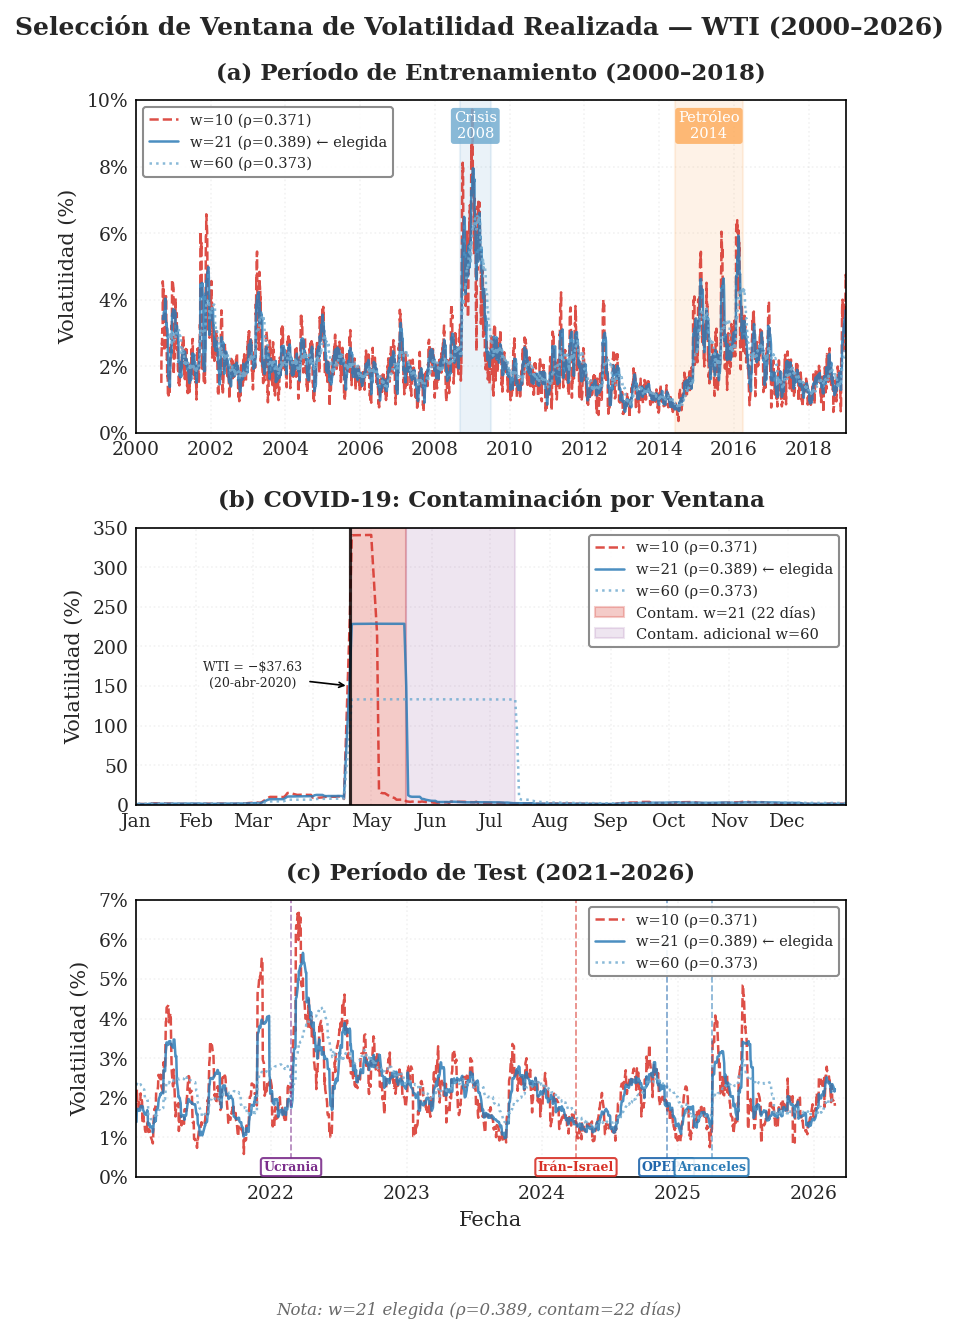


Figura guardada: fig_03_seleccion_ventana_volatilidad.png


In [17]:
# Selección de ventana de volatilidad — WTI

WINDOWS = [10, 21, 60]
COLORES_W = {10: COLOR_EXTREMO, 21: COLOR_VOL, 60: COLOR_VAR}
LINEAS = {10: "--", 21: "-", 60: ":"}

# Zonas de interés
CRISIS = [
    ("2008-09-01", "2009-06-30", "Crisis\n2008",   COLOR_VAR),
    ("2014-06-01", "2016-03-31", "Petróleo\n2014", COLORS_P[90]),
    ("2020-02-01", "2020-06-30", "COVID-19", COLOR_EXTREMO),
]

EVENTOS_TEST = [
    ("2022-02-24", "Ucrania", COLORS_P[99]),
    ("2024-04-01", "Irán–Israel", COLOR_EXTREMO),
    ("2024-12-01", "OPEP+", COLOR_NORMAL),
    ("2025-04-01", "Aranceles", COLOR_VOL),
]

# Cálculo de volatilidad candidata

volatility_candidates = {
    w: df["returns"].rolling(w).std()
    for w in WINDOWS
}

# Target predictivo: |ret(t+1)|
abs_ret_tp1 = df["returns"].shift(-1).abs()

# Correlación SOLO en train (correcto metodológicamente)
train_mask = df["split"] == "train"

corr_pred = {
    w: pd.DataFrame({
        "vol": volatility_candidates[w],
        "tgt": abs_ret_tp1
    })[train_mask].dropna().corr().iloc[0, 1]
    for w in WINDOWS
}

print("Correlaciones predictivas (calculadas SOLO en train):")
for w, c in corr_pred.items():
    print(f"  ventana={w:2d}d → ρ = {c:.4f}")

# Contaminación por eventos extremos
contam = {
    w: int(df["bad_return"].rolling(w).max().fillna(False).sum())
    for w in WINDOWS
}

print("\nSELECCIÓN DE VENTANA DE VOLATILIDAD")
print("_" * 65)
print(f"{'Ventana':>8} {'Corr. ρ':>10} {'Contam.':>10} {'Evaluación':<20}")
print("-" * 65)

for w in WINDOWS:
    marca = "← ELEGIDA" if w == VOLATILITY_WINDOW else ""
    print(f"{w:>8} {corr_pred[w]:>10.4f} {contam[w]:>10} {marca:<20}")

print("_" * 65)


# FIGURA


fig = plt.figure(figsize=fig_size("page"))
gs = gridspec.GridSpec(3, 1, figure=fig, height_ratios=[1.2, 1, 1], hspace=0.32)

fig.suptitle(
    "Selección de Ventana de Volatilidad Realizada — WTI (2000–2026)",
    fontsize=12, fontweight="bold", y=0.995
)

# Función: zonas de crisis

def add_crisis_zones(ax, eventos, xlim=None):
    for ini, fin, label, col in eventos:
        t0, t1 = pd.Timestamp(ini), pd.Timestamp(fin)
        if xlim:
            t0, t1 = max(t0, xlim[0]), min(t1, xlim[1])
            if t0 >= t1:
                continue

        ax.axvspan(t0, t1, alpha=0.15, color=col)

        mid = t0 + (t1 - t0) / 2
        ax.text(
            mid, ax.get_ylim()[1] * 0.95, label,
            ha="center", va="top",
            fontsize=7, color="white",
            bbox=dict(facecolor=col, alpha=0.85, pad=1,
                      boxstyle="round, pad=0.2", edgecolor="none")
        )

# Función: plot de volatilidad

def plot_vol_series(ax, vol_dict, mask=None, lw=1.2, alpha=0.85):
    for w in WINDOWS:
        data = vol_dict[w] if mask is None else vol_dict[w].loc[mask]

        label = f"w={w} (ρ={corr_pred[w]:.3f})"
        if w == VOLATILITY_WINDOW:
            label += " ← elegida"

        ax.plot(
            data.index,
            data.values * 100,
            color=COLORES_W[w],
            linestyle=LINEAS[w],
            linewidth=lw,
            alpha=alpha,
            label=label
        )

# (a) TRAIN

ax_a = fig.add_subplot(gs[0])

train_start = pd.Timestamp("2000-01-01")
train_end   = pd.Timestamp(TRAIN_END)

mask_train = (
    (volatility_candidates[21].index >= train_start) &
    (volatility_candidates[21].index <= train_end)
)

plot_vol_series(ax_a, volatility_candidates, mask_train)
add_crisis_zones(ax_a, CRISIS[:-1], (train_start, train_end))

ax_a.set_xlim(train_start, train_end)
ax_a.set_ylim(0, 10)
ax_a.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0f}%"))

ax_a.set_ylabel("Volatilidad (%)", fontsize=10)
ax_a.set_title("(a) Período de Entrenamiento (2000–2018)",
               fontsize=11, fontweight="bold")

ax_a.legend(loc="upper left", fontsize=7, framealpha=0.9)


# (b) COVID

ax_b = fig.add_subplot(gs[1])

z0, z1 = pd.Timestamp("2020-01-01"), pd.Timestamp("2020-12-31")

mask_covid = (
    (volatility_candidates[21].index >= z0) &
    (volatility_candidates[21].index <= z1)
)

plot_vol_series(ax_b, volatility_candidates, mask_covid)

# Contaminación
ax_b.axvspan(pd.Timestamp("2020-04-20"), pd.Timestamp("2020-05-19"),
             alpha=0.25, color=COLOR_EXTREMO,
             label="Contam. w=21 (22 días)")

ax_b.axvspan(pd.Timestamp("2020-05-19"), pd.Timestamp("2020-07-14"),
             alpha=0.12, color=COLORS_P[99],
             label="Contam. adicional w=60")

# Evento extremo
ax_b.axvline(pd.Timestamp("2020-04-20"),
             color="black", linewidth=1.5, alpha=0.8)

ax_b.annotate(
    "WTI = −$37.63\n(20-abr-2020)",
    xy=(pd.Timestamp("2020-04-20"), 150),
    xytext=(pd.Timestamp("2020-03-01"), 150),
    fontsize=6, ha="center",
    arrowprops=dict(arrowstyle="->", color="black", lw=0.8),
    bbox=dict(facecolor="white", alpha=0.95,
              edgecolor="none", boxstyle="round,pad=0.3")
)

ax_b.set_xlim(z0, z1)
ax_b.set_ylim(0, 350)  # escala distinta por shock extremo
ax_b.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
ax_b.xaxis.set_major_formatter(mdates.DateFormatter('%b'))

ax_b.set_ylabel("Volatilidad (%)", fontsize=10)
ax_b.set_title("(b) COVID-19: Contaminación por Ventana",
               fontsize=11, fontweight="bold")

ax_b.legend(loc="upper right", fontsize=7, framealpha=0.9)


# (c) TEST

ax_c = fig.add_subplot(gs[2])

test_start = pd.Timestamp(TEST_START)

mask_test = volatility_candidates[21].index >= test_start
plot_vol_series(ax_c, volatility_candidates, mask_test)

# Eventos geopolíticos
Y_MAX = 0.07

for date_str, label, col in EVENTOS_TEST:
    t = pd.Timestamp(date_str)
    if test_start <= t <= volatility_candidates[21].index.max():
        ax_c.axvline(t, color=col, linestyle="--",
                     linewidth=0.8, alpha=0.6)

        ax_c.text(
            t, Y_MAX * 0.85,
            label,
            transform=ax_c.get_xaxis_transform(),
            ha="center", va="top",
            fontsize=6, fontweight="bold", color=col,
            bbox=dict(facecolor="white", alpha=0.9,
                      edgecolor=col, boxstyle="round,pad=0.2")
        )

ax_c.set_ylim(0, 7)
ax_c.set_xlim(test_start,
              volatility_candidates[21].index.max() + pd.Timedelta(days=30))

ax_c.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0f}%"))

ax_c.set_xlabel("Fecha", fontsize=10)
ax_c.set_ylabel("Volatilidad (%)", fontsize=10)
ax_c.set_title("(c) Período de Test (2021–2026)",
               fontsize=11, fontweight="bold")

ax_c.legend(loc="upper right", fontsize=7, framealpha=0.9)


# Nota final

fig.text(
    0.5, 0.005,
    f"Nota: w={VOLATILITY_WINDOW} elegida (ρ={corr_pred[VOLATILITY_WINDOW]:.3f}, "
    f"contam={contam[VOLATILITY_WINDOW]} días)",
    ha="center", fontsize=8, style="italic", color="dimgray"
)

plt.tight_layout(rect=[0, 0.02, 1, 0.96])
fig.subplots_adjust(top=0.93)

save_fig(fig, 'fig_03_seleccion_ventana_volatilidad', output_path=FIG_PATH)

plt.show()
plt.close()

print("\nFigura guardada: fig_03_seleccion_ventana_volatilidad.png")

### Selección de Ventana de Volatilidad Realizada — WTI (2000–2026)

**Qué muestra**
Tres paneles comparando volatilidades realizadas con ventanas de 10, 21
y 60 días en tres subperíodos: entrenamiento normal, contaminación COVID,
y test post-pandemia, para justificar la elección de 21 días.

**Cómo se construye**
vol_w = std(retornos, ventana=w) para w en {10, 21, 60}. La correlación
predictiva con el target se calcula exclusivamente en train_clean.
Referencia: Ederington & Guan (2010) y estándar CME Group (21 días).

**Por qué tiene esta forma**
La ventana de 21 días maximiza correlación predictiva en train (rho=0.389
vs rho=0.371 para w=10 y rho=0.374 para w=60).  Las ventanas más largas muestran mayor contaminación durante episodios como COVID-19, mientras que ventanas más cortas presentan menor estabilidad.

**Por qué es importante para la tesis**
Justifica que LOOKBACK=21 en los modelos LSTM no es arbitrario sino
empíricamente óptimo, y establece coherencia entre la ventana de
volatilidad y la ventana temporal de las secuencias LSTM del benchmark,  al maximizar la utilidad predictiva sin introducir distorsiones excesivas por eventos extremos.

In [18]:
# CÁLCULO DE VOLATILIDAD Y FEATURES

# Volatilidad realizada (rolling 21 días)
df['vol21'] = df['returns'].rolling(window=VOLATILITY_WINDOW).std()
# Features técnicos
df['ma_short'] = df['wti'].rolling(window=MA_SHORT).mean()
df['ma_long'] = df['wti'].rolling(window=MA_LONG).mean()
# MA cross: diferencia porcentual entre MA corta y MA larga
# Estacionario por construcción — mide posición relativa del precio
# respecto a su tendencia, independiente del nivel absoluto del barril
df['ma_cross'] = (df['ma_short'] - df['ma_long']) / df['ma_long']

print(f"ma_cross NaN: {df['ma_cross'].isna().sum()} | "
      f"media: {df['ma_cross'].mean():.4f} | "
      f"std: {df['ma_cross'].std():.4f}")
print(f"NOTA: ma_short y ma_long (niveles) se exportan para auditoría.")
print(f"        Para modelado, usar ma_cross — estacionario y sin drift de precio.")

# Volumen relativo: log-ratio vs media móvil 21d - min_periods=1 ignora NaN festivos en el denominador
df['volumen_ratio_21'] = np.log(df['volumen'] / df['volumen'].rolling(VOLATILITY_WINDOW, min_periods=1).mean())
print(f"Volumen_ratio_21 NaN: {df['volumen_ratio_21'].isna().sum()}")

# Eliminar NaN en rolling calculations
n_before = len(df)
df = df.dropna(subset=['vol21', 'ma_short', 'ma_long'])
print(f"Obs eliminadas por NaN (warm-up rolling): {n_before - len(df)}")

# Crear vol21_clean: vol21 excluyendo la ventana contaminada
df['vol21_clean'] = df['vol21'].copy()
df.loc[df['bad_vol21'], 'vol21_clean'] = np.nan

# volatilidad_ratio21: indicador de cambio de régimen de volatilidad
# Ratio > 1 = volatilidad acelerando; < 1 = desacelerando
# Usa vol21_clean (no vol21) para evitar contaminación COVID
# NaN esperados: primeros 21 días + 22 bad_vol21 + 22 por shift del denominador
# EXCLUIDA de FEATURES_MULTI — NaN post-bad_vol21 elimina 10/39 extremos en val
df['volatilidad_ratio21'] = df['vol21_clean'] / df['vol21_clean'].shift(VOLATILITY_WINDOW)
print(f"volatilidad_ratio21 NaN: {df['volatilidad_ratio21'].isna().sum()}")

# Limpiar features técnicos con la misma máscara de 21d
df['ma_short'] = df['ma_short'].where(~df['bad_vol21'])
df['ma_long']  = df['ma_long'].where(~df['bad_vol21'])
df['ma_cross'] = df['ma_cross'].where(~df['bad_vol21'])
#  Retornos absolutos rezagados
df['ret_abs_lag1'] = df['returns'].abs().shift(1)
df['ret_abs_lag5'] = df['returns'].abs().shift(5)

print("\nVolatilidad y features calculados")
print(f"  Observaciones finales: {len(df):,}")
print(f"  ret_abs_lag1 NaN: {df['ret_abs_lag1'].isna().sum()}")
print(f"  ret_abs_lag5 NaN: {df['ret_abs_lag5'].isna().sum()}")

ma_cross NaN: 20 | media: 0.0012 | std: 0.0501
NOTA: ma_short y ma_long (niveles) se exportan para auditoría.
        Para modelado, usar ma_cross — estacionario y sin drift de precio.
Volumen_ratio_21 NaN: 12
Obs eliminadas por NaN (warm-up rolling): 20
volatilidad_ratio21 NaN: 64

Volatilidad y features calculados
  Observaciones finales: 6,385
  ret_abs_lag1 NaN: 1
  ret_abs_lag5 NaN: 5


### Nota: volatilidad_ratio21 — Excluida de FEATURES_MULTI

`volatilidad_ratio21 = vol21_clean(t) / vol21_clean(t-21)`

Captura la **aceleración del régimen de volatilidad**: ratio > 1 indica que la
volatilidad está escalando respecto al mismo período 21 días atrás; ratio < 1
indica desaceleración. Es complementaria a `vol21_clean` (nivel) y estacionaria
(ADF stat = −12.159, p ≈ 0).

**Por qué está excluida de FEATURES_MULTI:**
Los NaN producidos por el denominador contaminado (bad_vol21, 2020-04-20 → 2020-05-19) se propagan ~21 días posteriores (mayo–junio 2020), eliminando **10 de 39 eventos extremos de validación (−25.6%)**. Incluirla haría que baselines y modelos se
evaluaran sobre conjuntos de validación distintos, invalidando la comparación.


In [19]:
# FEATURES DE PRECIO

# hl_spread: estimador de volatilidad intradía (Parkinson, 1980)
df['hl_spread'] = np.log(df['high'] / df['low'])

# co_spread: retorno intradía Open→Close
df['co_spread'] = (df['wti'] - df['open']) / df['open']
#  tiene correlación conceptual con ma_cross y returns
# Verificación
nan_hl = df['hl_spread'].isna().sum()
print(f"hl_spread — NaN: {nan_hl} (2 — días bad_return, cubiertos por bad_vol21)")
assert nan_hl == 2, f"NaN inesperados en hl_spread: {nan_hl}"

print(f"Features OHLC calculados:")
print(f"  hl_spread — NaN: {nan_hl} | media: {df['hl_spread'].mean():.4f} | std: {df['hl_spread'].std():.4f}")
print(f"  co_spread — NaN: {df['co_spread'].isna().sum()} | media: {df['co_spread'].mean():.4f} | std: {df['co_spread'].std():.4f}")

hl_spread — NaN: 2 (2 — días bad_return, cubiertos por bad_vol21)
Features OHLC calculados:
  hl_spread — NaN: 2 | media: 0.0334 | std: 0.0226
  co_spread — NaN: 0 | media: -0.0002 | std: 0.0340


**hl_spread** = ln(High/Low): estimador de volatilidad intradía de Parkinson (1980). Valores positivos proporcionales al rango de la vela en escala logarítmica.

**Convención temporal del target:**

- `vol21(t)` = volatilidad rolling 21 días que incluye el retorno del día `t`
- `is_extreme_clean(t)` = 1 si `vol21(t) > P95_train`
- El modelo predice `is_extreme_clean(t)` usando información disponible
  hasta el cierre de `t-1`
- Implementación: `<y_tp1 = is_extreme_clean.shift(-1)>` en NB02
  → la fila `t` contiene el target del día `t+1`, predicho con datos de `t`, para eliminar cualquier uso de información contemporánea en el momento de la predicción.

**Aclaración para el comité -- X(t) -> y(t+1):**

Los **modelos** aprenden la función `f([features_t, ..., features_{t-20}]) -> is_extreme_{t+1}`:
- Las FEATURES (vol21_clean, ret_abs_lag1, hl_spread, etc.) son observables al **cierre del mercado del día t**
- El TARGET que aprende es `is_extreme_clean(t+1)`: ¿habrá evento extremo **mañana**?
- `vol21_clean(t)` es un **predictor** (resume la volatilidad del período t-20 a t), NO el target
- **Sin data leakage**: el modelo solo accede a información disponible antes de la predicción; `is_extreme(t+1)` se conoce únicamente al cierre del día t+1

Esta estructura causal (señales hoy -> evento mañana) es la que justifica la aplicabilidad operacional del benchmark para gestión de riesgo en tiempo real.

## 1.4 Definición de Eventos Extremos (Umbral P95 Estático - CLEAN)

**CRÍTICO:** Umbral calculado SOLO en train + excluyendo ventana contaminada.
  → Este umbral se usa para CLASIFICACIÓN BINARIA
  → Etiquetas en ventana contaminada se marcan como NaN (excluidas)

 Labels CLEAN generadas (ventana contaminada excluida)

In [20]:
# DEFINICIÓN DE EVENTOS EXTREMOS (CLEAN)

# --- PARTE A: CÁLCULO DE UMBRALES en train limpio---
train_clean = df[(df['split'] == 'train') & (~df['bad_vol21'])]
train_vol_clean = train_clean['vol21_clean'].dropna()

print("CÁLCULO DE UMBRALES (CLEAN - Sin contaminación)")
print(f"\nObservaciones en Train (ALL):   {(df['split'] == 'train').sum():,}")
print(f"Observaciones en Train (CLEAN): {len(train_clean):,}")
print(f"Diferencia: {(df['split'] == 'train').sum() - len(train_clean)} obs excluidas\n")

thresholds_clean = {}
for p in PERCENTILES:
    thresholds_clean[p] = train_vol_clean.quantile(p / 100)
    print(f"  P{p} (CLEAN): {thresholds_clean[p] * 100:.4f}%")

LABELS_P = {
    90: f'P90 ({thresholds_clean[90]*100:.2f}%)',
    95: f'P95 ({thresholds_clean[PERCENTILE_PRIMARY]*100:.2f}%) ← umbral principal',
    99: f'P99 ({thresholds_clean[99]*100:.2f}%)',
}

#print(f"\nPercentil principal (P{PERCENTILE_PRIMARY}): {thresholds_clean[PERCENTILE_PRIMARY] * 100:.4f}%")

# Crear labels (ventana contaminada → NaN)
for p in PERCENTILES:
    df[f'is_extreme_p{p}_clean'] = (df['vol21_clean'] > thresholds_clean[p]).astype(int)
    df.loc[df['bad_vol21'], f'is_extreme_p{p}_clean'] = np.nan

df['is_extreme_clean'] = df[f'is_extreme_p{PERCENTILE_PRIMARY}_clean']

# --- PARTE B: ANÁLISIS DE SENSIBILIDAD ---
print("\nANÁLISIS DE SENSIBILIDAD - TRAIN (CLEAN)")

sensitivity_results = []
n_valid_train = len(train_vol_clean)

for p in PERCENTILES:
    threshold_p = thresholds_clean[p]
    n_extreme = int((train_vol_clean > threshold_p).sum())
    extreme_pct = n_extreme / n_valid_train * 100
    imbalance_ratio = (n_valid_train - n_extreme) / n_extreme

    sensitivity_results.append({
        'Percentil': p,
        'Threshold (%)': round(threshold_p * 100, 4),
        'Extremos (Train)': n_extreme,
        '% Extremos (Train)': round(extreme_pct, 4),
        'Ratio Normal/Extremo': round(imbalance_ratio, 4)
    })

sensitivity_df = pd.DataFrame(sensitivity_results)
display(sensitivity_df)

CÁLCULO DE UMBRALES (CLEAN - Sin contaminación)

Observaciones en Train (ALL):   4,584
Observaciones en Train (CLEAN): 4,584
Diferencia: 0 obs excluidas

  P88 (CLEAN): 3.0589%
  P90 (CLEAN): 3.2427%
  P92 (CLEAN): 3.5215%
  P93 (CLEAN): 3.6495%
  P94 (CLEAN): 4.0356%
  P95 (CLEAN): 4.2996%
  P96 (CLEAN): 4.5282%
  P97 (CLEAN): 4.8296%
  P98 (CLEAN): 5.3163%
  P99 (CLEAN): 5.9935%

ANÁLISIS DE SENSIBILIDAD - TRAIN (CLEAN)


,Percentil,Threshold (%),Extremos (Train),% Extremos (Train),Ratio Normal/Extremo
0,88,3.0589,550,11.9983,7.3345
1,90,3.2427,459,10.0131,8.9869
2,92,3.5215,367,8.0061,11.4905
3,93,3.6495,321,7.0026,13.2804
4,94,4.0356,275,5.9991,15.6691
5,95,4.2996,230,5.0175,18.9304
6,96,4.5282,184,4.0140,23.9130
7,97,4.8296,138,3.0105,32.2174
8,98,5.3163,92,2.0070,48.8261
9,99,5.9935,46,1.0035,98.6522


  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB01_EDA/Figuras Notebook EDA/fig_04_sensibilidad_percentil.png  [6.1"×3.1" @ 300dpi]


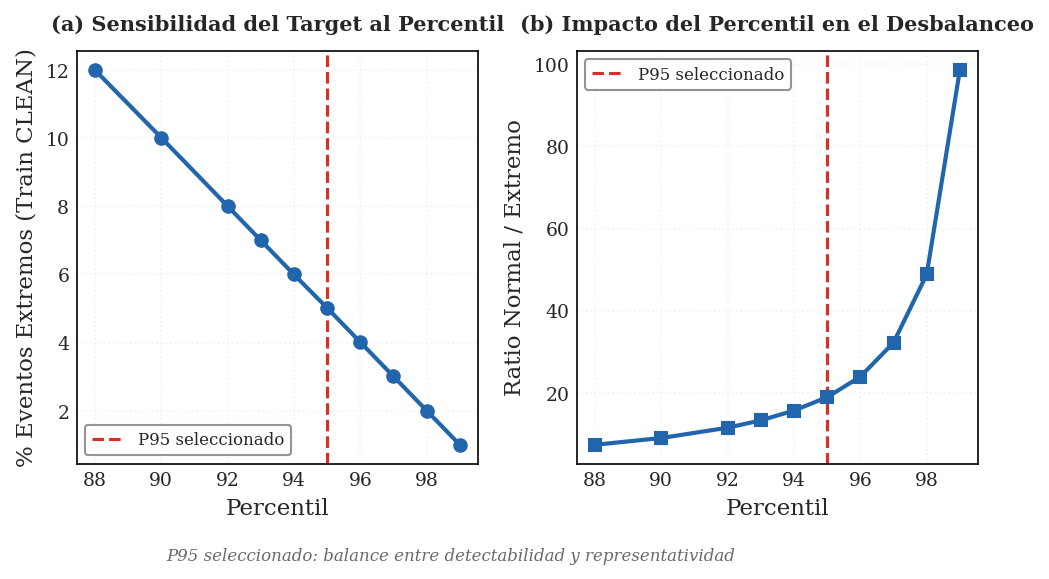


Figura guardada: fig_04_sensibilidad_percentil.png


In [21]:
fig, axes = plt.subplots(1, 2, figsize=fig_size("2x1"))
ax1 = axes[0]
ax2 = axes[1]

for ax in [ax1, ax2]:
    ax.axvline(PERCENTILE_PRIMARY, color=COLORS_P[PERCENTILE_PRIMARY], ls='--', lw=1.5,
               label=f'P{PERCENTILE_PRIMARY} seleccionado')
    ax.legend(fontsize=8)

ax1.plot(sensitivity_df['Percentil'], sensitivity_df['% Extremos (Train)'],
         marker='o', color=COLOR_NORMAL, linewidth=2, markersize=6)
ax1.set_xlabel('Percentil')
ax1.set_ylabel('% Eventos Extremos (Train CLEAN)')
ax1.set_title('(a) Sensibilidad del Target al Percentil', fontweight='bold', fontsize=10, pad=10)

ax2.plot(sensitivity_df['Percentil'],
         sensitivity_df['Ratio Normal/Extremo'],
         marker='s', color=COLOR_NORMAL, linewidth=2, markersize=6)
ax2.set_xlabel('Percentil')
ax2.set_ylabel('Ratio Normal / Extremo')
ax2.set_title('(b) Impacto del Percentil en el Desbalanceo', fontweight='bold', fontsize=10, pad=10)

fig.text(0.5, -0.04,
         f'P{PERCENTILE_PRIMARY} seleccionado: balance entre detectabilidad '
         f'y representatividad',
         ha='center', fontsize=8, style='italic', color='dimgray')

#plt.tight_layout(w_pad=2.0)
plt.tight_layout(rect=[0, 0, 1.1, 1.2],w_pad=1.2)
save_fig(fig, 'fig_04_sensibilidad_percentil', output_path=FIG_PATH)
plt.show()
plt.close()
print(f"\nFigura guardada: fig_04_sensibilidad_percentil.png")


## 1.4.1 Distribución de Volatilidad por Clase — Normal vs Extremo

Verificar que el umbral P95 separa las distribuciones de
`vol21_clean` entre días normales (`is_extreme_clean = 0`) y extremos
(`is_extreme_clean = 1`).

Métricas calculadas sobre **train exclusivamente** (sin data leakage):

- **Mann-Whitney U:** diferencia entre distribuciones sin asumir normalidad
- **Cohen's d:** tamaño del efecto (separación entre medias)

> Si las distribuciones se solapan en exceso, el problema de clasificación
> es inherentemente difícil — documentarlo antes de modelar es metodológicamente correcto.

In [22]:
# Filtrar train limpio con etiqueta válida
train_df = df[
    (df["split"] == "train") &
    (~df["bad_vol21"]) &
    (df["is_extreme_clean"].notna())
].copy()

vol_normal  = train_df[train_df["is_extreme_clean"] == 0]["vol21_clean"].dropna() * 100
vol_extremo = train_df[train_df["is_extreme_clean"] == 1]["vol21_clean"].dropna() * 100
umbral_p95  = thresholds_clean[PERCENTILE_PRIMARY] * 100

print("DISTRIBUCIÓN DE VOLATILIDAD POR CLASE — TRAIN (CLEAN)")
print("=" * 60)
print(f"  Umbral P{PERCENTILE_PRIMARY}: {umbral_p95:.4f}%")
print()
print(f"  Clase 0 (normal):  n={len(vol_normal):,}  "
      f"media={vol_normal.mean():.4f}%  "
      f"mediana={vol_normal.median():.4f}%  "
      f"max={vol_normal.max():.4f}%")
print(f"  Clase 1 (extremo): n={len(vol_extremo):,}  "
      f"media={vol_extremo.mean():.4f}%  "
      f"mediana={vol_extremo.median():.4f}%  "
      f"min={vol_extremo.min():.4f}%")
print()

# Mann-Whitney U — sin asumir normalidad, adecuado para series sesgadas
mw_stat, mw_pval = stats.mannwhitneyu(
    vol_normal, vol_extremo, alternative="less"
)
print(f"  Mann-Whitney U test:")
print(f"    U={mw_stat:.0f}  p-value={mw_pval:.2e}")
if mw_pval < 0.001:
    print("    -> Rechazo H0: distribuciones significativamente distintas (p<0.001)")

# Cohen's d — tamaño del efecto
n0, n1   = len(vol_normal), len(vol_extremo)
s_pool   = np.sqrt(
    ((n0 - 1) * vol_normal.std()**2 + (n1 - 1) * vol_extremo.std()**2)
    / (n0 + n1 - 2)
)
cohens_d = (vol_extremo.mean() - vol_normal.mean()) / s_pool
print(f"\n  Effect size (Cohen's d): {cohens_d:.3f}")
if cohens_d > 2.0:
    print("    -> Separación MUY GRANDE (d>2.0): el umbral P95 discrimina bien")
elif cohens_d > 0.8:
    print("    -> Separación GRANDE (d>0.8): buena discriminabilidad")
else:
    print("    -> Separación MODERADA: las clases se solapan parcialmente")

DISTRIBUCIÓN DE VOLATILIDAD POR CLASE — TRAIN (CLEAN)
  Umbral P95: 4.2996%

  Clase 0 (normal):  n=4,354  media=1.9847%  mediana=1.8908%  max=4.2895%
  Clase 1 (extremo): n=230  media=5.3443%  mediana=5.1257%  min=4.3014%

  Mann-Whitney U test:
    U=0  p-value=8.12e-145
    -> Rechazo H0: distribuciones significativamente distintas (p<0.001)

  Effect size (Cohen's d): 4.887
    -> Separación MUY GRANDE (d>2.0): el umbral P95 discrimina bien


  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB01_EDA/Figuras Notebook EDA/fig_05_separacion_clases_train.png  [6.1"×3.1" @ 300dpi]


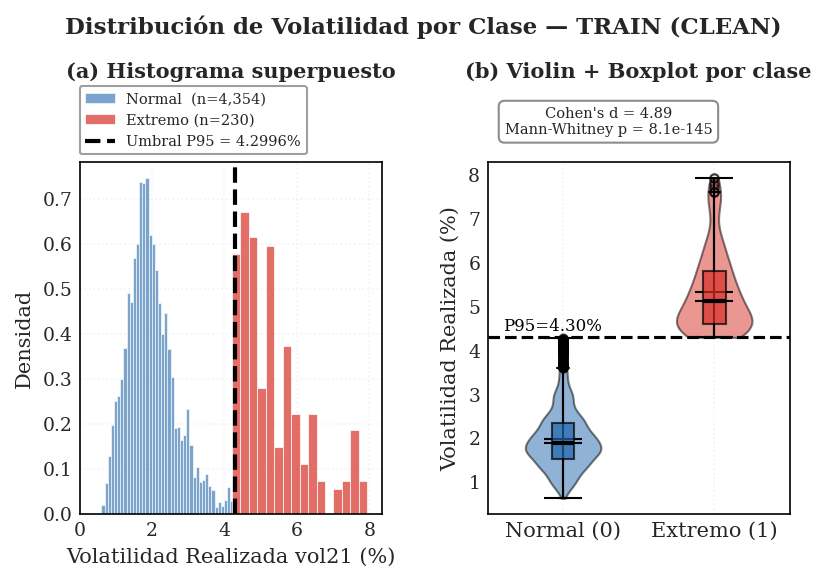

In [23]:
fig, axes = plt.subplots(1, 2, figsize=fig_size("2x1"),
                         gridspec_kw={'wspace': 0.35})

titulo = "Distribución de Volatilidad por Clase — TRAIN (CLEAN)"
fig.suptitle(titulo, fontsize=11, fontweight="bold",y=1.2)

ax = axes[0]
bins_n = np.linspace(0, vol_normal.quantile(0.999), 50)
bins_e = np.linspace(0, vol_extremo.max(), 35)

ax.hist(vol_normal,  bins=bins_n, density=True, alpha=0.6,
        color=COLOR_NORMAL,  edgecolor="white", linewidth=0.5,
        label=f"Normal  (n={len(vol_normal):,})")
ax.hist(vol_extremo, bins=bins_e, density=True, alpha=0.7,
        color=COLOR_EXTREMO, edgecolor="white", linewidth=0.5,
        label=f"Extremo (n={len(vol_extremo):,})")
ax.axvline(umbral_p95, color="black", linestyle="--", linewidth=2,
           label=f"Umbral P{PERCENTILE_PRIMARY} = {umbral_p95:.4f}%")

ax.set_xlabel("Volatilidad Realizada vol21 (%)", fontsize=10)
ax.set_ylabel("Densidad", fontsize=10)
ax.set_title("(a) Histograma superpuesto", fontweight="bold", fontsize=10, pad=40)

ax.legend(
    loc='lower left', bbox_to_anchor=(0.0, 1.02),
    fontsize=7, frameon=True, facecolor='white',
    edgecolor='0.6', framealpha=0.95, borderaxespad=0.0
)
ax.set_xlim(left=0)

ax2 = axes[1]
colors = [COLOR_NORMAL, COLOR_EXTREMO]
parts = ax2.violinplot([vol_normal.values, vol_extremo.values],
                       positions=[1, 2], showmeans=True, showmedians=True)
for i, pc in enumerate(parts['bodies']):
    pc.set_facecolor(colors[i]); pc.set_alpha(0.5); pc.set_edgecolor("black")
for elem in ['cbars', 'cmins', 'cmaxes', 'cmeans', 'cmedians']:
    parts[elem].set_edgecolor("black"); parts[elem].set_linewidth(1)

bp = ax2.boxplot(
    [vol_normal.values, vol_extremo.values],
    positions=[1, 2], widths=0.15, patch_artist=True,
    medianprops=dict(color="black", linewidth=2),
    flierprops=dict(marker="o", markersize=4, alpha=0.5),
)
bp["boxes"][0].set_facecolor(COLOR_NORMAL);  bp["boxes"][0].set_alpha(0.7)
bp["boxes"][1].set_facecolor(COLOR_EXTREMO); bp["boxes"][1].set_alpha(0.7)

ax2.axhline(umbral_p95, color="black", linestyle="--", linewidth=1.5)
# Label del umbral como texto en el eje, no como leyenda
ax2.text(0.6, umbral_p95 + 0.05,
         f"P{PERCENTILE_PRIMARY}={umbral_p95:.2f}%",
         fontsize=8, va='bottom', ha='left', color='black')

ax2.set_xticks([1, 2])
ax2.set_xticklabels(["Normal (0)", "Extremo (1)"], fontsize=10)
ax2.set_title("(b) Violin + Boxplot por clase", fontweight="bold", fontsize=10, pad=40)
ax2.set_ylabel("Volatilidad Realizada (%)", fontsize=10)
ax2.grid(axis="y")

# Anotación Cohen's d — esquina INFERIOR derecha, lejos del umbral
anotacion = f"Cohen's d = {cohens_d:.2f}\nMann-Whitney p = {mw_pval:.1e}"
ax2.text(0.4, 1.07, anotacion,
         transform=ax2.transAxes,
         ha='center', va='bottom', fontsize=7,
         bbox=dict(boxstyle="round,pad=0.4", facecolor="white",
                   edgecolor="gray", alpha=0.9))

plt.tight_layout(rect=[0, 0, 1, 1.1])
save_fig(fig, 'fig_05_separacion_clases_train', output_path=FIG_PATH)
plt.show()
plt.close()

### Distribución de vol21_clean por Clase: Normal vs Extremo (Train CLEAN)

**Qué muestra**
Panel (a): histogramas superpuestos de vol21_clean para Normal (n ≈
4,354) y Extremo (n=230). Panel (b): violin + boxplot por clase con
estadísticos Mann-Whitney y Cohen's d anotados.

**Cómo se construye**
vol21_clean filtrado a bad_vol21=False en train únicamente. P95=4.2996%
calibrado en el mismo conjunto. Mann-Whitney p≈0 y Cohen's d=4.89 —
efecto muy grande por construcción del target.

**Por qué tiene esta forma**
La clase Normal se concentra entre 1–3% (régimen tranquilo), la clase
Extremo entre 4.3% y 8%+. La separación es perfecta por construcción —
es una verificación del diseño del target, no un hallazgo empírico.

**Por qué es importante para la tesis**
Confirma que P95 captura un fenómeno económicamente significativo. La
separación estadística perfecta es consecuencia del diseño del target
(is_extreme_clean fue definido como vol21_clean > P95_train): esto
debe documentarse explícitamente para que el comité no lo interprete
como resultado independiente.

## 1.5 Rolling P95 Dinámico (Benchmark Adaptativo)

**PROPÓSITO:** Comparar umbral estático vs dinámico (robustez ante drift).

In [24]:
# ROLLING P95 DINÁMICO (BENCHMARK ADAPTATIVO)
print("ROLLING P95 DINÁMICO (Benchmark Adaptativo)")

# P95 rolling (252 días)
df['p95_vol21_rolling_252'] = (
    df['vol21_clean']
    .rolling(window=ROLLING_VAR_WINDOW, min_periods=126)
    .quantile(0.95)
)

# is_extreme_dynamic = 1 si vol21_clean(t) SUPERA el P95 de la ventana
# rolling de 252 días centrada en t. Detecta anomalías relativas al
# régimen local — se adapta a cambios estructurales de volatilidad.
# Diferencia con is_extreme_clean: ese usa un umbral fijo calibrado en
# train; este usa un umbral que evoluciona con el mercado.
df['is_extreme_dynamic'] = (df['vol21_clean'] > df['p95_vol21_rolling_252']).astype(int)
df.loc[df['bad_vol21'], 'is_extreme_dynamic'] = np.nan


print(f"Observaciones válidas: {df['p95_vol21_rolling_252'].notna().sum():,}")
print(f"P95 rolling promedio: {df['p95_vol21_rolling_252'].mean():.6f}")
print(f"P95 estático (CLEAN): {thresholds_clean[PERCENTILE_PRIMARY]:.6f}")
print(f"Ratio rolling/estático: {df['p95_vol21_rolling_252'].mean()/thresholds_clean[PERCENTILE_PRIMARY]:.2f}x")

# Análisis de desviación
dev = thresholds_clean[PERCENTILE_PRIMARY] - df['p95_vol21_rolling_252']
pct_below = (dev > 0).mean() * 100
print(f"\nDesviación media: {dev.mean():.6f}")
print(f"P95 dinámico < estático: {pct_below:.1f}% del tiempo")
print(f"Rango: [{dev.min():.6f}, {dev.max():.6f}]")

ROLLING P95 DINÁMICO (Benchmark Adaptativo)
Observaciones válidas: 6,260
P95 rolling promedio: 0.037745
P95 estático (CLEAN): 0.042996
Ratio rolling/estático: 0.88x

Desviación media: 0.005251
P95 dinámico < estático: 74.0% del tiempo
Rango: [-0.067477, 0.030190]


## 1.6 Detección de Outliers

In [25]:
# Z-score — estandarizado con parámetros de TRAIN CLEAN (sin leakage)
# Identificar outliers en toda la serie usando el régimen "normal" del activo

train_returns_clean = df[
    (df['split'] == 'train') & (~df['bad_return'])
]['returns']

mean_train = train_returns_clean.mean()
std_train  = train_returns_clean.std()

# Aplicar a toda la serie (incluye val/test) para detectar desviaciones
# respecto al régimen de entrenamiento
df['returns_zscore_clean'] = (df['returns'] - mean_train) / std_train
df['outlier_zscore_clean'] = (np.abs(df['returns_zscore_clean']) > 3).astype(int)

n_outliers  = df['outlier_zscore_clean'].sum()
pct_outliers = n_outliers / len(df) * 100

print(f"Parámetros de estandarización (TRAIN CLEAN):")
print(f"  Media:  {mean_train*100:.4f}%")
print(f"  Std:    {std_train*100:.4f}%")
print(f"  Fuente: {len(train_returns_clean):,} obs (train sin bad_return)")
print(f"\nOutliers detectados (|z| > 3): {n_outliers:,} ({pct_outliers:.2f}%)")

outliers_and_extreme = (
    (df['outlier_zscore_clean'] == 1) &
    (df['is_extreme_clean'] == 1)
)
coincidencia = outliers_and_extreme.sum()
pct_coincidencia = coincidencia / n_outliers * 100 if n_outliers > 0 else 0
print(f"Coincidencia con eventos P95: {coincidencia} ({pct_coincidencia:.1f}%)")

Parámetros de estandarización (TRAIN CLEAN):
  Media:  0.0063%
  Std:    2.3702%
  Fuente: 4,584 obs (train sin bad_return)

Outliers detectados (|z| > 3): 106 (1.66%)
Coincidencia con eventos P95: 55 (51.9%)


El Z-score se estandariza usando la media y desviación estándar del conjunto de **entrenamiento limpio** (Train, excluyendo `bad_return`), de modo que:

1. Los parámetros de referencia no ven datos futuros (sin leakage temporal).
2. Los retornos contaminados (precio negativo, Abr 2020) son evaluados contra una distribución que no los incluyó en su calibración — por construcción, serán detectados como outliers extremos.
3. Los días de validación y test se miden contra el régimen "normal" del activo aprendido en entrenamiento, lo que permite cuantificar cuánto se desvía cada período respecto a la línea base histórica.

Esta columna (`returns_zscore_clean`) se exporta al CSV como variable de diagnóstico. Si se usa como feature en NB02, aplicar `.shift(1)` para
evitar uso contemporáneo

---
# PARTE II: ANÁLISIS EXPLORATORIO AVANZADO (CLEAN)
---

## 2.0 Análisis Estacional de Volatilidad

  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB01_EDA/Figuras Notebook EDA/fig_06_volatilidad_estacional.png  [6.1"×4.6" @ 300dpi]


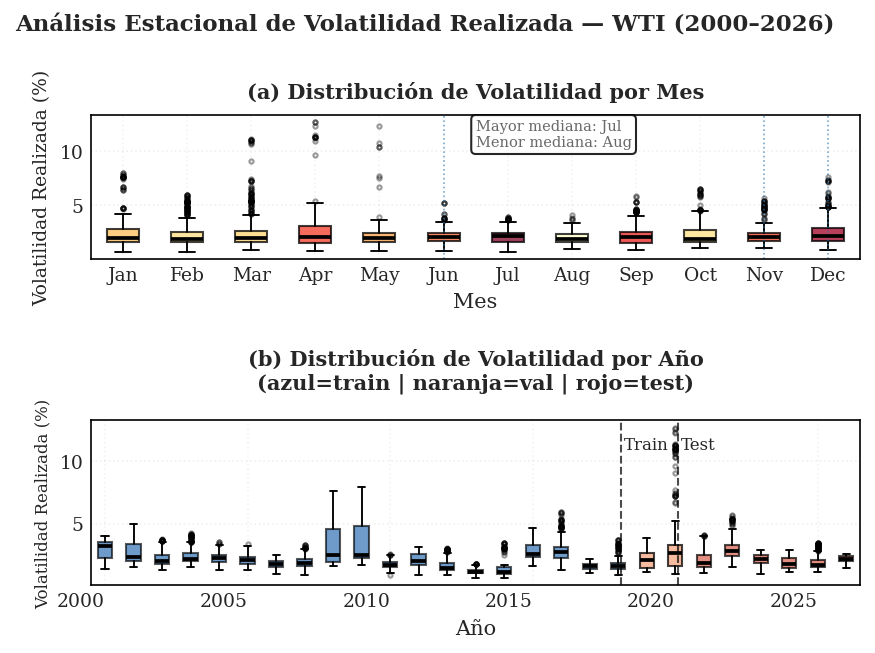

Figura guardada: fig_06_volatilidad_estacional.png


In [35]:
MESES_ORDEN = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

df_eda         = df[df["vol21_clean"].notna()].copy()
df_eda["mes"]  = df_eda.index.month_name().str[:3]
df_eda["anio"] = df_eda.index.year

fig, axes = plt.subplots(2, 1,figsize=fig_size("2x2", aspect=0.92),
    gridspec_kw={"height_ratios": [1, 1.15]})

fig.suptitle(
    "Análisis Estacional de Volatilidad Realizada — WTI (2000–2026)",
    fontsize=11, fontweight="bold", y=0.97
)

vol_por_mes = [
    df_eda[df_eda["mes"] == m]["vol21_clean"].values * 100
    for m in MESES_ORDEN
]
bp = axes[0].boxplot(
    vol_por_mes, labels=MESES_ORDEN, patch_artist=True,
    medianprops=dict(color="black", linewidth=1.8),
    flierprops=dict(marker="o", markersize=2, alpha=0.4),
    whiskerprops=dict(linewidth=0.9), capprops=dict(linewidth=0.9),
)
medianas = [np.median(v) for v in vol_por_mes]
norm_med = plt.Normalize(min(medianas), max(medianas))
cmap_mes = plt.cm.YlOrRd
for patch, med in zip(bp["boxes"], medianas):
    patch.set_facecolor(cmap_mes(norm_med(med)))
    patch.set_alpha(0.75)

# Líneas punteadas en meses con reuniones OPEP+ históricas
for mes_opep in ["Nov", "Dec", "Jun"]:
    axes[0].axvline(
        MESES_ORDEN.index(mes_opep) + 1,
        color=COLOR_VOL, linestyle=":", linewidth=0.8, alpha=0.6
    )

mes_max = MESES_ORDEN[int(np.argmax(medianas))]
mes_min = MESES_ORDEN[int(np.argmin(medianas))]
nota_mes = f"Mayor mediana: {mes_max}\nMenor mediana: {mes_min}"
axes[0].annotate(
    nota_mes,
    xy=(0.5, 0.78), xycoords="axes fraction",
    fontsize=7, color="dimgray",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.85)
)

axes[0].set_title(
    "(a) Distribución de Volatilidad por Mes",
    fontsize=10, pad=8)

axes[0].set_ylabel("Volatilidad Realizada (%)",fontsize=9)
axes[0].set_xlabel("Mes",fontsize=10)
axes[0].grid(axis="y", alpha=0.3)


anios        = sorted(df_eda["anio"].unique())
vol_por_anio = [
    df_eda[df_eda["anio"] == a]["vol21_clean"].values * 100
    for a in anios
]
bp2 = axes[1].boxplot(
    vol_por_anio, labels=[str(a) for a in anios], patch_artist=True,
    medianprops=dict(color="black", linewidth=1.8),
    flierprops=dict(marker="o", markersize=2, alpha=0.4),
    whiskerprops=dict(linewidth=0.9), capprops=dict(linewidth=0.9),
)
for patch, a in zip(bp2["boxes"], anios):
    if   a <= 2018: patch.set_facecolor(SPLIT_COLORS['train']); patch.set_alpha(0.65)
    elif a <= 2020: patch.set_facecolor(SPLIT_COLORS['validation']); patch.set_alpha(0.75)
    else:           patch.set_facecolor(SPLIT_COLORS['test']); patch.set_alpha(0.70)

# Líneas de separación de splits
anio_list = list(anios)
for anio_sep, etq in [(2018, "Train"), (2020, "Test")]:
    if anio_sep in anio_list:
        x_sep = anio_list.index(anio_sep) + 1.1
        axes[1].axvline(
            x_sep, color="black", linestyle="--", linewidth=1.0, alpha=0.7
        )
        ymax = axes[1].get_ylim()[1]
        axes[1].text(
            x_sep + 0.1, ymax * 0.90 if ymax > 0 else 5,
            etq, ha="left", va="top", fontsize=8
        )

titulo_b = "(b) Distribución de Volatilidad por Año\n(azul=train | naranja=val | rojo=test)"
axes[1].set_title(titulo_b, fontsize=10,pad=15)
axes[1].set_ylabel("Volatilidad Realizada (%)", fontsize=8)
axes[1].set_xlabel("Año",fontsize=10)
tick_positions = []
tick_labels = []
for i, year in enumerate(anios):
    if i == 0 or (year - anios[0]) % 5 == 0:
        tick_positions.append(i + 1)
        tick_labels.append(str(year))

axes[1].set_xticks(tick_positions)
axes[1].set_xticklabels(tick_labels, ha='right') # Apply rotation and ha here

axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout(rect=[0.03, 0.03, 1, 0.97], h_pad=1.8)
save_fig(fig, 'fig_06_volatilidad_estacional', output_path=FIG_PATH)
plt.show()
plt.close()
print("Figura guardada: fig_06_volatilidad_estacional.png")

In [ ]:
print()
print("MEDIANA DE VOLATILIDAD POR MES (%, serie completa):\n")
for mes, med in sorted(zip(MESES_ORDEN, medianas), key=lambda x: -x[1]):
    print(f"  {mes:>3}: {med:.4f}%")

print()
print("TOP 5 AÑOS MÁS VOLÁTILES:")
medianas_anio = [
    (a, float(np.median(v))) for a, v in zip(anios, vol_por_anio)
]
for a, m in sorted(medianas_anio, key=lambda x: -x[1])[:5]:
    tag = "train" if a <= 2018 else ("val" if a <= 2020 else "test")
    print(f"  {a}: {m:.4f}%  [{tag}]")



MEDIANA DE VOLATILIDAD POR MES (%, serie completa):

  Jul: 2.1141%
  Dec: 2.0938%
  Sep: 2.0323%
  Apr: 2.0135%
  Nov: 2.0106%
  Jun: 1.9859%
  May: 1.9435%
  Jan: 1.9127%
  Mar: 1.8929%
  Feb: 1.8778%
  Oct: 1.8721%
  Aug: 1.8103%

TOP 5 AÑOS MÁS VOLÁTILES:
  2000: 3.1958%  [train]
  2022: 2.7603%  [test]
  2016: 2.7384%  [train]
  2020: 2.6580%  [val]
  2015: 2.5846%  [train]


- La estacionalidad mensual es mínima (rango medianas: 0.30%) — los shocks son
  aperiódicos y *event-driven*, no estacionales.
- El año más volátil en mediana es 2000 [train], no 2020.
- 2020 [val]: shock puntual extremo (precio negativo). 2022 [test]: shock persistente (invasión Ucrania).
- Los tres splits contienen regímenes de alta volatilidad — el modelo no puede
  asumir que val/test serán más tranquilos que train.

## 2.1 Tests de Estacionariedad

In [ ]:
# ADF (H0: raíz unitaria)
adf_result_clean = adfuller(returns_clean.dropna(), autolag='AIC')
adf_pvalue = adf_result_clean[1]
kpss_result_clean = kpss(returns_clean.dropna(), regression='c', nlags='auto')
kpss_pvalue = kpss_result_clean[1]

# ARCH LM — Engle (H0: sin heterocedasticidad condicional)
lm_stat, lm_pval, f_stat, f_pval = het_arch(
    returns_clean.dropna(), nlags=10)

print("TESTS DE ESTACIONARIEDAD Y HETEROCEDASTICIDAD")

print(f'\nADF Test — Estadístico: {adf_result_clean[0]:.4f} | p-valor: {adf_pvalue:.4e}')
print(f'  -> {"Estacionaria" if adf_pvalue < 0.05 else "No estacionaria"} (rechaza H0 raiz unitaria)')

kpss_str = '>=0.10' if kpss_pvalue >= 0.1 else f'{kpss_pvalue:.4f}'
print(f'\nKPSS Test — Estadístico: {kpss_result_clean[0]:.4f} | p-valor: {kpss_str}')
print(f'  -> {"Estacionaria" if kpss_pvalue > 0.05 else "No estacionaria"} (no rechaza H0 estacionariedad)')

print(f'\nEngle ARCH LM (nlags=10) — LM: {lm_stat:.4f} | p-valor: {lm_pval:.4e}')
print(f'  -> {"Efectos ARCH presentes — justifica GARCH" if lm_pval < 0.05 else "Sin efectos ARCH"}')

print(f"""
INTERPRETACIÓN CONJUNTA
  ADF  p={adf_pvalue:.4e}  -> retornos estacionarios en media
  KPSS p={kpss_str}        -> confirma estacionariedad
  ARCH LM={lm_stat:.1f} p={lm_pval:.4e} -> varianza condicional no constante

 Clásico de retornos financieros: estacionarios en media pero
  con volatility clustering — condición necesaria para GARCH.
""")

print(f"\n→ PARA MARKDOWN: LM stat = {lm_stat:.2f}, p = {lm_pval:.2e}")

if adf_pvalue < 0.05 and kpss_pvalue >= 0.05:
    print('\n CONCLUSION: Serie ESTACIONARIA -> adecuada para GARCH y LSTM')

vol_ratio_train = df[(df['split']=='train') & (~df['bad_vol21'])]['volatilidad_ratio21'].dropna()
adf_vr = adfuller(vol_ratio_train)
print(f"\nADF volatilidad_ratio21: stat={adf_vr[0]:.3f}, p={adf_vr[1]:.4f}")

TESTS DE ESTACIONARIEDAD Y HETEROCEDASTICIDAD

ADF Test — Estadístico: -14.4807 | p-valor: 6.3795e-27
  -> Estacionaria (rechaza H0 raiz unitaria)

KPSS Test — Estadístico: 0.0411 | p-valor: >=0.10
  -> Estacionaria (no rechaza H0 estacionariedad)

Engle ARCH LM (nlags=10) — LM: 1254.7016 | p-valor: 2.2784e-263
  -> Efectos ARCH presentes — justifica GARCH

INTERPRETACIÓN CONJUNTA
  ADF  p=6.3795e-27  -> retornos estacionarios en media
  KPSS p=>=0.10        -> confirma estacionariedad
  ARCH LM=1254.7 p=2.2784e-263 -> varianza condicional no constante

 Clásico de retornos financieros: estacionarios en media pero
  con volatility clustering — condición necesaria para GARCH.


→ PARA MARKDOWN: LM stat = 1254.70, p = 2.28e-263

 CONCLUSION: Serie ESTACIONARIA -> adecuada para GARCH y LSTM

ADF volatilidad_ratio21: stat=-12.159, p=0.0000


ADF y KPSS confirman estacionariedad en media (p<0.05 y p>0.05 respectivamente).
El test de Engle (LM, 10 lags) confirma efectos ARCH significativos (p<0.001), evidenciando heterocedasticidad condicional — condición necesaria y suficiente
para justificar la especificación GARCH.

## 2.2 Autocorrelación

  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB01_EDA/Figuras Notebook EDA/fig_07_acf_retornos.png  [6.1"×4.2" @ 300dpi]


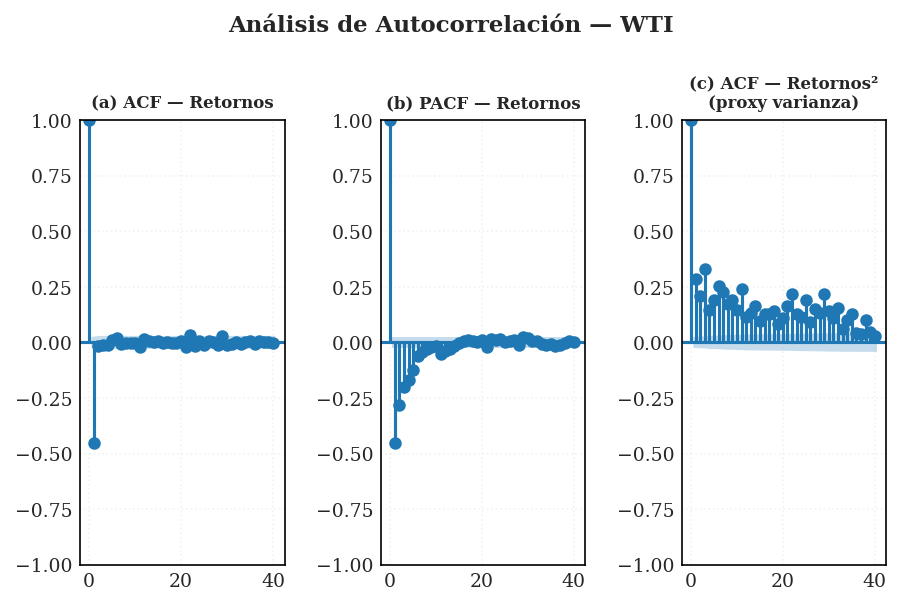

 Figura guardada: fig_07_acf_retornos.png


In [ ]:
# ANÁLISIS DE AUTOCORRELACIÓN -- 3 diagnósticos clave

returns_sq  = returns_clean ** 2       # proxy varianza diaria
returns_abs = returns_clean.abs()      # robusto a outliers extremos

fig, axes = plt.subplots(1, 3, figsize=fig_size('full', aspect=0.68))
fig.suptitle('Análisis de Autocorrelación — WTI',
             fontsize=11, fontweight='bold', y=0.96)

plot_acf(df['returns'].dropna(), lags=40, ax=axes[0], alpha=0.05)
axes[0].set_title('(a) ACF — Retornos', fontweight='bold', fontsize=8, pad=6)

plot_pacf(df['returns'].dropna(), lags=40, ax=axes[1], alpha=0.05, method='ywm')
axes[1].set_title('(b) PACF — Retornos', fontweight='bold', fontsize=8, pad=6)

plot_acf(returns_sq.dropna(), lags=40, ax=axes[2], alpha=0.05)
axes[2].set_title('(c) ACF — Retornos²\n(proxy varianza)', fontweight='bold', fontsize=8, pad=6)
# Nota: los 3 paneles capturan el efecto ARCH relevante: correlacion serial en retornos y en su cuadrado.

plt.tight_layout(rect=[0.0, 0.0, 1, 0.97],w_pad=1.5)
save_fig(fig, 'fig_07_acf_retornos', output_path=FIG_PATH)
plt.show()
plt.close()
print(' Figura guardada: fig_07_acf_retornos.png')

### Autocorrelación de Retornos WTI — Evidencia de Clustering de Volatilidad

**Qué muestra**
Tres paneles: (a) ACF de retornos, (b) PACF de retornos, (c) ACF de
retornos² (proxy de varianza). Los retornos en nivel muestran poca
autocorrelación; los retornos² muestran autocorrelación persistente.

**Cómo se construye**
ACF/PACF con statsmodels sobre el dataset CLEAN, lags=40. Se usan
retornos² en lugar de vol21 para evitar autocorrelación mecánica
generada por la ventana rolling en los lags 1–20.

**Por qué tiene esta forma**
Los retornos en nivel son casi no autocorrelacionados (consistente con
EMH débil), pero los retornos² mantienen autocorrelación significativa
hasta el lag 40 — la firma del clustering de volatilidad
(ARCH-LM=1253.8, p≈0).

**Por qué es importante para la tesis**
Justifica formalmente la familia GARCH (diseñada para varianza condicional
persistente) y explica por qué LSTM con LOOKBACK=21 puede aprender
patrones de volatilidad: la memoria de la serie es real y estadísticamente
significativa, no un artefacto.

## 2.3 Tests de Concept Drift

In [ ]:
# TESTS DE CONCEPT DRIFT (KS TEST)

train_vol = df[df['split'] == 'train']['vol21_clean'].dropna()
val_vol   = df[df['split'] == 'validation']['vol21_clean'].dropna()
test_vol  = df[df['split'] == 'test']['vol21_clean'].dropna()

print(f"train_vol: {len(train_vol):,}")
print(f"val_vol:   {len(val_vol):,}")
print(f"test_vol:  {len(test_vol):,}")

ks_train_val  = ks_2samp(train_vol, val_vol)
ks_train_test = ks_2samp(train_vol, test_vol)
ks_val_test   = ks_2samp(val_vol, test_vol)

print("\nTESTS DE CONCEPT DRIFT (KOLMOGOROV-SMIRNOV)")
print(f"{'Comparación':<20} {'KS stat':>8} {'p-value':>10} {'Δ Media':>10} {'Resultado':>20}")

comparisons = [
    ('Train vs Val',  train_vol, val_vol,  ks_train_val),
    ('Train vs Test', train_vol, test_vol, ks_train_test),
    ('Val vs Test',   val_vol,   test_vol, ks_val_test)
]

for label, base, other, ks in comparisons:
    delta = (other.mean() / base.mean() - 1) * 100
    resultado = 'DRIFT' if ks.pvalue < 0.05 else 'Sin drift'
    print(f"{label:<20} {ks.statistic:>8.4f} {ks.pvalue:>10.4f} {delta:>9.1f}% {resultado:>20}")

print("\nEstadísticas de volatilidad por split:")
stats_vol = pd.DataFrame({
    'Split': ['Train', 'Validation', 'Test'],
    'Media': [train_vol.mean(), val_vol.mean(), test_vol.mean()],
    'P95':   [train_vol.quantile(0.95), val_vol.quantile(0.95), test_vol.quantile(0.95)],
    'Max':   [train_vol.max(), val_vol.max(), test_vol.max()]
})
print(stats_vol.round(4).to_string(index=False))

print(f"\n   • Train vs Val:  {'DRIFT' if ks_train_val.pvalue < 0.05 else 'Sin drift'}  (p={ks_train_val.pvalue:.4g})")
print(f"  • Train vs Test: {'DRIFT' if ks_train_test.pvalue < 0.05 else 'Sin drift'} (p={ks_train_test.pvalue:.4g})")
print(f"  • Val vs Test:   {'DRIFT' if ks_val_test.pvalue < 0.05 else 'Sin drift'}   (p={ks_val_test.pvalue:.4g})")
print(f"  • Δ media Val vs Train: {((val_vol.mean()/train_vol.mean()-1)*100):.1f}%  en media (pico COVID)")
print(f"  • Δ media Test vs Train: {((test_vol.mean()/train_vol.mean()-1)*100):.1f}%  (régimen similar a train)")
print(f"  • Δ media Test vs Val: {((test_vol.mean()/val_vol.mean()-1)*100):.1f}%")

print(f" \n → Benchmark P95 dinámico confirma: {pct_below:.1f}% del tiempo por debajo del estático")
print(f"Î” P95 Val vs Train: {((val_vol.quantile(0.95)/train_vol.quantile(0.95)-1)*100):.1f}%")
print(f"Î” P95 Test vs Train: {((test_vol.quantile(0.95)/train_vol.quantile(0.95)-1)*100):.1f}%")

print(f"\n→ PARA MARKDOWN Cell 65:")
print(f"   KS Train vs Val:  stat={ks_train_val.statistic:.4f},  p={ks_train_val.pvalue:.4e}")
print(f"   KS Train vs Test: stat={ks_train_test.statistic:.4f}, p={ks_train_test.pvalue:.4e}")

train_vol: 4,584
val_vol:   483
test_vol:  1,296

TESTS DE CONCEPT DRIFT (KOLMOGOROV-SMIRNOV)
Comparación           KS stat    p-value    Δ Media            Resultado
Train vs Val           0.1810     0.0000      30.6%                DRIFT
Train vs Test          0.0764     0.0000       0.4%                DRIFT
Val vs Test            0.1818     0.0000     -23.1%                DRIFT

Estadísticas de volatilidad por split:
     Split  Media    P95    Max
     Train 0.0215 0.0430 0.0795
Validation 0.0281 0.0958 0.1271
      Test 0.0216 0.0367 0.0566

   • Train vs Val:  DRIFT  (p=5.36e-13)
  • Train vs Test: DRIFT (p=1.428e-05)
  • Val vs Test:   DRIFT   (p=1.195e-10)
  • Δ media Val vs Train: 30.6%  en media (pico COVID)
  • Δ media Test vs Train: 0.4%  (régimen similar a train)
  • Δ media Test vs Val: -23.1%
 
 → Benchmark P95 dinámico confirma: 74.0% del tiempo por debajo del estático
Î” P95 Val vs Train: 122.9%
Î” P95 Test vs Train: -14.7%

→ PARA MARKDOWN Cell 65:
   KS Train vs Va

El modelo se entrena en régimen normal, valida en crisis, y se prueba en un entorno posterior con distribución distinta.

- **Train vs Val — Drift fuerte** (KS=0.181, p=5.4e-13): distribuciones claramente
  distintas. Δ media = +30.6% de volatilidad en validación respecto a train, con
  un P95 un 122.9% superior — el umbral estático captura solo una fracción de los
  eventos extremos reales durante COVID-19.

- **Train vs Test — Drift leve** (KS=0.076, p=1.4e-05): distribuciones similares,
  retorno al régimen histórico post-pandemia. Δ media = +0.4%, P95 un 14.7% inferior
  al de train — el mercado post-2021 es estructuralmente menos volátil que el período
  de entrenamiento.

- **Val vs Test — Drift fuerte** (KS=0.182, p=1.2e-10): Δ media = −23.1%, confirma
  que validación y test representan regímenes opuestos: crisis vs normalización.

El P95 dinámico se mantiene por debajo del estático el 74.0% del tiempo, confirmando
que el umbral fijo sobreestima el riesgo en condiciones normales y lo subestima
durante crisis.

 Test de Chow — Quiebre Estructural por Split 
Serie          Corte                F-stat    p-value     α=0.05  Conclusión
------------------------------------------------------------------------------
  vol21_clean  train → val           0.304   0.738158             Sin quiebre estructural
  vol21_clean  val → test            0.147   0.863311             Sin quiebre estructural
  vol21_clean  train → test          0.994   0.370344             Sin quiebre estructural
  returns      train → val          13.193   0.000002        ***  Quiebre estructural detectado
  returns      val → test            1.642   0.193842             Sin quiebre estructural
  returns      train → test          1.638   0.194528             Sin quiebre estructural
  |returns|    train → val           8.470   0.000213        ***  Quiebre estructural detectado
  |returns|    val → test            1.857   0.156513             Sin quiebre estructural
  |returns|    train → test          6.113   0.002228         ** 

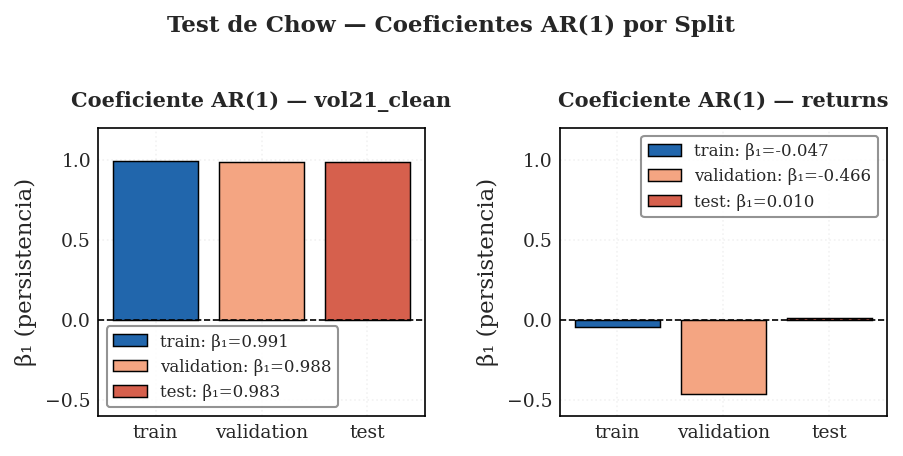

 Figura guardada: fig_07_acf_retornos.png


In [ ]:
# Test de Chow : Quiebre estructural entre splits
# Chow (1960): H0 = los coeficientes de regresión son iguales en ambos períodos

def chow_test(y1, y2, X1=None, X2=None):
    """
    Test de Chow (1960) — quiebre estructural entre dos muestras.
    H0: coeficientes AR(1) iguales en ambas submuestras.
    Retorna: F_stat, p_value, df1, df2, RSS por submuestra, conclusión.
    """
    y1, y2 = np.asarray(y1, dtype=float), np.asarray(y2, dtype=float)

    def make_ar1(y):
        y_lag  = y[:-1]
        y_curr = y[1:]
        return np.column_stack([np.ones(len(y_lag)), y_lag]), y_curr

    if X1 is None or X2 is None:
        X1, y1 = make_ar1(y1)
        X2, y2 = make_ar1(y2)
    else:
        X1, X2 = np.asarray(X1), np.asarray(X2)

    k  = X1.shape[1]           # número de parámetros
    n1, n2 = len(y1), len(y2)
    n  = n1 + n2

    def ols_rss(X, y):
        beta, rss, _, _ = np.linalg.lstsq(X, y, rcond=None)
        rss = float(rss[0]) if len(rss) > 0 else np.sum((y - X @ beta) ** 2)
        return beta, rss

    # Regresión en cada submuestra
    beta1, rss1 = ols_rss(X1, y1)
    beta2, rss2 = ols_rss(X2, y2)
    rss_unrestricted = rss1 + rss2

    # Regresión pooled (restringida: mismos coeficientes)
    X_pool = np.vstack([X1, X2])
    y_pool = np.concatenate([y1, y2])
    _, rss_pool = ols_rss(X_pool, y_pool)

    # Estadístico F de Chow
    df1 = k                     # restricciones impuestas
    df2 = n - 2 * k             # grados de libertad del error
    F   = ((rss_pool - rss_unrestricted) / df1) / (rss_unrestricted / df2)
    p   = 1 - stats.f.cdf(F, df1, df2)

    return {
        'F_stat'    : round(F, 4),
        'p_value'   : round(p, 6),
        'df1'       : df1, 'df2': df2,
        'RSS_split1': round(rss1, 6),
        'RSS_split2': round(rss2, 6),
        'RSS_pool'  : round(rss_pool, 6),
        'beta1'     : beta1, 'beta2': beta2,
        'conclusion': 'Quiebre estructural detectado' if p < 0.05
                      else 'Sin quiebre estructural'
    }

# Aplicación a vol21_clean y returns
breakpoints = [
    ('train → val',  'train',      'validation'),
    ('val → test',   'validation', 'test'),
    ('train → test', 'train',      'test'),
]

series_to_test = {
    'vol21_clean' : df['vol21_clean'].dropna(),
    'returns'     : df['returns'].dropna(),
    '|returns|'   : df['returns'].abs().dropna(),
}

print(" Test de Chow — Quiebre Estructural por Split ")
print(f"{'Serie':<14} {'Corte':<18} {'F-stat':>8} {'p-value':>10} {'α=0.05':>10}  Conclusión")
print("-" * 78)

chow_results = []
for serie_name, serie in series_to_test.items():
    for label, s1, s2 in breakpoints:
        idx1 = df.index[df['split'] == s1]
        idx2 = df.index[df['split'] == s2]
        y1   = serie.reindex(idx1).dropna().values
        y2   = serie.reindex(idx2).dropna().values
        if len(y1) < 10 or len(y2) < 10:
            continue
        res = chow_test(y1, y2)
        sig = '***' if res['p_value'] < 0.001 else \
              ('**'  if res['p_value'] < 0.01  else \
              ('*'   if res['p_value'] < 0.05  else ''))
        print(f"  {serie_name:<12} {label:<18} {res['F_stat']:>8.3f} "
              f"{res['p_value']:>10.6f} {sig:>10}  {res['conclusion']}")
        chow_results.append({'serie': serie_name, 'corte': label, **res})

print()
print("Significancia: *** p<0.001  ** p<0.01  * p<0.05")

fig, axes = plt.subplots(1, 2, figsize=fig_size("2x1"))
fig.suptitle('Test de Chow — Coeficientes AR(1) por Split',
             fontsize=11, fontweight='bold', y=0.98)

for ax, serie_name in zip(axes, ['vol21_clean', 'returns']):
    serie = series_to_test[serie_name]
    for split_name, col in SPLIT_COLORS.items():
        idx  = df.index[df['split'] == split_name]
        y    = serie.reindex(idx).dropna().values
        if len(y) < 10:
            continue
        y_lag  = y[:-1]
        y_curr = y[1:]
        X      = np.column_stack([np.ones(len(y_lag)), y_lag])
        beta, _, _, _ = np.linalg.lstsq(X, y_curr, rcond=None)
        ax.bar(split_name, beta[1], color=col, edgecolor='black',
               linewidth=0.7, label=f"{split_name}: β₁={beta[1]:.3f}")

    ax.axhline(0, color='black', lw=0.8, ls='--')
    ax.set_title(f'Coeficiente AR(1) — {serie_name}', fontweight='bold',fontsize=10)
    ax.set_ylabel('β₁ (persistencia)')
    ax.legend(fontsize=8)
    ax.set_ylim(-0.6, 1.2)

plt.tight_layout(rect=[0, 0, 1, 0.96], w_pad=2.5)
save_fig(fig, 'fig_08_chow_kde_splits', output_path=FIG_PATH)
plt.show()
plt.close()
print(' Figura guardada: fig_07_acf_retornos.png')


### Test de Chow — Estabilidad del Proceso AR(1) entre Splits

**Qué muestra**
Comparación de coeficientes AR(1) estimados por split para vol21_clean
y retornos, con el estadístico F del test de Chow para detectar quiebres
estructurales en la dinámica temporal entre Train, Val y Test.

**Cómo se construye**
Regresión AR(1): y_t = alfa + beta*y_{t-1} + epsilon_t estimada por OLS
en cada split. Test de Chow compara residuos de regresión conjunta vs
separada. Resultado: F < 1.0, p > 0.37.

**Por qué tiene esta forma**
Los coeficientes AR(1) son similares entre splits a pesar del drift
distribucional detectado por KS test. La dinámica de autocorrelación
es estable aunque cambie el nivel y la distribución.

**Por qué es importante para la tesis**
F<1 valida que el umbral P95 calibrado en train mantiene validez como
clasificador: la dinámica autorregresiva es estable entre splits, solo
cambia el régimen de volatilidad — exactamente el concept drift
documentado por el test KS.

In [ ]:
chow_vol_tv = next((r for r in chow_results
                    if r['serie'] == 'vol21_clean' and r['corte'] == 'train → val'), None)
chow_vol_vt = next((r for r in chow_results
                    if r['serie'] == 'vol21_clean' and r['corte'] == 'val → test'), None)
chow_vol_tt = next((r for r in chow_results
                    if r['serie'] == 'vol21_clean' and r['corte'] == 'train → test'), None)
chow_ret_tv = next((r for r in chow_results
                    if r['serie'] == 'returns' and r['corte'] == 'train → val'), None)
chow_ret_vt = next((r for r in chow_results
                    if r['serie'] == 'returns' and r['corte'] == 'val → test'), None)
chow_ret_tt = next((r for r in chow_results
                    if r['serie'] == 'returns' and r['corte'] == 'train → test'), None)

# Verificación — None indica que ese corte no se ejecutó
for alias, nombre in [
    (chow_vol_tv, 'vol21_clean train→val'),
    (chow_vol_vt, 'vol21_clean val→test'),
    (chow_vol_tt, 'vol21_clean train→test'),
    (chow_ret_tv, 'returns     train→val'),
    (chow_ret_vt, 'returns     val→test'),
    (chow_ret_tt, 'returns     train→test'),
]:
    status = f"F={alias['F_stat']:.3f} p={alias['p_value']:.6f}" \
             if alias else "None — no encontrado"
    print(f"  {nombre:<28} {status}")

  vol21_clean train→val        F=0.304 p=0.738158
  vol21_clean val→test         F=0.147 p=0.863311
  vol21_clean train→test       F=0.994 p=0.370344
  returns     train→val        F=13.193 p=0.000002
  returns     val→test         F=1.642 p=0.193842
  returns     train→test       F=1.638 p=0.194528


### Interpretación Conjunta: KS + Chow + KDE

Los tres análisis convergen en el mismo diagnóstico desde ángulos distintos:

- **KS:** las distribuciones son diferentes — evidencia distribucional
- **Chow:** la dinámica AR(1) cambió — evidencia estructural formal
- **KDE:** lo muestra visualmente — confirmación gráfica

El Test de Chow confirma que la dinámica de `vol21_clean` es estructuralmente estable entre splits (F < 1, p > 0.37), lo que valida el uso del umbral P95 estático calibrado en train. Sin embargo, el proceso generador de retornos muestra un quiebre significativo en el corte train → val (F = 13.19, p < 0.001),
consistente con el régimen COVID-19.

Crucialmente, la ausencia de quiebre en `vol21_clean` pese al quiebre en
`returns` sugiere que la volatilidad realizada absorbe y normaliza los shocks
de retornos — esto respalda la elección de `vol21` como variable objetivo
frente a los retornos directos.

> **Nota metodológica:** El test de Chow construye un AR(1) sobre series
> continuas. Los 22 días NaN de `bad_vol21` en validación son removidos por
> `dropna()` antes de la regresión, generando un único punto de frontera espurio
> (2020-04-17 tratado como lag inmediato de 2020-05-20). Este artefacto afecta
> 1 observación de ~483 y no altera los resultados (F < 1.0, p > 0.37).

  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB01_EDA/Figuras Notebook EDA/fig_09_concept_drift_ks.png  [6.1"×3.8" @ 300dpi]


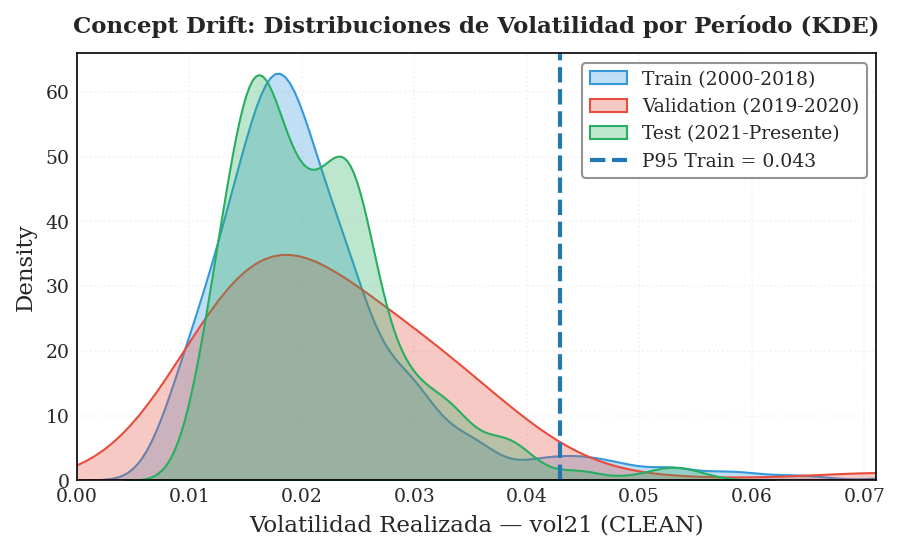

Figura guardada: fig_09_concept_drift_ks.png


In [ ]:
# Visualización del Drift (KDE Plot)
fig = plt.figure(figsize=fig_size("full"))
clean_mask = ~df['bad_vol21']

kdeplot_colors = {'train': '#3498db', 'validation': '#e74c3c', 'test': '#27ae60'}

# Gráfico KDE
sns.kdeplot(df.loc[(df['split'] == 'train') & clean_mask, 'vol21_clean'],
            label='Train (2000-2018)', fill=True, alpha=0.3, color=kdeplot_colors['train'])
sns.kdeplot(df.loc[(df['split'] == 'validation') & clean_mask, 'vol21_clean'],
            label='Validation (2019-2020)', fill=True, alpha=0.3, color=kdeplot_colors['validation'])
sns.kdeplot(df.loc[(df['split'] == 'test') & clean_mask, 'vol21_clean'],
            label='Test (2021-Presente)', fill=True, alpha=0.3, color=kdeplot_colors['test'])

# Umbral P95
plt.axvline(thresholds_clean[PERCENTILE_PRIMARY], ls='--', lw=2,
            label=f"P95 Train = {thresholds_clean[PERCENTILE_PRIMARY]:.3f}")

# Límite dinámico
x_max = df.loc[clean_mask, 'vol21_clean'].quantile(0.99) * 1.1
plt.xlim(0, x_max)

plt.title('Concept Drift: Distribuciones de Volatilidad por Período (KDE)')
# fontweight heredado de rcParams axes.titleweight='bold'
plt.xlabel('Volatilidad Realizada — vol21 (CLEAN)')
plt.legend()
# grid heredado de rcParams (alpha=0.25) — coherente con apply_thesis_style()

fig.tight_layout()
save_fig(fig, 'fig_09_concept_drift_ks', output_path=FIG_PATH)
plt.show()
plt.close(fig)
print("Figura guardada: fig_09_concept_drift_ks.png")

### Concept Drift — Densidades de Volatilidad por Período (KS Test)

**Qué muestra**
Distribuciones de densidad (KDE) de vol21_clean superpuestas por split
con estadísticos KS bilaterales para cuantificar el drift distribucional
entre períodos de entrenamiento y evaluación.

**Cómo se construye**
KDE con kernel gaussiano sobre vol21_clean por split. Test KS bilateral:
Train vs Val (KS=0.181, p=5.4e-13) y Train vs Test (KS=0.076, p=1.4e-5).
Drift en media: Val +30.6%, Test +0.4% respecto a Train.

**Por qué tiene esta forma**
La distribución de validación (2019–2020, COVID) está desplazada hacia
mayor volatilidad. La de test es cercana a train en media pero con
menos eventos extremos (2.08% vs 5.02%).

**Por qué es importante para la tesis**
Evidencia empírica del concept drift que explica los hallazgos H2-1
(GARCH F1=0) y H2-3 (LSTM threshold=0.99 no transfiere): umbrales
calibrados en validación (COVID, alta volatilidad) no generalizan
a test (post-pandemia, baja volatilidad). Justifica splits cronológicos.

## 2.4 VaR por Split

In [ ]:
train_returns_all   = df[df['split'] == 'train']['returns'].dropna()
train_returns_clean = df[(df['split'] == 'train') & (~df['bad_return'])]['returns'].dropna()

val_returns_all     = df[df['split'] == 'validation']['returns'].dropna()
val_returns_clean   = df[(df['split'] == 'validation') & (~df['bad_return'])]['returns'].dropna()

test_returns_all    = df[df['split'] == 'test']['returns'].dropna()
test_returns_clean  = df[(df['split'] == 'test') & (~df['bad_return'])]['returns'].dropna()

var_train_all  = train_returns_all.quantile(0.05)
var_train_clean= train_returns_clean.quantile(0.05)
var_val_all    = val_returns_all.quantile(0.05)
var_val_clean  = val_returns_clean.quantile(0.05)
var_test_all   = test_returns_all.quantile(0.05)
var_test_clean = test_returns_clean.quantile(0.05)

cvar_train_clean = train_returns_clean[train_returns_clean <= var_train_clean].mean()
cvar_val_clean   = val_returns_clean[val_returns_clean <= var_val_clean].mean()
cvar_test_clean  = test_returns_clean[test_returns_clean <= var_test_clean].mean()

print("VaR POR SPLIT + ANÁLISIS DE SENSIBILIDAD (ALL vs CLEAN) — RETURNS")

print("\n1. IMPACTO DE LA CONTAMINACIÓN EN VaR (RETURNS)")
print("-"*60)
print(f"{'Split':<12} {'VaR 95% (ALL)':>15} {'VaR 95% (CLEAN)':>18} {'Diferencia':>15} {'Obs CLEAN':>12}")
print("-"*60)
print(f"{'Train':<12} {var_train_all*100:>14.2f}% {var_train_clean*100:>17.2f}% {(var_train_clean-var_train_all)*100:>14.2f}% {len(train_returns_clean):>12,}")
print(f"{'Validation':<12} {var_val_all*100:>14.2f}% {var_val_clean*100:>17.2f}% {(var_val_clean-var_val_all)*100:>14.2f}% {len(val_returns_clean):>12,}")
print(f"{'Test':<12} {var_test_all*100:>14.2f}% {var_test_clean*100:>17.2f}% {(var_test_clean-var_test_all)*100:>14.2f}% {len(test_returns_clean):>12,}")

print("\n2. RIESGO DE COLA: VaR vs CVaR (datos CLEAN)")
print("-"*60)
print(f"{'Split':<12} {'VaR 95%':>12} {'CVaR 95%':>12} {'Diferencia':>15} {'Ratio CVaR/VaR':>18}")
print("-"*60)
train_ratio = abs(cvar_train_clean / var_train_clean)
val_ratio   = abs(cvar_val_clean / var_val_clean)
test_ratio  = abs(cvar_test_clean / var_test_clean)
print(f"{'Train':<12} {var_train_clean*100:>11.2f}% {cvar_train_clean*100:>11.2f}% {(cvar_train_clean-var_train_clean)*100:>14.2f}% {train_ratio:>17.2f}x")
print(f"{'Validation':<12} {var_val_clean*100:>11.2f}% {cvar_val_clean*100:>11.2f}% {(cvar_val_clean-var_val_clean)*100:>14.2f}% {val_ratio:>17.2f}x")
print(f"{'Test':<12} {var_test_clean*100:>11.2f}% {cvar_test_clean*100:>11.2f}% {(cvar_test_clean-var_test_clean)*100:>14.2f}% {test_ratio:>17.2f}x")

print("\n3. CONCEPT DRIFT EN RIESGO (basado en CLEAN)")
print("-"*60)
drift_train_val  = (var_val_clean  / var_train_clean - 1) * 100
drift_val_test   = (var_test_clean / var_val_clean  - 1) * 100
drift_train_test = (var_test_clean / var_train_clean - 1) * 100
print(f"Train → Validation: ΔVaR = {drift_train_val:+.1f}%")
print(f"Validation → Test:  ΔVaR = {drift_val_test:+.1f}%")
print(f"Train → Test:       ΔVaR = {drift_train_test:+.1f}%")

print(" \n  • La contaminación (2 días) tiene impacto MÍNIMO en VaR (cuantil)")
print("   • CVaR sí es más sensible (promedio de cola)")
print("   • Validation muestra colas más pesadas vs Train (COVID)")
print("CONCLUSIÓN: VaR/CVaR confirman cambios de régimen entre períodos")


VaR POR SPLIT + ANÁLISIS DE SENSIBILIDAD (ALL vs CLEAN) — RETURNS

1. IMPACTO DE LA CONTAMINACIÓN EN VaR (RETURNS)
------------------------------------------------------------
Split          VaR 95% (ALL)    VaR 95% (CLEAN)      Diferencia    Obs CLEAN
------------------------------------------------------------
Train                 -3.79%             -3.79%           0.00%        4,584
Validation            -5.03%             -4.94%           0.09%          503
Test                  -3.73%             -3.73%           0.00%        1,296

2. RIESGO DE COLA: VaR vs CVaR (datos CLEAN)
------------------------------------------------------------
Split             VaR 95%     CVaR 95%      Diferencia     Ratio CVaR/VaR
------------------------------------------------------------
Train              -3.79%       -5.49%          -1.70%              1.45x
Validation         -4.94%       -9.96%          -5.02%              2.02x
Test               -3.73%       -5.50%          -1.77%           

## 2.5 Análisis de Desbalanceo de Clases (CLEAN)

In [ ]:
print(f"ANÁLISIS DE DESBALANCEO - EVENTOS EXTREMOS P{PERCENTILE_PRIMARY} (CLEAN)")
print(f"{'Split':<12} {'Total':>8} {'Excluidos':>10} {'Válidos':>10} {'Extremos':>10} {'Ratio':>8} {'Desbalanceo':>14}")
print("-"*86)

for split_name in ['train', 'validation', 'test']:
    split_data = df[df['split'] == split_name]

    n_total    = len(split_data)
    n_excluded = int(split_data['bad_vol21'].sum())                 # trazable
    valid_mask = (~split_data['bad_vol21']) & (split_data['is_extreme_clean'].notna())

    n_valid   = int(valid_mask.sum())
    n_extreme = int(split_data.loc[valid_mask, 'is_extreme_clean'].sum())
    ratio     = (n_extreme / n_valid * 100) if n_valid > 0 else 0

    desbalanceo = f"1:{(n_valid - n_extreme)/n_extreme:.1f}" if n_extreme > 0 else "N/A"
    print(f"{split_name.capitalize():<12} {n_total:>8,} {n_excluded:>10,} {n_valid:>10,} {n_extreme:>10,} {ratio:>7.2f}% {desbalanceo:>14}")

print(f"\nUmbral P95 estático (CLEAN): {thresholds_clean[PERCENTILE_PRIMARY]:.6f}")
print("\nNOTA:")
print("  • Train ≈ 5% por construcción (umbral calibrado en Train)")
print("  • Desviaciones en Validation/Test reflejan drift temporal")
print("  • Excluidos = días con vol21 contaminada (bad_vol21)")

ANÁLISIS DE DESBALANCEO - EVENTOS EXTREMOS P95 (CLEAN)
Split           Total  Excluidos    Válidos   Extremos    Ratio    Desbalanceo
--------------------------------------------------------------------------------------
Train           4,584          0      4,584        230    5.02%         1:18.9
Validation        505         22        483         39    8.07%         1:11.4
Test            1,296          0      1,296         27    2.08%         1:47.0

Umbral P95 estático (CLEAN): 0.042996

NOTA:
  • Train ≈ 5% por construcción (umbral calibrado en Train)
  • Desviaciones en Validation/Test reflejan drift temporal
  • Excluidos = días con vol21 contaminada (bad_vol21)


El umbral estático P95 captura el 5.02% esperado en train, el 8.07% en validación
(período COVID) y el 2.08% en test (período post-pandemia), evidenciando la
limitación de umbrales fijos ante cambios de régimen.

- En validation (8% > 5%): el umbral es demasiado permisivo → más verdaderos
  positivos capturados, pero el modelo entrenado en 5% subestima la frecuencia
  real → riesgo de falsos negativos ante la magnitud de la crisis.
- En test (2% < 5%): el umbral es demasiado restrictivo → el modelo sobre-alerta
  respecto al régimen actual → riesgo de falsos positivos.

FIGURA: Distribución Temporal de Eventos Extremos (CLEAN)
  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB01_EDA/Figuras Notebook EDA/fig_10_distribucion_eventos_extremos.png  [6.1"×3.1" @ 300dpi]


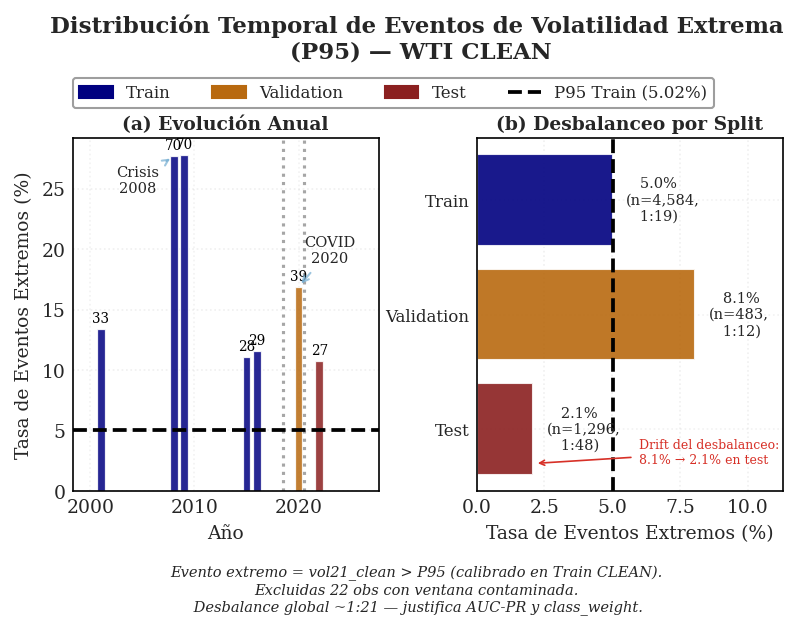

Figura guardada: fig_10_distribucion_eventos_extremos.png

RESUMEN: DESBALANCEO DE CLASES (CLEAN)
     split    n   events   rate
     train 4584 230.0000 5.0175
validation  483  39.0000 8.0745
      test 1296  27.0000 2.0833

Desbalance global: 1:21


In [ ]:
# Distribución Temporal de Eventos Extremos: Basada en vol21_clean y is_extreme_clean (CLEAN)

print("FIGURA: Distribución Temporal de Eventos Extremos (CLEAN)")

# Datos CLEAN válidos
df_clean_valid = df[
    (~df['bad_vol21']) &
    (df['is_extreme_clean'].notna())
].copy()

df_clean_valid['year'] = df_clean_valid.index.year

# Estadísticas anuales
annual = (
    df_clean_valid
    .groupby(['year', 'split'])['is_extreme_clean']
    .agg(n='count', events='sum')
    .reset_index()
)
annual['rate'] = annual['events'] / annual['n'] * 100

# Estadísticas por split
split_order = ['train', 'validation', 'test']
split_stats = (
    df_clean_valid
    .groupby('split')['is_extreme_clean']
    .agg(n='count', events='sum')
    .reset_index()
)
split_stats['rate'] = split_stats['events'] / split_stats['n'] * 100
split_stats['split'] = pd.Categorical(
    split_stats['split'],
    categories=split_order,
    ordered=True
)
split_stats = split_stats.sort_values('split').reset_index(drop=True)

# Referencia P95 calibrada en train
TRAIN_RATE = split_stats.loc[split_stats['split']=='train', 'rate'].values[0]
P95_REF = TRAIN_RATE

# FIGURA
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=fig_size("2x1", aspect=0.50),
                                gridspec_kw={'width_ratios': [1, 1],
                                             'wspace': 0.32})

events_colors = {'train': 'navy', 'validation': '#B8690F', 'test': '#8B2020'}

# PANEL (a): Evolución anual
bar_colors = annual['split'].map(events_colors)

ax1.bar(
    annual['year'], annual['rate'],
    color=bar_colors, alpha=0.85,
    edgecolor='white', linewidth=0.6,
    width=0.75)

# Número de eventos sobre cada barra
for _, row in annual.iterrows():
    if row['events'] > 0:
        ax1.text(row['year'], row['rate'] + 0.3,
                 f"{int(row['events'])}",
                 ha='center', va='bottom', fontsize=6.5, color='black')

# Separadores de split
split_year_boundaries = df_clean_valid.groupby('split')['year'].min().sort_values()
if 'validation' in split_year_boundaries:
    ax1.axvline(split_year_boundaries['validation'] - 0.5, color='gray', linestyle=':', alpha=0.7)
if 'test' in split_year_boundaries:
    ax1.axvline(split_year_boundaries['test'] - 0.5, color='gray', linestyle=':', alpha=0.7)

# Línea referencia P95
ax1.axhline(y=P95_REF, color='black', linestyle='--', linewidth=1.8,
            label=f'P{PERCENTILE_PRIMARY} Train ({P95_REF:.2f}%)')

# Anotaciones
if 2008 in annual['year'].values:
    rate_2008 = annual.loc[annual['year']==2008, 'rate'].values[0]
    ax1.annotate('Crisis\n2008', xy=(2008, rate_2008), xytext=(2004.5, rate_2008 - 3),
                 fontsize=7, ha='center',
                 arrowprops=dict(arrowstyle='->', color=COLOR_VAR, alpha=0.7))

if 2020 in annual['year'].values:
    rate_2020 = annual.loc[annual['year']==2020, 'rate'].values[0]
    ax1.annotate('COVID\n2020', xy=(2020, rate_2020), xytext=(2023, rate_2020 + 2),
                 fontsize=7, ha='center',
                 arrowprops=dict(arrowstyle='->', color=COLOR_VAR, alpha=0.7))

# Leyenda con patches de colores
legend_patches = [
    mpatches.Patch(color=events_colors['train'], label='Train'),
    mpatches.Patch(color=events_colors['validation'], label='Validation'),
    mpatches.Patch(color=events_colors['test'], label='Test'),
    plt.Line2D([0], [0], color='black', linestyle='--', linewidth=1.8,
               label=f'P{PERCENTILE_PRIMARY} Train ({P95_REF:.2f}%)')
]
ax1.legend(handles=legend_patches, loc='upper left', bbox_to_anchor=(0.0, 1.17),fontsize=8,ncol=4,
           columnspacing=2.5,frameon=True, facecolor='white',
           edgecolor='0.6',framealpha=0.95, borderaxespad=0.0,)

ax1.set_xlabel('Año',fontsize=9)
ax1.set_ylabel('Tasa de Eventos Extremos (%)',fontsize=9)
ax1.set_title('(a) Evolución Anual', fontsize=9, fontweight='bold', pad=4)
ax1.set_ylim(bottom=0)
ax1.yaxis.set_major_locator(ticker.MultipleLocator(5))
ax1.tick_params(axis='x')
ax1.grid(axis='y', alpha=0.3)

# PANEL (b): Desbalanceo por split
LABELS = {'train': 'Train', 'validation': 'Validation', 'test': 'Test'}

bars = ax2.barh(
    range(len(split_stats)),
    split_stats['rate'],
    color=[events_colors[s] for s in split_stats['split']],
    alpha=0.9,
    edgecolor='white'
)

ax2.axvline(x=P95_REF, linestyle='--', linewidth=1.8, color='black')

for i, row in split_stats.iterrows():
    rate = row['rate']
    n_obs = int(row['n'])
    n_ev = int(row['events'])
    ratio = int(n_obs/n_ev) if n_ev > 0 else 0
    ax2.text(rate + 0.5, i, f'   {rate:.1f}% \n(n={n_obs:,},\n   1:{ratio})',
             va='center', fontsize=7)

ax2.set_yticks(range(len(split_stats)))
ax2.set_yticklabels([LABELS[s] for s in split_stats['split']],fontsize=8)
ax2.invert_yaxis()
ax2.set_xlabel('Tasa de Eventos Extremos (%)',fontsize=9)
ax2.set_title('(b) Desbalanceo por Split', fontsize=9, fontweight='bold', pad=4)
ax2.set_xlim(0, max(split_stats['rate']) * 1.4)
ax2.grid(axis='x', alpha=0.3)
ax2.annotate('Drift del desbalanceo:\n8.1% → 2.1% en test',
              xy=(2.1, 2.3),
              xytext=(6, 2.3),
              fontsize=6, color=COLOR_EXTREMO,
              arrowprops=dict(arrowstyle='->', color=COLOR_EXTREMO, lw=0.8))

# Título general
fig.suptitle(
    f'Distribución Temporal de Eventos de Volatilidad Extrema\n (P{PERCENTILE_PRIMARY}) — WTI CLEAN',
    fontsize=11, fontweight='bold', y=1.15
)

# Nota al pie
total_n = split_stats['n'].sum()
total_ev = split_stats['events'].sum()
fig.text(
    0.5, -0.15,
    f'Evento extremo = vol21_clean > P{PERCENTILE_PRIMARY} (calibrado en Train CLEAN).\n'
    f'Excluidas {df["bad_vol21"].sum()} obs con ventana contaminada.\n '
    f'Desbalance global ~1:{int(total_n/total_ev)} — justifica AUC-PR y class_weight.',
    ha='center', fontsize=7, style='italic'
)

plt.tight_layout(rect=[0.0, 0.0, 1, 0.98],h_pad=2.7)
save_fig(fig, 'fig_10_distribucion_eventos_extremos', output_path=FIG_PATH)
plt.show()
plt.close()

print("Figura guardada: fig_10_distribucion_eventos_extremos.png")

# TABLA RESUMEN
print("\nRESUMEN: DESBALANCEO DE CLASES (CLEAN)")
print(split_stats[['split', 'n', 'events', 'rate']].to_string(index=False))
print(f"\nDesbalance global: 1:{int(total_n/total_ev)}")

### Distribución Temporal de Eventos de Volatilidad Extrema (P95)

**Qué muestra**
Panel (a): número de eventos extremos (is_extreme_clean=1) por año
calendario. Panel (b): tasa de eventos y ratio de desbalanceo por split,
evidenciando el drift de frecuencia entre Train, Val y Test.

**Cómo se construye**
Conteo de is_extreme_clean=1 agrupado por año. Tasas: Train 5.02%
(1:18.9), Val 8.07% (1:11.4, COVID), Test 2.08% (1:47.0). El umbral
P95=4.2996% es fijo — el drift en tasas es real, no un artefacto.

**Por qué tiene esta forma**
Los eventos se concentran en 2008–2009 (GFC), 2014–2016 (crisis petróleo)
y 2020 (COVID-19). Los períodos 2017–2019 y 2021–2026 son relativamente
tranquilos, produciendo el severo desbalanceo en test (1:47).

**Por qué es importante para la tesis**
El drift Train→Val→Test en la tasa (5%→8%→2%) explica los hallazgos
H2-1 y H2-3: umbrales calibrados en validación (alta tasa COVID) no
generalizan a test (baja tasa post-pandemia). Justifica reportar F1
en test como métrica principal del benchmark.

---
# PARTE III: ROLLING VaR (OPCIÓN C)
---

## 3.1 Cálculo de Rolling VaR

In [ ]:
# ROLLING VaR (252 días)

df['var_rolling_252'] = df['returns'].rolling(
    window=ROLLING_VAR_WINDOW,
    min_periods=126
).quantile(0.05)

# shift(1): usar VaR de ayer para predecir hoy (anti-leakage)
# 1 NaN adicional respecto a var_rolling_252 — manejado por dropna en NB02
df['var_rolling_252_lag1'] = df['var_rolling_252'].shift(1)

print("ROLLING VaR (252 días)")
print(f"  var_rolling_252      válidos: {df['var_rolling_252'].notna().sum():,}")
print(f"  var_rolling_252_lag1 válidos: {df['var_rolling_252_lag1'].notna().sum():,}")
print(f"  Diferencia:      "
      f"{df['var_rolling_252'].notna().sum() - df['var_rolling_252_lag1'].notna().sum()}")
print(f"  VaR Rolling promedio: {df['var_rolling_252'].mean()*100:.2f}%")
print(f"  VaR Rolling mínimo:   {df['var_rolling_252'].min()*100:.2f}%"
      f" → {df['var_rolling_252'].idxmin().date()}")
print(f"  VaR Rolling máximo:   {df['var_rolling_252'].max()*100:.2f}%"
      f" → {df['var_rolling_252'].idxmax().date()}")

rolling_mask = df['var_rolling_252_lag1'].notna()
violations_rolling = (df.loc[rolling_mask, 'returns'] < df.loc[rolling_mask, 'var_rolling_252_lag1']).sum()
n_rolling = rolling_mask.sum()
pct_rolling = violations_rolling / n_rolling * 100
calibrado = " bien calibrado" if 4.5 <= pct_rolling <= 5.5 else "⚠ revisar calibración"

print(f"\nBacktesting Rolling VaR 95% (out-of-sample):")
print(f"  Violaciones: {violations_rolling:,} / {n_rolling:,} ({pct_rolling:.2f}%) — {calibrado}")
print(f"  Esperadas:   {n_rolling*0.05:.0f} (5.00%)")

ROLLING VaR (252 días)
  var_rolling_252      válidos: 6,260
  var_rolling_252_lag1 válidos: 6,259
  Diferencia:      1
  VaR Rolling promedio: -3.85%
  VaR Rolling mínimo:   -8.27% → 2020-06-11
  VaR Rolling máximo:   -1.59% → 2014-06-23

Backtesting Rolling VaR 95% (out-of-sample):
  Violaciones: 342 / 6,259 (5.46%) —  bien calibrado
  Esperadas:   313 (5.00%)


El Rolling VaR se calcula sobre la serie completa incluyendo el tratamiento de clipping. El análisis de sensibilidad ALL vs CLEAN muestra una diferencia de 0.012%, confirmando que el tratamiento del precio negativo no distorsiona materialmente el análisis de riesgo dinámico.

El backtesting rolling es genuinamente out-of-sample: el VaR del día t se
calcula con los 252 días anteriores y se evalúa contra el retorno observado
en t — sin ningún dato futuro. A diferencia de la verificación aritmética
in-sample de la Sección 0.5, este resultado constituye evidencia real de
calibración del modelo de riesgo.

## 3.2 Evolución Temporal del Riesgo

  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB01_EDA/Figuras Notebook EDA/fig_11_rolling_var_evolucion.png  [6.1"×8.3" @ 300dpi]


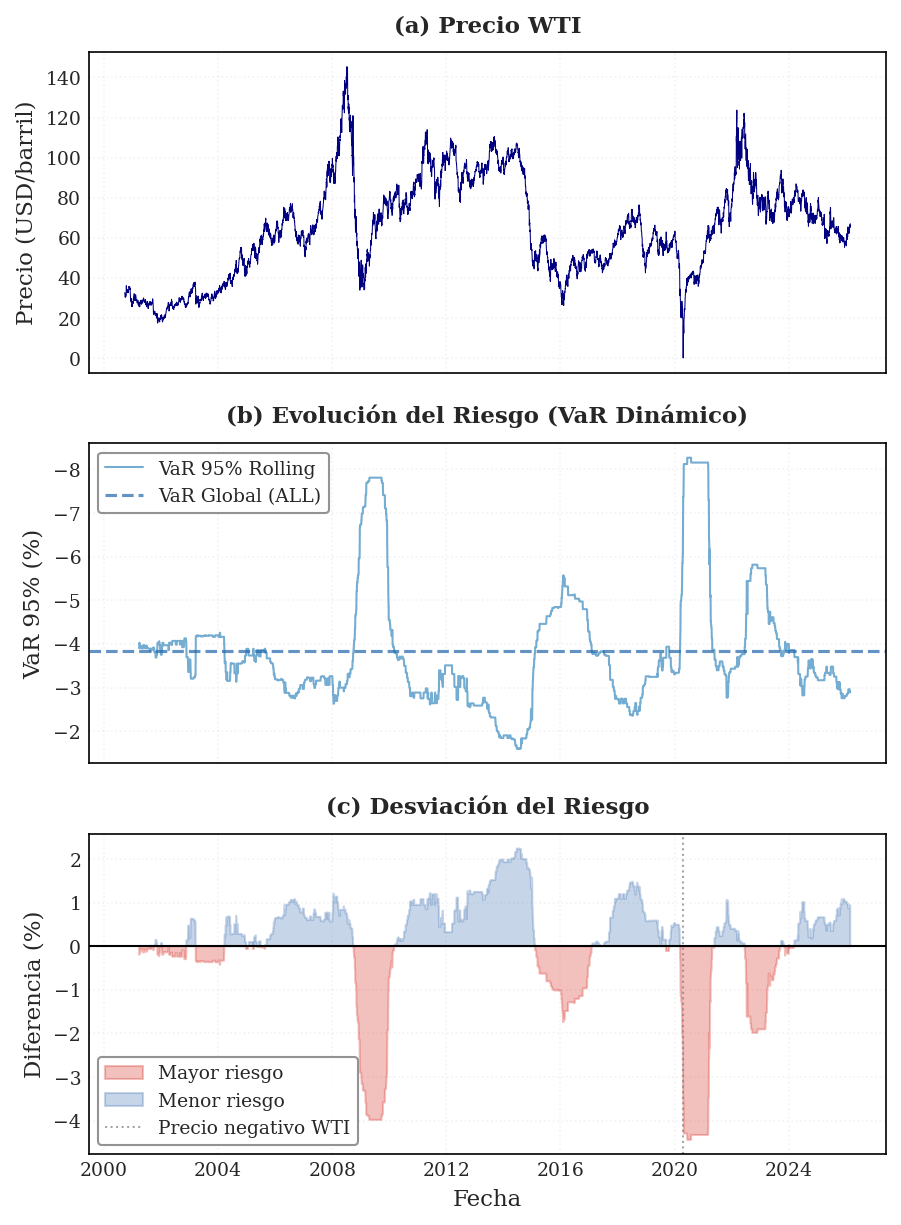

Figura guardada: fig_11_rolling_var_evolucion.png


In [ ]:
# VISUALIZACIÓN: EVOLUCIÓN ROLLING VaR

fig, axes = plt.subplots(3, 1, figsize=fig_size("tall"), sharex=True)

ax1 = axes[0]
ax1.plot(df.index, df['wti'], color='navy', lw=0.5)
ax1.set_ylabel('Precio (USD/barril)')
ax1.set_title('(a) Precio WTI', fontweight='bold')

ax2 = axes[1]
ax2.plot(df.index, df['var_rolling_252'] * 100, color=COLOR_VAR, lw=1, label='VaR 95% Rolling')
ax2.axhline(var_global_95_all * 100, color=SPLIT_COLORS['train'], ls='--', lw=1.5, alpha=0.7, label='VaR Global (ALL)')
ax2.set_ylabel('VaR 95% (%)')
ax2.set_title('(b) Evolución del Riesgo (VaR Dinámico)', fontweight='bold')
ax2.legend(fontsize=9)
ax2.invert_yaxis()

ax3 = axes[2]
var_diff = (df['var_rolling_252'] - var_global_95_all) * 100
ax3.fill_between(df.index, 0, var_diff, where=(var_diff < 0),
                 color=COLOR_EXTREMO, alpha=0.3, label='Mayor riesgo')
ax3.fill_between(df.index, 0, var_diff, where=(var_diff >= 0),
                 color=COLOR_CLEAN, alpha=0.3, label='Menor riesgo')
ax3.axhline(0, color='black', lw=1)
ax3.axvline(pd.Timestamp('2020-04-20'), color='gray',
            ls=':', lw=1, alpha=0.7, label='Precio negativo WTI')
ax3.set_ylabel('Diferencia (%)')
ax3.set_xlabel('Fecha')
ax3.set_title('(c) Desviación del Riesgo', fontweight='bold')
ax3.legend()

plt.tight_layout(h_pad=1.5)

save_fig(fig, 'fig_11_rolling_var_evolucion', output_path=FIG_PATH)
plt.show()
plt.close()

print("Figura guardada: fig_11_rolling_var_evolucion.png")


### Evolución del VaR Dinámico Rolling (252 días) — WTI 2000–2026

**Qué muestra**
Tres paneles: (a) precio WTI con splits marcados, (b) VaR dinámico
rolling de 252 días al percentil 95, (c) desviación del VaR respecto
al promedio histórico.

**Cómo se construye**
VaR rolling = quantile(retornos, 0.05) sobre ventana de 252 días
(min_periods=126) sobre el dataset CLEAN. NaN del warm-up (primeros
126 días) son esperados y documentados.

**Por qué tiene esta forma**
Cuatro picos de riesgo: GFC 2008–2009 (VaR pico≈-8.5%), crisis petróleo
2014–2016, COVID 2020. El VaR dinámico se adapta al régimen local,
a diferencia del umbral estático P95.

**Por qué es importante para la tesis**
Provee contexto del VaR dinámico como benchmark alternativo de detección
de riesgo (is_extreme_dynamic). La baja coincidencia con P95 estático
(Jaccard=24.7%) confirma que capturan fenómenos distintos, justificando
usar el umbral estático como target del benchmark.

## 3.3 Comparación: VaR Estático vs Dinámico

**OBJETIVO:** Evaluar si el umbral dinámico P95 rolling captura mejor los eventos extremos que el estático P95.


In [ ]:
# 3.3 ESTÁTICO VS DINÁMICO
# Máscara de válidos para ambos umbrales simultáneamente
valid_mask = (
    df['is_extreme_clean'].notna() &
    df['is_extreme_dynamic'].notna() &
    (~df['bad_vol21'])
)
df_valid = df[valid_mask].copy()

#Contingencia global
both_extreme = ((df_valid['is_extreme_clean'] == 1) &
                (df_valid['is_extreme_dynamic'] == 1)).sum()
only_static  = ((df_valid['is_extreme_clean'] == 1) &
                (df_valid['is_extreme_dynamic'] == 0)).sum()
only_dynamic = ((df_valid['is_extreme_clean'] == 0) &
                (df_valid['is_extreme_dynamic'] == 1)).sum()
neither      = ((df_valid['is_extreme_clean'] == 0) &
                (df_valid['is_extreme_dynamic'] == 0)).sum()

total_static  = int(df_valid['is_extreme_clean'].sum())
total_dynamic = int(df_valid['is_extreme_dynamic'].sum())

#Métricas de coincidencia
coverage_dyn_on_static = (both_extreme / total_static  * 100) if total_static  > 0 else 0
coverage_static_on_dyn = (both_extreme / total_dynamic * 100) if total_dynamic > 0 else 0
jaccard = (both_extreme / (total_static + total_dynamic - both_extreme) * 100) \
          if (total_static + total_dynamic - both_extreme) > 0 else 0

#Métricas por split
split_stats = {}
for split in ['train', 'validation', 'test']:
    mask   = (df['split'] == split) & valid_mask
    n_s    = int(df.loc[mask, 'is_extreme_clean'].sum())
    n_d    = int(df.loc[mask, 'is_extreme_dynamic'].sum())
    n_both = int(((df.loc[mask, 'is_extreme_clean'] == 1) &
                  (df.loc[mask, 'is_extreme_dynamic'] == 1)).sum())
    jacc_s = (n_both / (n_s + n_d - n_both) * 100) if (n_s + n_d - n_both) > 0 else 0
    ratio  = (n_d / n_s) if n_s > 0 else np.nan
    split_stats[split] = dict(n_s=n_s, n_d=n_d, n_both=n_both,
                               jaccard=jacc_s, ratio=ratio)

print("=" * 70)
print("   ESTÁTICO VS DINÁMICO — ANÁLISIS COMPARATIVO")
print("=" * 70)

print("\nDETECCIONES GLOBALES:")
print(f"  Ambos:     {both_extreme:,} ({both_extreme/len(df_valid)*100:.2f}%)")
print(f"  Solo Est:  {only_static:,}  → extremo histórico no detectado como anomalía local")
print(f"  Solo Dyn:  {only_dynamic:,}  → anomalía local sin referencia histórica")
print(f"  Ninguno:   {neither:,} ({neither/len(df_valid)*100:.2f}%)")

print(f"\nMÉTRICAS GLOBALES:")
print(f"  Jaccard:           {jaccard:.1f}%")
print(f"  Cobertura Dyn→Est: {coverage_dyn_on_static:.1f}%")
print(f"  Cobertura Est→Dyn: {coverage_static_on_dyn:.1f}%")

print(f"\n{'PERÍODO':<12} {'Est':>6} {'Dyn':>6} {'Ambos':>7} "
      f"{'Dyn|Est':>9} {'Est|Dyn':>9} {'Jaccard':>9} {'Ratio':>8}")
print("─" * 72)
for split, st in split_stats.items():
    # Dyn|Est: de los que estático detecta, cuántos también detecta dinámico
    dyn_on_est = (st['n_both'] / st['n_s']  * 100) if st['n_s']  > 0 else 0
    # Est|Dyn: de los que dinámico detecta, cuántos también detecta estático
    est_on_dyn = (st['n_both'] / st['n_d']  * 100) if st['n_d']  > 0 else 0
    ratio_str  = f"{st['ratio']:.2f}x" if not np.isnan(st['ratio']) else "N/A"
    print(f"{split.capitalize():<12} {st['n_s']:>6} {st['n_d']:>6} "
          f"{st['n_both']:>7} {dyn_on_est:>8.1f}% {est_on_dyn:>8.1f}% "
          f"{st['jaccard']:>8.1f}% {ratio_str:>8}")

# Discrepancias: rangos de fechas para trazabilidad
only_static_mask  = (df['is_extreme_clean'] == 1) & (df['is_extreme_dynamic'] == 0)
only_dynamic_mask = (df['is_extreme_clean'] == 0) & (df['is_extreme_dynamic'] == 1)

print(f"\nDISCREPANCIAS:")
print(f"  Solo estático:  {only_static_mask.sum()} eventos | "
      f"{df[only_static_mask].index.min().date()} → "
      f"{df[only_static_mask].index.max().date()}")
print(f"  Solo dinámico:  {only_dynamic_mask.sum()} eventos | "
      f"{df[only_dynamic_mask].index.min().date()} → "
      f"{df[only_dynamic_mask].index.max().date()}")

avg_dynamic = df['p95_vol21_rolling_252'].mean() * 100
print(f"""
{"_" * 70}
CONCLUSIONES
{"_" * 70}
ESTÁTICO  (P95 = {thresholds_clean[PERCENTILE_PRIMARY]*100:.2f}%):
  Sin data leakage  |  Reproducible  |  Ideal para entrenamiento

DINÁMICO  (P95 Rolling {ROLLING_VAR_WINDOW}d, promedio = {avg_dynamic:.2f}%):
  Adaptativo  |  Captura drift  |  Benchmark realista en producción

EVIDENCIA EMPÍRICA:
  Jaccard global {jaccard:.1f}% → criterios complementarios, no sustitutos
  Jaccard en Validation > Jaccard en Test → COVID extremo en ambos,
  post-pandemia heterogéneo → confirma drift estructural entre splits
""")

   ESTÁTICO VS DINÁMICO — ANÁLISIS COMPARATIVO

DETECCIONES GLOBALES:
  Ambos:     172 (2.70%)
  Solo Est:  124  → extremo histórico no detectado como anomalía local
  Solo Dyn:  401  → anomalía local sin referencia histórica
  Ninguno:   5,666 (89.05%)

MÉTRICAS GLOBALES:
  Jaccard:           24.7%
  Cobertura Dyn→Est: 58.1%
  Cobertura Est→Dyn: 30.0%

PERÍODO         Est    Dyn   Ambos   Dyn|Est   Est|Dyn   Jaccard    Ratio
────────────────────────────────────────────────────────────────────────
Train           230    425     124     53.9%     29.2%     23.4%    1.85x
Validation       39     53      29     74.4%     54.7%     46.0%    1.36x
Test             27     95      19     70.4%     20.0%     18.4%    3.52x

DISCREPANCIAS:
  Solo estático:  124 eventos | 2001-12-17 → 2022-04-14
  Solo dinámico:  401 eventos | 2003-01-29 → 2025-07-10

______________________________________________________________________
CONCLUSIONES
______________________________________________________________

El índice Jaccard de 24.7% evidencia que ambos criterios capturan fenómenos distintos:

* El umbral estático (P95-CLEAN) identifica eventos extremos en términos históricos absolutos, es decir, días cuya volatilidad supera el 5% peor del período de entrenamiento.
* El umbral dinámico (P95 rolling 252d) detecta anomalías relativas al régimen local de volatilidad, adaptándose a los cambios de régimen del mercado.


* El umbral dinámico se utiliza como benchmark adaptativo para análisis de sensibilidad y del umbral estático como criterio principal de etiquetado por su comparabilidad entre periodos y ausencia de data leakage.

  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB01_EDA/Figuras Notebook EDA/fig_12_estatico_vs_dinamico.png  [6.1"×8.3" @ 300dpi]


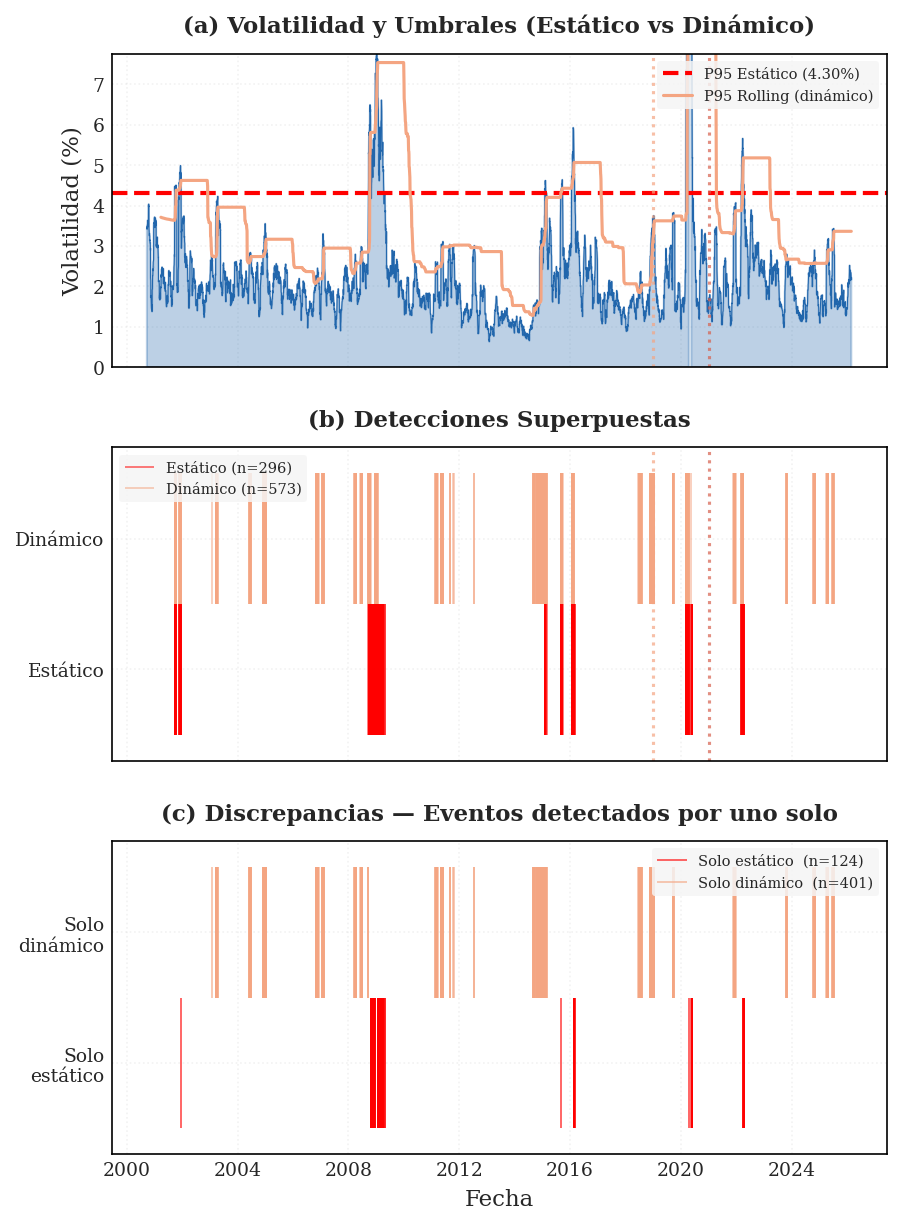

Figura guardada: fig_12_estatico_vs_dinamico.png


In [ ]:
fig, axes = plt.subplots(3, 1, figsize=fig_size("tall"), sharex=True)

COLOR_EST = 'red'       # umbral estático — neutro

# Panel (a): Volatilidad con umbrales estático vs dinámico
ax1 = axes[0]
ax1.fill_between(df.index, 0, df['vol21_clean'] * 100,
                 alpha=0.3, color=COLOR_NORMAL)   # ← variable global
ax1.plot(df.index, df['vol21_clean'] * 100,
         lw=0.5, color=COLOR_NORMAL)

ax1.axhline(thresholds_clean[PERCENTILE_PRIMARY] * 100,
            ls='--', lw=2, color=COLOR_EST,
            label=f'P95 Estático ({thresholds_clean[PERCENTILE_PRIMARY]*100:.2f}%)')
ax1.plot(df.index, df['p95_vol21_rolling_252'] * 100,
         lw=1.5, color=COLOR_DYN, label='P95 Rolling (dinámico)')

ax1.set_ylabel('Volatilidad (%)')
ax1.set_title('(a) Volatilidad y Umbrales (Estático vs Dinámico)', fontweight='bold')
ax1.legend(loc='upper right', fontsize=7, facecolor='whitesmoke', edgecolor='none')
ax1.set_ylim(0, df['vol21_clean'].dropna().quantile(0.99) * 100 * 1.2)

# Panel (b): Detecciones superpuestas
ax2 = axes[1]
extreme_static  = df.index[df['is_extreme_clean']   == 1]
extreme_dynamic = df.index[df['is_extreme_dynamic']  == 1]

ax2.vlines(extreme_static,  0,   0.5, colors=COLOR_EST, alpha=0.6, lw=0.8,
           label=f'Estático (n={len(extreme_static):,})')
ax2.vlines(extreme_dynamic, 0.5, 1,   colors=COLOR_DYN, alpha=0.6, lw=0.8,
           label=f'Dinámico (n={len(extreme_dynamic):,})')

ax2.set_yticks([0.25, 0.75])
ax2.set_yticklabels(['Estático', 'Dinámico'])
ax2.set_title('(b) Detecciones Superpuestas', fontweight='bold')
ax2.legend(loc='upper left', fontsize=7,facecolor='whitesmoke', edgecolor='none')
ax2.set_ylim(-0.1, 1.1)

# Líneas de separación train/val/test
for ax in [ax1, ax2]:
    for split_name in ['validation', 'test']:
        split_start = df[df['split'] == split_name].index.min()
        if pd.notna(split_start):
            ax.axvline(split_start, color=SPLIT_COLORS[split_name],
                       ls=':', alpha=0.7, lw=1.5)

# Panel (c): Discrepancias
ax3 = axes[2]
only_static_idx  = df.index[(df['is_extreme_clean']   == 1) &
                              (df['is_extreme_dynamic'] == 0)]
only_dynamic_idx = df.index[(df['is_extreme_clean']   == 0) &
                              (df['is_extreme_dynamic'] == 1)]

ax3.vlines(only_static_idx,  0,   0.5, colors=COLOR_EST, alpha=0.7, lw=0.8,
           label=f'Solo estático  (n={len(only_static_idx):,})')
ax3.vlines(only_dynamic_idx, 0.5, 1,   colors=COLOR_DYN, alpha=0.7, lw=0.8,
           label=f'Solo dinámico  (n={len(only_dynamic_idx):,})')

ax3.set_yticks([0.25, 0.75])
ax3.set_yticklabels(['Solo\nestático', 'Solo\ndinámico'])
ax3.set_title('(c) Discrepancias — Eventos detectados por uno solo', fontweight='bold')
ax3.set_xlabel('Fecha')
ax3.legend(loc='upper right', fontsize=7, facecolor='whitesmoke', edgecolor='none')
ax3.set_ylim(-0.1, 1.1)

ax3.xaxis.set_major_locator(mdates.YearLocator(4))
ax3.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.setp(ax3.xaxis.get_majorticklabels(), rotation=0, ha='center')

plt.tight_layout(h_pad=1.5)
save_fig(fig, 'fig_12_estatico_vs_dinamico', output_path=FIG_PATH)

plt.show()
plt.close()
print("Figura guardada: fig_12_estatico_vs_dinamico.png")

### Comparación: Umbral P95 Estático vs Umbral Dinámico Rolling

**Qué muestra**
Tres paneles: (a) vol21_clean con umbral estático P95=4.30% y umbral
dinámico rolling superpuestos, (b) eventos detectados por cada criterio,
(c) discrepancias — días donde solo uno de los criterios detecta extremo.

**Cómo se construye**
Umbral estático: P95=4.2996% calibrado en train_clean (constante).
Umbral dinámico: p95_vol21_rolling_252 (quantile móvil de 252 días).
Índice Jaccard = |A intersección B| / |A unión B| = 24.7%.

**Por qué tiene esta forma**
El umbral dinámico baja en períodos tranquilos (post-2021), capturando
shocks relativos aunque no sean absolutos. El 75.3% de discrepancia
refleja que capturan dos conceptos distintos de "extremo".

**Por qué es importante para la tesis**
Justifica usar el umbral estático como target del benchmark: la
comparabilidad entre splits requiere umbral fijo. El dinámico se
documenta como benchmark adaptativo para análisis de sensibilidad,
no como variable de entrenamiento — decisión inamovible del diseño.

---
# PARTE IV: VISUALIZACIONES
---

## 4.1 Serie temporal unificada

  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB01_EDA/Figuras Notebook EDA/fig_13_serie_temporal_unificada.png  [6.1"×8.3" @ 300dpi]


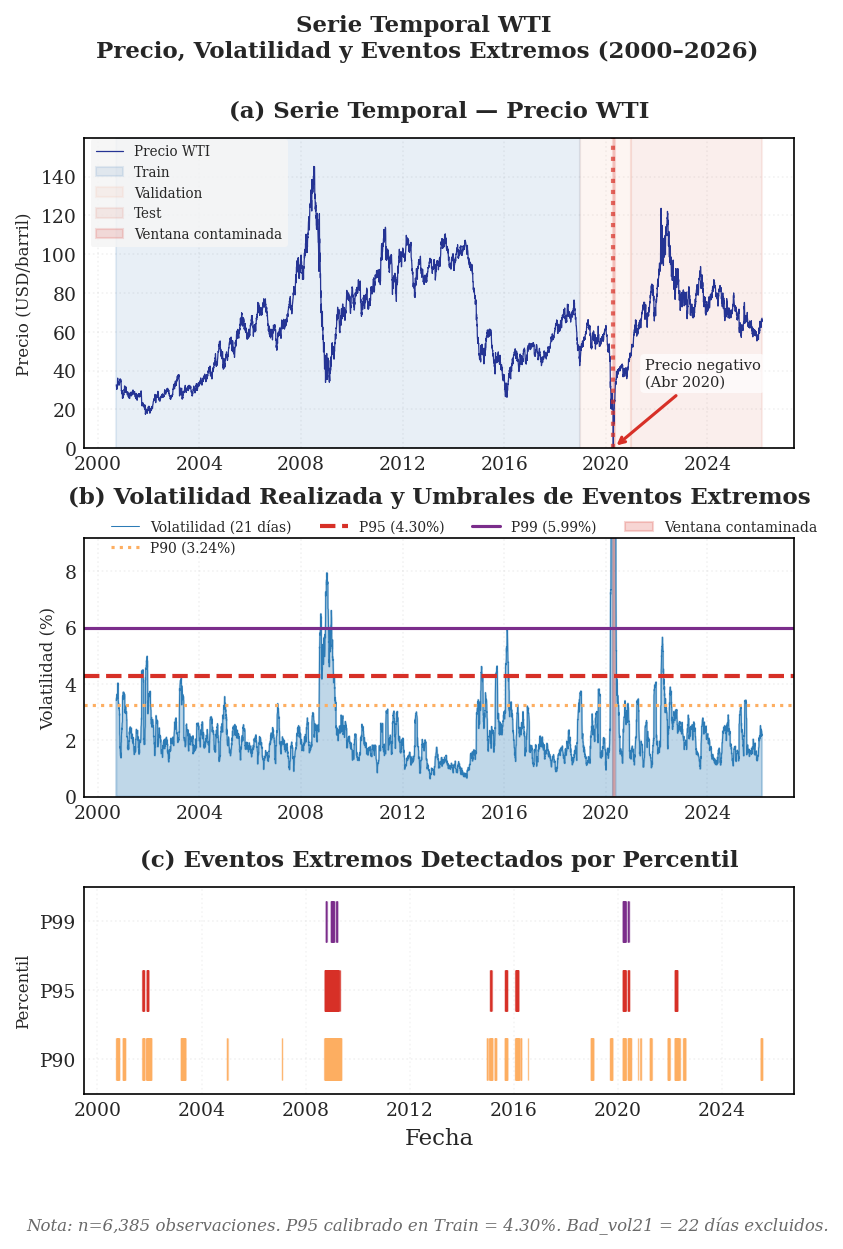

Figura guardada: fig_13_serie_temporal_unificada.png


In [ ]:
# SERIE TEMPORAL UNIFICADA — WTI

df_plot = df.copy()

fig = plt.figure(figsize=fig_size("tall"))
gs = gridspec.GridSpec(3, 1, figure=fig, height_ratios=[1.2, 1, 0.8], hspace=0.35)

# ==== PANEL (a): PRECIO ====
ax1 = fig.add_subplot(gs[0])
ax1.plot(df_plot.index, df_plot['wti'], color=COLOR_PRECIO, lw=0.6, label='Precio WTI')

# Sombrear splits
for split, color in SPLIT_COLORS.items():
    mask = df_plot['split'] == split
    if mask.any():
        ax1.axvspan(df_plot[mask].index.min(), df_plot[mask].index.max(),
                   alpha=0.1, color=color, label=split.capitalize())

# Evento precio negativo
if (df_plot['wti_raw'] < 0).any():
    neg_date = df_plot[df_plot['wti_raw'] < 0].index[0]
    ax1.axvline(neg_date, color=COLOR_EXTREMO, ls=':', lw=2, alpha=0.7)
    ax1.annotate(
    'Precio negativo\n(Abr 2020)',
    xy=(neg_date, 0), xytext=(15, 30), textcoords='offset points',
    fontsize=7,
    bbox=dict(boxstyle='round', pad=0.3, facecolor='white', edgecolor='none', alpha=0.7),
    arrowprops=dict(arrowstyle='->', color=COLOR_EXTREMO, lw=1.5))
# Ventana contaminada
if df_plot['bad_vol21'].any():
    contaminated = df_plot.index[df_plot['bad_vol21']]
    ax1.axvspan(contaminated.min(), contaminated.max(),
                alpha=0.15, color=COLOR_EXTREMO, label='Ventana contaminada')

ax1.set_ylabel('Precio (USD/barril)',fontsize=8)
ax1.set_title('(a) Serie Temporal — Precio WTI', fontweight='bold')
ax1.legend(loc='upper left', fontsize=6.5, facecolor='whitesmoke', bbox_to_anchor=(0.0, 1.02),edgecolor='none')
ax1.set_ylim(0, df_plot['wti'].max() * 1.1)


# (b): VOLATILIDAD ====
ax2 = fig.add_subplot(gs[1])

ax2.fill_between(df_plot.index, 0, df_plot['vol21_clean']*100,
                 alpha=0.3, color=COLOR_VOL)
ax2.plot(df_plot.index, df_plot['vol21_clean']*100,
         lw=0.5, color=COLOR_VOL, label='Volatilidad (21 días)')

# Umbrales P90, P95, P99
ax2.axhline(thresholds_clean[90]*100, color=COLORS_P[90], ls=':', lw=1.5,
            label=f'P90 ({thresholds_clean[90]*100:.2f}%)')
ax2.axhline(thresholds_clean[PERCENTILE_PRIMARY]*100, color=COLORS_P[PERCENTILE_PRIMARY], ls='--', lw=2,
            label=f'P95 ({thresholds_clean[PERCENTILE_PRIMARY]*100:.2f}%)')
ax2.axhline(thresholds_clean[99]*100, color=COLORS_P[99], ls='-', lw=1.5,
            label=f'P99 ({thresholds_clean[99]*100:.2f}%)')

# Ventana contaminada
if df_plot['bad_vol21'].any():
    contaminated = df_plot.index[df_plot['bad_vol21']]
    ax2.axvspan(contaminated.min(), contaminated.max(),
                alpha=0.2, color=COLOR_EXTREMO, label='Ventana contaminada')

ax2.set_ylabel('Volatilidad (%)',fontsize=8)
ax2.set_title('(b) Volatilidad Realizada y Umbrales de Eventos Extremos', fontweight='bold',pad=17)
ax2.legend(loc='upper right', fontsize=6.7, facecolor='whitesmoke', ncol=4, bbox_to_anchor=(1.05, 1.12),frameon=False)
ax2.set_ylim(0, df_plot['vol21_clean'].quantile(0.995)*100*1.2)


# (c): EVENTOS + ZOOM COVID
ax3 = fig.add_subplot(gs[2])

# Eventos por percentil
for i, p in enumerate([90, 95, 99]):
    dates = df_plot.index[df_plot[f'is_extreme_p{p}_clean'] == 1]
    ax3.vlines(dates, i+0.7, i+1.3, colors=COLORS_P[p], alpha=0.5, lw=0.6)

ax3.set_yticks([1, 2, 3])
ax3.set_yticklabels(['P90', 'P95', 'P99'])
ax3.set_xlabel('Fecha')
ax3.set_ylabel('Percentil',fontsize=8)
ax3.set_title('(c) Eventos Extremos Detectados por Percentil', fontweight='bold')
ax3.set_ylim(0.5, 3.5)
ax3.grid(axis='x', alpha=0.2)

# Formato fechas
for ax in [ax1, ax2, ax3]:
    ax.xaxis.set_major_locator(mdates.YearLocator(4))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.setp(ax3.xaxis.get_majorticklabels(), rotation=0, ha='center')

# Título general
fig.suptitle('Serie Temporal WTI \nPrecio, Volatilidad y Eventos Extremos (2000–2026)',
             fontsize=11, fontweight='bold')

# Nota
fig.text(0.5, 0.0,
         f'Nota: n={len(df_plot):,} observaciones. '
         f'P95 calibrado en Train = {thresholds_clean[PERCENTILE_PRIMARY]*100:.2f}%. '
         f'Bad_vol21 = {df_plot["bad_vol21"].sum()} días excluidos.',
         ha='center', fontsize=8, style='italic', color='dimgray')

plt.tight_layout(rect=[0, 0.0, 1, 0.98], w_pad=50)
save_fig(fig, 'fig_13_serie_temporal_unificada', output_path=FIG_PATH)
plt.show()
plt.close()

print("Figura guardada: fig_13_serie_temporal_unificada.png")

### Serie Temporal Unificada — Precio, Volatilidad y Eventos Extremos WTI

**Qué muestra**
Figura de síntesis con tres paneles: (a) precio WTI con las tres
particiones temporales, (b) vol21_clean con umbral P95 y eventos
extremos marcados como puntos rojos, (c) conteo de eventos extremos
por percentil (P90, P95, P99) a lo largo del tiempo.

**Cómo se construye**
Combina los datos procesados del pipeline completo de NB01. Las zonas
de crisis se resaltan con add_crisis_zones(). Requiere fig_size('tall')
para los 3 paneles verticales (Fix 3 aplicado).

**Por qué tiene esta forma**
Concentra visualmente las tres decisiones metodológicas clave: elección
de splits basada en regímenes económicos, umbral P95 como frontera de
clasificación, y distribución temporal de los 296 eventos a predecir.

**Por qué es importante para la tesis**
Es la figura resumen de la preparación de datos — la primera figura del
capítulo de resultados para contextualizar el dataset. Permite al lector
ver de un vistazo la estructura completa del problema de clasificación
binaria en 25 años de historia del mercado WTI.

## 4.2 Análisis de crisis

FIGURA ANÁLISIS DE CRISIS (CLEAN) -- 3 períodos representativos
  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB01_EDA/Figuras Notebook EDA/fig_14_analisis_crisis.png  [6.1"×3.1" @ 300dpi]


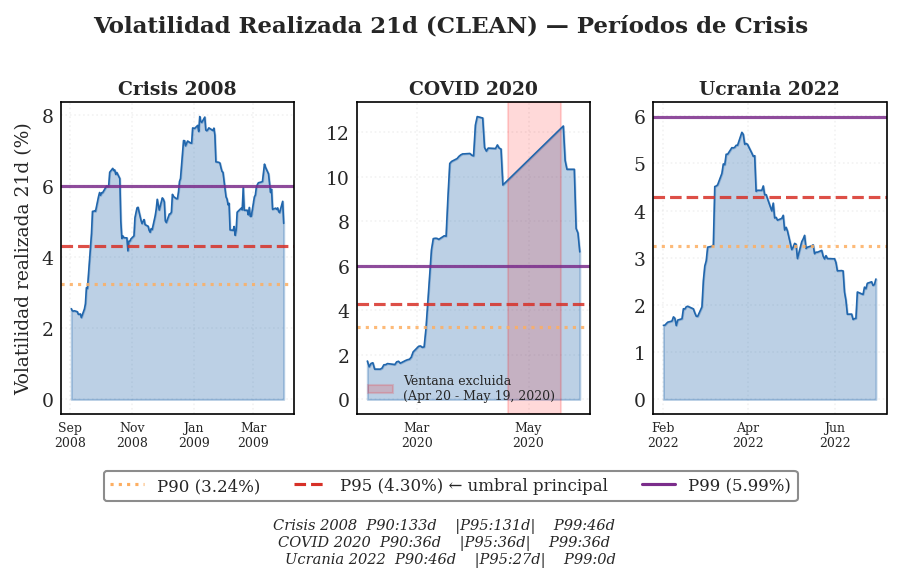

Figura guardada: fig_14_analisis_crisis.png

Resumen de Crisis (CLEAN) -- 3 periodos representativos:
      Crisis  Dias validos  P90  P95  P99  Vol21 Media
 Crisis 2008           146  133  131   46       5.5137
  COVID 2020            60   36   36   36       6.7387
Ucrania 2022           104   46   27    0       3.2706


In [ ]:
print("FIGURA ANÁLISIS DE CRISIS (CLEAN) -- 3 períodos representativos")

#  Ventana contaminada: fechas globales para verificar solapamiento
_bad_exists = df['bad_vol21'].any()
_bad_start  = df[df['bad_vol21']].index.min() if _bad_exists else None
_bad_end    = df[df['bad_vol21']].index.max() if _bad_exists else None

# 3 crisis más representativas para la tesis:
# - Crisis 2008: referencia histórica (train set)
# - COVID 2020: shock extremo en val -- justifica calibración de umbrales
# - Ucrania 2022: tensión geopolítica en test set (despliegue real)
# Shale 2014-16 eliminado: P99=0 días, menor relevancia para umbral P95
crisis_periods = {
    'Crisis 2008':   ('2008-09-01', '2009-03-31'),
    'COVID 2020':    ('2020-02-01', '2020-05-31'),
    'Ucrania 2022':  ('2022-02-01', '2022-06-30'),
}

fig, axes = plt.subplots(1, 3, figsize=fig_size('full', aspect=0.50))

crisis_stats = []

for ax, (name, (start, end)) in zip(axes.flatten(), crisis_periods.items()):

    mask = (df.index >= start) & (df.index <= end)
    crisis_data = df.loc[mask].copy()

    # bad_vol21 cubre 22 días post-2020-04-20: vol21_clean es NaN en esos días.
    # Excluirlos evita gaps artificiales en el gráfico de COVID.
    crisis_data = crisis_data[~crisis_data['bad_vol21']]

    vol_series = crisis_data['vol21_clean']

    #  Serie principal
    ax.fill_between(vol_series.index, 0, vol_series * 100,
                    alpha=0.3, color=COLOR_NORMAL)
    ax.plot(vol_series.index, vol_series * 100,
            lw=0.8, color=COLOR_NORMAL)

    #  Ventana contaminada
    panel_start = pd.Timestamp(start)
    panel_end   = pd.Timestamp(end)
    crisis_has_bad = (
        _bad_exists and
        _bad_start <= panel_end and
        _bad_end   >= panel_start
    )
    if crisis_has_bad:
        ax.axvspan(_bad_start, _bad_end, alpha=0.15, color='red',
                   label=f'Ventana excluida\n'
                         f'({_bad_start.strftime("%b %d")} - '
                         f'{_bad_end.strftime("%b %d, %Y")})')
        ax.legend(fontsize=6, loc='lower left',framealpha=0.9,frameon=False)

    #  Umbrales P90 / P95 / P99
    for p, style in [(90, ':'), (95, '--'), (99, '-')]:
        ax.axhline(thresholds_clean[p] * 100,
                   linestyle=style, linewidth=1.5,
                   color=COLORS_P[p], alpha=0.85,
                   label=LABELS_P[p])

    # Conteo de eventos por umbral
    n_p90 = int(crisis_data['is_extreme_p90_clean'].sum())
    n_p95 = int(crisis_data['is_extreme_p95_clean'].sum())
    n_p99 = int(crisis_data['is_extreme_p99_clean'].sum())

    ax.set_title(f'{name}', fontweight='bold', fontsize=9, pad=4)

    # Etiqueta Y solo en primer panel
    if ax == axes[0]:
        ax.set_ylabel('Volatilidad realizada 21d (%)', fontsize=9)

    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
    plt.setp(ax.xaxis.get_majorticklabels(), fontsize=6, ha='center')

    crisis_stats.append({
        'Crisis':       name,
        'Dias validos': len(crisis_data),
        'P90':          n_p90,
        'P95':          n_p95,
        'P99':          n_p99,
        'Vol21 Media':  round(vol_series.mean() * 100, 4),
    })

#  Leyenda de umbrales
handles = [
    plt.Line2D([0], [0], color=COLORS_P[p], linestyle=s, linewidth=1.5,
               label=LABELS_P[p])
    for p, s in [(90, ':'), (95, '--'), (99, '-')]
]
fig.legend(handles=handles, loc='upper center', ncol=3,
           fontsize=8, framealpha=0.9,
           bbox_to_anchor=(0.5, 0.02))

cs = crisis_stats
fig.text(0.5, -0.2,
    f'Crisis 2008  P90:{cs[0]["P90"]}d    |P95:{cs[0]["P95"]}d|    P99:{cs[0]["P99"]}d   '
    f'\nCOVID 2020  P90:{cs[1]["P90"]}d    |P95:{cs[1]["P95"]}d|    P99:{cs[1]["P99"]}d   '
    f'\nUcrania 2022  P90:{cs[2]["P90"]}d    |P95:{cs[2]["P95"]}d|    P99:{cs[2]["P99"]}d',
    ha='center', fontsize=7, style='italic')

fig.suptitle(
    'Volatilidad Realizada 21d (CLEAN) — Períodos de Crisis',
    fontsize=11, fontweight='bold', y=0.998
)

plt.tight_layout(w_pad=1.5)
save_fig(fig, 'fig_14_analisis_crisis', output_path=FIG_PATH)
plt.show()
plt.close()

print("Figura guardada: fig_14_analisis_crisis.png")

print("\nResumen de Crisis (CLEAN) -- 3 periodos representativos:")
crisis_df = pd.DataFrame(crisis_stats)
print(crisis_df.to_string(index=False))

## 4.3 Matriz de Correlaciones

  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB01_EDA/Figuras Notebook EDA/fig_15a_matrices_correlacion.png  [6.1"×8.8" @ 300dpi]


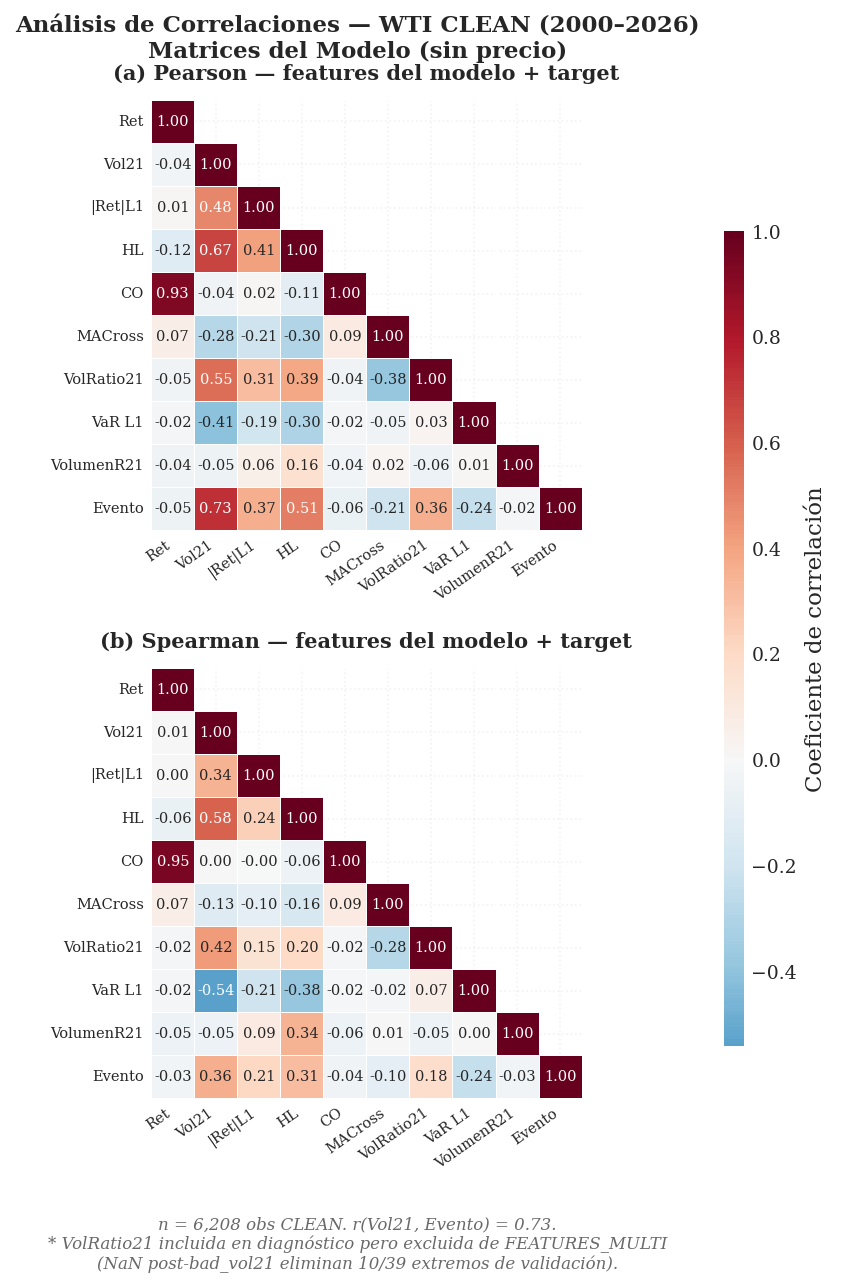

Figura guardada: fig_15a_matrices_correlacion.png


In [ ]:
# CORRELACIONES -- PARTE A: Matrices de Correlación (features del modelo + target)

# Variables: FEATURES_MULTI (8) + precio (contexto) + target
corr_vars = [
    'wti', 'returns', 'vol21_clean', 'ret_abs_lag1',
    'hl_spread', 'co_spread', 'ma_cross', 'volatilidad_ratio21',
    'var_rolling_252_lag1', 'volumen_ratio_21', 'is_extreme_clean'
]
corr_labels = [
    'Precio', 'Ret', 'Vol21', '|Ret|L1',
    'HL', 'CO', 'MACross', 'VolRatio21',
    'VaR L1', 'VolumenR21', 'Evento'
]

# Solo features del modelo + target (sin precio)
corr_vars_alt = [
    'returns', 'vol21_clean', 'ret_abs_lag1',
    'hl_spread', 'co_spread', 'ma_cross', 'volatilidad_ratio21',
    'var_rolling_252_lag1', 'volumen_ratio_21', 'is_extreme_clean'
]
corr_labels_alt = [
    'Ret', 'Vol21', '|Ret|L1',
    'HL', 'CO', 'MACross', 'VolRatio21',
    'VaR L1', 'VolumenR21', 'Evento'
]

# Dataset CLEAN
df_corr = df[(~df['bad_vol21']) & (~df['bad_return'])][corr_vars].dropna()

# Matrices
corr_matrix_alt   = df_corr[corr_vars_alt].corr(method='pearson')
corr_spearman_alt = df_corr[corr_vars_alt].corr(method='spearman')

corr_vol_target = corr_matrix_alt.loc['vol21_clean', 'is_extreme_clean']

# Escala común para ambas matrices
vmin = min(corr_matrix_alt.min().min(), corr_spearman_alt.min().min(), -0.40)
vmax = 1.00

fig, axes = plt.subplots(2, 1, figsize=fig_size('page'))
cbar_ax = fig.add_axes([0.90, 0.18, 0.022, 0.62])

heatmap_kws = dict(
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    vmin=vmin,
    vmax=vmax,
    square=True,
    linewidths=0.25,
    linecolor='white',
    annot_kws={'size': 7}
)

# (a) Pearson
mask_p = np.triu(np.ones_like(corr_matrix_alt, dtype=bool), k=1)
sns.heatmap(
    corr_matrix_alt,
    mask=mask_p,
    xticklabels=corr_labels_alt,
    yticklabels=corr_labels_alt,
    ax=axes[0],
    cbar=False,
    **heatmap_kws
)
axes[0].set_title(
    '(a) Pearson — features del modelo + target',
    fontweight='bold', fontsize=10, pad=10
)

# (b) Spearman
mask_s = np.triu(np.ones_like(corr_spearman_alt, dtype=bool), k=1)
sns.heatmap(
    corr_spearman_alt,
    mask=mask_s,
    xticklabels=corr_labels_alt,
    yticklabels=corr_labels_alt,
    ax=axes[1],
    cbar=True,
    cbar_ax=cbar_ax,
    cbar_kws={'label': 'Coeficiente de correlación'},
    **heatmap_kws
)
axes[1].set_title(
    '(b) Spearman — features del modelo + target',
    fontweight='bold', fontsize=10, pad=10
)

# Formato de ejes
for ax in axes:
    ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha='right', fontsize=7)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=8)
    ax.tick_params(axis='both', length=0,labelsize=7)

fig.suptitle(
    'Análisis de Correlaciones — WTI CLEAN (2000–2026)\nMatrices del Modelo (sin precio)',
    fontsize=11,
    fontweight='bold',
    y=0.965
)

fig.text(
    0.5, 0.01,
    f'n = {len(df_corr):,} obs CLEAN. r(Vol21, Evento) = {corr_vol_target:.2f}.\n'
    f'* VolRatio21 incluida en diagnóstico pero excluida de FEATURES_MULTI\n'
    f'(NaN post-bad_vol21 eliminan 10/39 extremos de validación).',
    ha='center',
    fontsize=8,
    style='italic',
    color='dimgray'
)

fig.subplots_adjust(left=0.14, right=0.88, top=0.90, bottom=0.14, hspace=0.32 )

save_fig(fig, 'fig_15a_matrices_correlacion', output_path=FIG_PATH)
plt.show()
plt.close()
print("Figura guardada: fig_15a_matrices_correlacion.png")


### Matrices de Correlación Pearson y Spearman — FEATURES_MULTI vs Target

**Qué muestra**
Dos matrices de correlación en train_clean: (a) Pearson y (b) Spearman
entre las 8 features de FEATURES_MULTI y el target is_extreme_clean,
cuantificando relación lineal y monotónica de cada predictor.

**Cómo se construye**
pandas .corr() sobre df_train_clean. Heatmap con máscara triangular
superior, paleta RdBu_r centrada en 0. Solo train para evitar leakage
en el análisis exploratorio.

**Por qué tiene esta forma**
vol21_clean tiene la mayor correlación con el target (r≈0.73). co_spread
tiene correlaciones bajas o negativas, anticipando su importancia negativa
en los modelos multivariados de NB02. La correlación entre vol21_clean y
var_rolling_252_lag1 es alta (~0.72) por medir persistencia en distintos
horizontes temporales.

**Por qué es importante para la tesis**
Documenta multicolinealidad moderada entre features y justifica la
selección de FEATURES_MULTI. Anticipa los hallazgos de permutation
importance de NB02: hl_spread como segundo predictor más importante,
co_spread con contribución negativa.

  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB01_EDA/Figuras Notebook EDA/fig_15b_analisis_scatter.png  [6.1"×6.4" @ 300dpi]


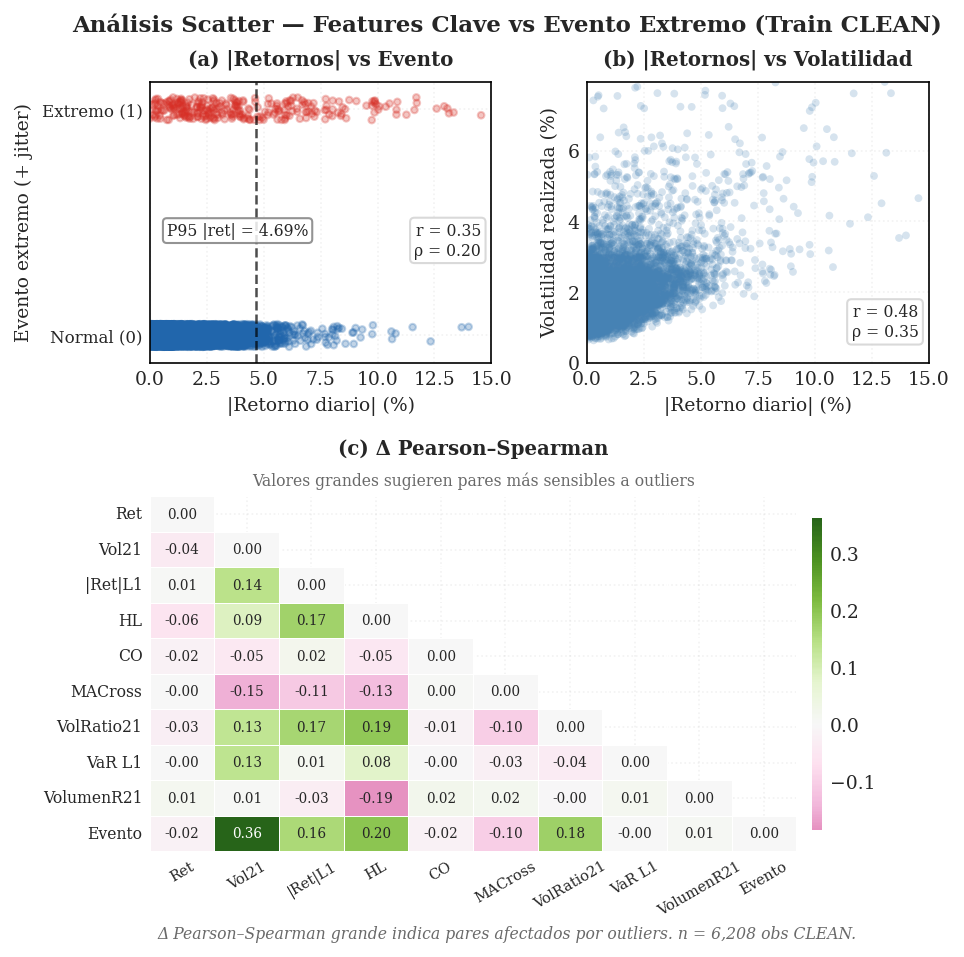

Figura guardada: fig_15b_analisis_scatter.png


In [ ]:
# CORRELACIONES -- PARTE B: Scatter + Î” Pearson-Spearman
# Variables: FEATURES_MULTI (8) + precio (contexto) + target
corr_vars = [
    'wti', 'returns', 'vol21_clean', 'ret_abs_lag1',
    'hl_spread', 'co_spread', 'ma_cross', 'volatilidad_ratio21',
    'var_rolling_252_lag1', 'volumen_ratio_21', 'is_extreme_clean'
]
corr_labels = [
    'Precio', 'Ret', 'Vol21', '|Ret|L1',
    'HL', 'CO', 'MACross', 'VolRatio21',
    'VaR L1', 'VolumenR21', 'Evento'
]

# Solo features del modelo + target (sin precio)
corr_vars_alt = ['returns', 'vol21_clean', 'ret_abs_lag1',
    'hl_spread', 'co_spread', 'ma_cross', 'volatilidad_ratio21',
    'var_rolling_252_lag1', 'volumen_ratio_21', 'is_extreme_clean'
]
corr_labels_alt = ['Ret', 'Vol21', '|Ret|L1',
    'HL', 'CO', 'MACross', 'VolRatio21',
    'VaR L1', 'VolumenR21', 'Evento'
]

# Dataset CLEAN
df_corr = df[(~df['bad_vol21']) & (~df['bad_return'])][corr_vars].dropna()

# Matrices
corr_matrix_alt   = df_corr[corr_vars_alt].corr(method='pearson')
corr_spearman_alt = df_corr[corr_vars_alt].corr(method='spearman')
diff_matrix       = corr_matrix_alt - corr_spearman_alt

# Métricas para anotación
corr_absret_event     = df_corr['returns'].abs().corr(df_corr['is_extreme_clean'], method='pearson')
spearman_absret_event = df_corr['returns'].abs().corr(df_corr['is_extreme_clean'], method='spearman')
corr_absret_vol       = df_corr['returns'].abs().corr(df_corr['vol21_clean'], method='pearson')
spearman_absret_vol   = df_corr['returns'].abs().corr(df_corr['vol21_clean'], method='spearman')

# Jitter para variable binaria
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)
jitter = np.random.uniform(-0.05, 0.05, len(df_corr))

# Escalas auxiliares
absret_pct = df_corr['returns'].abs() * 100
vol21_pct  = df_corr['vol21_clean'] * 100
p95_absret = absret_pct.quantile(0.95)

x_max = max(15, float(np.nanpercentile(absret_pct, 99.5)) * 1.02)
y_vol_max = float(np.nanpercentile(vol21_pct, 99.5)) * 1.05

# FIGURA 15b: layout 2x2 con heatmap abajo ocupando todo el ancho
fig = plt.figure(figsize=fig_size('full', aspect=1.05))
gs = gridspec.GridSpec( 2, 2, figure=fig,
    height_ratios=[0.95, 1.20],
    hspace=0.42, wspace=0.28)

ax_a = fig.add_subplot(gs[0, 0])
ax_b = fig.add_subplot(gs[0, 1])
ax_c = fig.add_subplot(gs[1, :])

# (a) |Retornos| vs Evento
colors_c = df_corr['is_extreme_clean'].map({0: COLOR_NORMAL, 1: COLOR_EXTREMO})

ax_a.scatter(
    absret_pct, df_corr['is_extreme_clean'] + jitter, alpha=0.28,
    s=10, c=colors_c, rasterized=True)
ax_a.axvline(
    p95_absret, color='black', ls='--',
    lw=1.2, alpha=0.70)

ax_a.set_title('(a) |Retornos| vs Evento', fontweight='bold', fontsize=9.5, pad=8)
ax_a.set_xlabel('|Retorno diario| (%)', fontsize=9)
ax_a.set_ylabel('Evento extremo (+ jitter)', fontsize=9)
ax_a.set_xlim(0, x_max)
ax_a.set_ylim(-0.12, 1.12)
ax_a.set_yticks([0, 1])
ax_a.set_yticklabels(['Normal (0)', 'Extremo (1)'], fontsize=8)

ax_a.text(0.05, 0.5,
    f'P95 |ret| = {p95_absret:.2f}%',
    transform=ax_a.transAxes,
    ha='left', va='top', fontsize=7.5,
    bbox=dict(boxstyle='round,pad=0.25', facecolor='white', alpha=0.85, edgecolor='gray')
)

ax_a.text(0.97, 0.50,
    f'r = {corr_absret_event:.2f}\nρ = {spearman_absret_event:.2f}',
    transform=ax_a.transAxes,
    ha='right', va='top', fontsize=7.5,
    bbox=dict(boxstyle='round,pad=0.28', facecolor='white', alpha=0.85, edgecolor='lightgray')
)

ax_a.grid(alpha=0.25, linestyle=':')

# (b) |Retornos| vs Volatilidad
ax_b.scatter(absret_pct, vol21_pct,
    alpha=0.22, s=14,
    c='steelblue', edgecolors='none',
    rasterized=True)

ax_b.set_title('(b) |Retornos| vs Volatilidad', fontweight='bold', fontsize=9.5, pad=8)
ax_b.set_xlabel('|Retorno diario| (%)', fontsize=9)
ax_b.set_ylabel('Volatilidad realizada (%)', fontsize=9)
ax_b.set_xlim(0, x_max)
ax_b.set_ylim(0, y_vol_max)

ax_b.text(0.97, 0.08,
    f'r = {corr_absret_vol:.2f}\nρ = {spearman_absret_vol:.2f}',
    transform=ax_b.transAxes,
    ha='right', va='bottom', fontsize=7.5,
    bbox=dict(boxstyle='round,pad=0.28', facecolor='white', alpha=0.85, edgecolor='lightgray'))

ax_b.grid(alpha=0.25, linestyle=':')

# (c) Δ Pearson–Spearman
mask = np.triu(np.ones_like(diff_matrix, dtype=bool), k=1)

sns.heatmap(
    diff_matrix, mask=mask, annot=True,
    fmt='.2f', cmap='PiYG', center=0, square=False,
    linewidths=0.25, linecolor='white',
    xticklabels=corr_labels_alt,
    yticklabels=corr_labels_alt, ax=ax_c,
    cbar_kws={'shrink': 0.88, 'pad': 0.02, 'aspect': 30}, annot_kws={'size': 6.5})

ax_c.set_title('(c) Δ Pearson–Spearman', fontweight='bold', fontsize=9.5, pad=20)
ax_c.text( 0.5, 1.02,
    'Valores grandes sugieren pares más sensibles a outliers',
    transform=ax_c.transAxes, ha='center', va='bottom',
    fontsize=7.5, color='dimgray')

ax_c.tick_params(axis='x', rotation=30, labelsize=7)
ax_c.tick_params(axis='y', rotation=0, labelsize=7.5)

fig.suptitle(
    'Análisis Scatter — Features Clave vs Evento Extremo (Train CLEAN)',
    fontsize=11, fontweight='bold', y=0.97)

fig.text(
    0.5, 0.01,
    f'Δ Pearson–Spearman grande indica pares afectados por outliers. n = {len(df_corr):,} obs CLEAN.',
    ha='center', fontsize=7.5, style='italic',color='dimgray')

fig.subplots_adjust(left=0.11, right=0.96, top=0.90, bottom=0.10,
    hspace=0.42, wspace=0.28 )

save_fig(fig, 'fig_15b_analisis_scatter', output_path=FIG_PATH)
plt.show()
plt.close()
print("Figura guardada: fig_15b_analisis_scatter.png")

## 4.4 Baselines

Establecer el rendimiento mínimo que cualquier modelo debe superar para
justificar su complejidad computacional. Se evalúa sobre VALIDACIÓN únicamente
(2019-2020), usando umbrales calibrados exclusivamente en TRAIN — sin data leakage.

**Propósito:** establecer el estándar mínimo (F1, AUC) que GARCH y LSTM deben
superar para justificar su complejidad computacional.  
**Protocolo:** umbrales calibrados SOLO en train; evaluación en val (2019-2020).  
**Referencia:** López de Prado (2018), Cap. 7 — naive benchmarks.

> **Nota:** estos baselines son referencias descriptivas internas del dataset.
> La evaluación predictiva formal con horizonte t+1 se realiza en NB02.

In [ ]:
val_mask_clean = (
    (df['split'] == 'validation') &
    (~df['bad_vol21']) &
    (df['is_extreme_clean'].notna())
)
df_val = df[val_mask_clean].copy()
y_true = df_val['is_extreme_clean'].astype(int)

# Umbrales calibrados en TRAIN (sin leakage)
p95_train = thresholds_clean[PERCENTILE_PRIMARY]

train_mask_clean = (df['split'] == 'train') & (~df['bad_return'])
p95_absret = df[train_mask_clean]['returns'].abs().quantile(0.95)
p75_absret = df[train_mask_clean]['returns'].abs().quantile(0.75)

# B5: threshold calibrado con shift(1) — ambos términos usan datos hasta t-1
# Hace a B5 comparable con modelos LSTM (que acceden solo hasta t-1)
df_train_clean_b5 = df[(df['split'] == 'train') & (~df['bad_vol21'])]
p95_vol_var_ratio = (
    df_train_clean_b5['vol21_clean'].shift(1) /
    df_train_clean_b5['var_rolling_252_lag1'].abs()
).dropna().quantile(0.95)

print("UMBRALES (calibrados en TRAIN — sin leakage):")
print(f"  P95 vol21:          {p95_train*100:.4f}%")
print(f"  P95 |returns|:      {p95_absret*100:.4f}%")
print(f"  P75 |returns|:      {p75_absret*100:.4f}%")
print(f"  P95 vol/VaR ratio:  {p95_vol_var_ratio:.4f}  (B5 con shift — comparable a LSTM)")
print(f"\n  Obs validación (CLEAN): {len(df_val):,}")
print(f"  Eventos extremos (y=1): {y_true.sum():,} ({y_true.mean()*100:.1f}%)")

corr_lag1  = df_val['vol21_clean'].corr(df_val['vol21_clean'].shift(1))
corr_lag21 = df_val['vol21_clean'].corr(df_val['vol21_clean'].shift(21))

print(f"""
VERIFICACIÓN DE SOLAPAMIENTO DE VENTANAS
  vol21(t) vs vol21(t-1):   r = {corr_lag1:.4f}
  → 20/21 días compartidos → correlación estructural, no capacidad predictiva.
    Se usa ret_abs_lag1 como sustituto sin solapamiento.

  vol21(t) vs vol21(t-21):  r = {corr_lag21:.4f}
  → Ventanas disjuntas — válido como predictor (lag-21 = corte mínimo).
""")

def evaluar_baseline(nombre, y_true, y_pred, y_score=None, split='validation'):
    f1        = f1_score(y_true, y_pred, zero_division=0)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall    = recall_score(y_true, y_pred, zero_division=0)
    # accuracy EXCLUIDA — desinformativa con ratio 1:11.4 val / 1:47 test
    try:
        auc = roc_auc_score(y_true, y_score) if y_score is not None else np.nan
    except ValueError:
        auc = np.nan
    cm = confusion_matrix(y_true, y_pred)
    return {
        'nombre': nombre, 'f1': f1, 'auc': auc, 'split': split,
        'precision': precision, 'recall': recall,
        'tp': cm[1,1], 'fp': cm[0,1], 'fn': cm[1,0], 'tn': cm[0,0]
    }


# B0: siempre clase 0 — piso absoluto (F1=0 por construcción)
y_pred_b0 = np.zeros(len(y_true), dtype=int)

# B1: |retorno| lag1 > P95 — momentum sin solapamiento de ventanas
y_score_b1 = df_val['ret_abs_lag1'].fillna(0)  # fillna(0): NaN solo en primera obs por lag -- score=0 clasifica Normal (sin impacto en metricas)
y_pred_b1  = (y_score_b1 > p95_absret).astype(int)

# B2: |retorno| lag1 > P75 — trade-off recall/precision
y_score_b2 = df_val['returns'].abs().shift(1)
y_pred_b2  = (y_score_b2.fillna(0) > p75_absret).astype(int)

# B3: vol21_lag21 > P95 — persistencia de medio plazo, ventanas disjuntas
y_score_b3 = df_val['vol21_clean'].shift(21)
y_pred_b3  = (y_score_b3.fillna(0) > p95_train).astype(int)

# B4: violación de VaR lag1 — clustering de colas (Engle & Manganelli, 2004)
y_score_b4 = (df_val['returns'].shift(1) < df_val['var_rolling_252'].shift(1)).astype(float)
y_pred_b4  = y_score_b4.fillna(0).astype(int)

# B5: vol21(t-1)/VaR(t-1) > P95 — régimen de riesgo relativo
# shift(1) aplicado a vol21_clean para igualar condiciones de información con LSTM
# var_rolling_252_lag1 ya tiene lag incorporado — ambos términos usan cierre t-1
# Fundamento: Christoffersen (1998)
y_score_b5 = (df_val['vol21_clean'].shift(1) /
              df_val['var_rolling_252_lag1'].abs()).fillna(0)
y_pred_b5  = (y_score_b5 > p95_vol_var_ratio).astype(int)

# Evaluación
resultados = [
    evaluar_baseline("B0 — Siempre Normal",        y_true, y_pred_b0),
    evaluar_baseline("B1 — |ret_lag1| > P95",      y_true, y_pred_b1, y_score_b1),
    evaluar_baseline("B2 — |ret_lag1| > P75",      y_true, y_pred_b2, y_score_b2.fillna(0)),
    evaluar_baseline("B3 — vol21_lag21 > P95",     y_true, y_pred_b3, y_score_b3.fillna(0)),
    evaluar_baseline("B4 — VaR violation lag1",    y_true, y_pred_b4, y_score_b4),
    evaluar_baseline("B5 — vol21_lag1/VaR > P95",  y_true, y_pred_b5, y_score_b5),
]

# Tabla sin accuracy
print(f"{'Baseline':<30} {'F1':>7} {'AUC':>8} {'Prec':>8} {'Recall':>8} {'TP':>5} {'FP':>5} {'FN':>5}")
print("─" * 82)
for r in resultados:
    auc_str = f"{r['auc']:.4f}" if not np.isnan(r['auc']) else "   N/A"
    print(f"  {r['nombre']:<28} {r['f1']:>7.4f} {auc_str:>8} "
          f"{r['precision']:>8.4f} {r['recall']:>8.4f} "
          f"{r['tp']:>5} {r['fp']:>5} {r['fn']:>5}")
print("─" * 82)
print("  Accuracy excluida — ratio 1:11.4 val hace la métrica trivialmente alta")
print("  B5 recalibrado con shift(1) — comparable con LSTM (ambos usan info hasta t-1)")

UMBRALES (calibrados en TRAIN — sin leakage):
  P95 vol21:          4.2996%
  P95 |returns|:      4.6536%
  P75 |returns|:      2.3215%
  P95 vol/VaR ratio:  0.9690  (B5 con shift — comparable a LSTM)

  Obs validación (CLEAN): 483
  Eventos extremos (y=1): 39 (8.1%)

VERIFICACIÓN DE SOLAPAMIENTO DE VENTANAS
  vol21(t) vs vol21(t-1):   r = 0.9873
  → 20/21 días compartidos → correlación estructural, no capacidad predictiva.
    Se usa ret_abs_lag1 como sustituto sin solapamiento.

  vol21(t) vs vol21(t-21):  r = 0.3819
  → Ventanas disjuntas — válido como predictor (lag-21 = corte mínimo).

Baseline                            F1      AUC     Prec   Recall    TP    FP    FN
──────────────────────────────────────────────────────────────────────────────────
  B0 — Siempre Normal           0.0000      N/A   0.0000   0.0000     0     0    39
  B1 — |ret_lag1| > P95         0.4872   0.8241   0.4872   0.4872    19    20    20
  B2 — |ret_lag1| > P75         0.3277   0.8313   0.2101   0.7436  

In [ ]:
#  Estándar mínimo: mejor baseline válido por F1 y AUC
BASELINES_INGENUOS    = ['B0', 'B1', 'B2', 'B3', 'B4']
BASELINES_CUANTITATIVOS = ['B5']

best_ingenuo = max(
    [r for r in resultados if any(t in r['nombre'] for t in BASELINES_INGENUOS)],
    key=lambda r: (r['f1'], r['auc'] if not np.isnan(r['auc']) else 0)
)
best_cuantitativo = max(
    [r for r in resultados if any(t in r['nombre'] for t in BASELINES_CUANTITATIVOS)],
    key=lambda r: (r['f1'], r['auc'] if not np.isnan(r['auc']) else 0)
)

print(f"\nEstándar mínimo (baseline ingenuo) — {best_ingenuo['nombre']}:")
print(f"  TP={best_ingenuo['tp']:>3}  FP={best_ingenuo['fp']:>3}  ← {best_ingenuo['fp']} alertas innecesarias")
print(f"  FN={best_ingenuo['fn']:>3}  TN={best_ingenuo['tn']:>3}  ← {best_ingenuo['fn']} eventos NO detectados")
print(f"      → Detecta solo {best_ingenuo['tp']}/{best_ingenuo['tp']+best_ingenuo['fn']} eventos extremos posibles.")

print(f"\nReferencia cuantitativa — {best_cuantitativo['nombre']}:")
print(f"  TP={best_cuantitativo['tp']:>3}  FP={best_cuantitativo['fp']:>3}  ← {best_cuantitativo['fp']} alertas innecesarias")
print(f"  FN={best_cuantitativo['fn']:>3}  TN={best_cuantitativo['tn']:>3}  ← {best_cuantitativo['fn']} eventos NO detectados")
print(f"      → Detecta solo {best_cuantitativo['tp']}/{best_cuantitativo['tp']+best_cuantitativo['fn']} eventos extremos posibles.")
print(f"    El problema NO es trivialmente predecible con reglas simples.")


Estándar mínimo (baseline ingenuo) — B1 — |ret_lag1| > P95:
  TP= 19  FP= 20  ← 20 alertas innecesarias
  FN= 20  TN=424  ← 20 eventos NO detectados
      → Detecta solo 19/39 eventos extremos posibles.

Referencia cuantitativa — B5 — vol21_lag1/VaR > P95:
  TP= 33  FP= 17  ← 17 alertas innecesarias
  FN=  6  TN=427  ← 6 eventos NO detectados
      → Detecta solo 33/39 eventos extremos posibles.
    El problema NO es trivialmente predecible con reglas simples.


B5 (vol21(t-1)/VaR(t-1) ratio > P95) — Referencia cuantitativa
(Christoffersen, 1998)

> **Nota sobre el rol de B5:** B5 usa `vol21_clean(t-1)` como numerador
> y `var_rolling_252_lag1(t)` como denominador — ambos usan datos hasta
> el cierre de t-1, lo que garantiza consistencia temporal.
> Su valor metodológico es establecer el techo práctico alcanzable con
> una regla basada en la señal de riesgo relativo, no como predictor
> estricto de t+1.
>
> LSTM y GARCH en NB02 predicen `is_extreme(t+1)` usando features en `t`.
> **El estándar mínimo que deben superar es B1.**
> Superar a B5 en F1 implica que el modelo agrega valor predictivo más
> allá del régimen contemporáneo de riesgo.

B5 no es una regla naive: requiere `vol21_clean` (rolling 21d),
`var_rolling_252_lag1` (rolling 252d + shift incorporado), shift(1)
adicional en el numerador, y calibración del P95 del ratio en train.
Christoffersen (1998) clasifica esta construcción como
*risk-adjusted threshold*, no como baseline de una variable.

In [ ]:
#  Evaluación de B1 y B5 en TEST (out-of-sample real)
# Propósito: confirmar si el poder predictivo de los baselines más fuertes
# se mantiene en el régimen post-pandemia (2021-2026, 2.08% extremos).
# Los umbrales NO cambian — los mismos calibrados en train.

test_mask_clean = (
    (df['split'] == 'test') &
    (~df['bad_vol21']) &
    (df['is_extreme_clean'].notna())
)
df_test_b   = df[test_mask_clean].copy()
y_true_test = df_test_b['is_extreme_clean'].astype(int)

# B1 en test — mismo umbral p95_absret de train
y_score_b1_test = df_test_b['ret_abs_lag1'].fillna(0)
y_pred_b1_test  = (y_score_b1_test > p95_absret).astype(int)
b1_test = evaluar_baseline(
    "B1 — |ret_lag1| > P95",
    y_true_test, y_pred_b1_test,
    y_score=y_score_b1_test, split='test'
)

# B5 en test — shift(1) + mismo p95_vol_var_ratio de train (sin re-calibrar)
y_score_b5_test = (
    df_test_b['vol21_clean'].shift(1) /
    df_test_b['var_rolling_252_lag1'].abs()
).fillna(0)
y_pred_b5_test = (y_score_b5_test > p95_vol_var_ratio).astype(int)
b5_test = evaluar_baseline(
    "B5 — vol21/VaR ratio > P95",
    y_true_test, y_pred_b5_test,
    y_score=y_score_b5_test, split='test'
)

#  Tabla val vs test
_get = lambda tag, lst: next(r for r in lst if tag in r['nombre'])
b1_val = _get('B1', resultados)
b5_val = _get('B5', resultados)

print("\nCOMPARATIVA B1 y B5 — Validación vs Test")
print("─" * 72)
print(f"{'Baseline':<30} {'Split':<6} {'F1':>9} {'AUC':>8} {'Prec':>8} {'Recall':>8}")
print("─" * 72)
for r in [b1_val, b1_test, b5_val, b5_test]:
    auc_s = f"{r['auc']:.4f}" if not np.isnan(r['auc']) else "   N/A"
    print(f"{r['nombre']:<30} {r['split']:<6} {r['f1']:>9.4f} "
          f"{auc_s:>8} {r['precision']:>8.4f} {r['recall']:>8.4f}")
print("─" * 72)
print(f"  Val:  {len(df_val):,} obs, {y_true.sum()} extremos ({y_true.mean()*100:.2f}%) — período COVID")
print(f"  Test: {len(df_test_b):,} obs, {y_true_test.sum()} extremos "
      f"({y_true_test.mean()*100:.2f}%) — régimen post-pandemia")


COMPARATIVA B1 y B5 — Validación vs Test
────────────────────────────────────────────────────────────────────────
Baseline                       Split         F1      AUC     Prec   Recall
────────────────────────────────────────────────────────────────────────
B1 — |ret_lag1| > P95          validation    0.4872   0.8241   0.4872   0.4872
B1 — |ret_lag1| > P95          test      0.2069   0.7684   0.1500   0.3333
B5 — vol21_lag1/VaR > P95      validation    0.7416   0.9805   0.6600   0.8462
B5 — vol21/VaR ratio > P95     test      0.5474   0.9983   0.3824   0.9630
────────────────────────────────────────────────────────────────────────
  Val:  483 obs, 39 extremos (8.07%) — período COVID
  Test: 1,296 obs, 27 extremos (2.08%) — régimen post-pandemia


**Justificación formal del corte en lag-21 en B3:**

vol21(t) = std(returns[t-20 : t]). Por tanto:
- lag k < 21: vol21_lag_k comparte (21-k)/21 días con vol21(t) → solapamiento parcial
- lag k = 21: vol21_lag21 = std(returns[t-41 : t-21]) → ventanas disjuntas, solapamiento = 0

El corte en lag-21 no es arbitrario — es la consecuencia directa del tamaño de ventana.
Verificación empírica en celda anterior: r(vol21_t, vol21_t-1) = {corr_lag1:.4f} vs
r(vol21_t, vol21_t-21) = {corr_lag21:.4f} — confirma que lag-1 es artefacto estructural.

In [ ]:
# Conclusiones de baselines
_get = lambda tag: next(r for r in resultados if tag in r['nombre'])
b0 = _get('B0'); b1 = _get('B1'); b2 = _get('B2')
b3 = _get('B3'); b4 = _get('B4'); b5 = _get('B5')
assert 'corr_lag21' in globals(), "ERROR: Ejecutar celda de baselines antes de esta"

print(f"""
Conclusiones

ESTÁNDARES PARA NB02:

  Mínimo ingenuo  (regla 1 variable) — {best_ingenuo['nombre']}
    F1  > {best_ingenuo['f1']:.4f}  |  AUC > {best_ingenuo['auc']:.4f}
    → Cualquier modelo paramétrico debe superar esta barra para justificarse.

  Referencia cuantitativa (Christoffersen 1998) — {best_cuantitativo['nombre']}
    F1  val={best_cuantitativo['f1']:.4f}  |  AUC val={best_cuantitativo['auc']:.4f}
    → LSTM debe mejorar precisión sobre B5 para agregar valor operativo real.

INTERPRETACIÓN DE CADA BASELINE:
  B0 → F1=0 por construcción. Cualquier modelo real debe superarlo.
       Desbalanceo {y_true.mean()*100:.1f}% eventos — no reportar accuracy.

  B1 → F1={b1['f1']:.4f} | AUC={b1['auc']:.4f}
       Mejor predictor sin solapamiento de ventanas.
       {best_ingenuo['tp']} TP de {int(y_true.sum())} posibles ({best_ingenuo['tp']/int(y_true.sum())*100:.0f}%)
       → el problema NO es trivialmente predecible.

  B2 → Recall={b2['recall']:.3f} con Precision={b2['precision']:.3f}
       {b2['fp']} falsas alarmas. Trade-off inaceptable para gestión de riesgo real.

  B3 → AUC={b3['auc']:.4f} — persistencia de medio plazo débil.
       vol21(t-21) comparte {corr_lag21:.0%} de varianza con vol21(t).
       Justifica GARCH/LSTM: estructura temporal no trivialmente explotable.

  B4 → F1={b4['f1']:.4f} | AUC={b4['auc']:.4f} — violación de VaR lag1.
       Señal de cola débil: una violación ayer no predice bien el día de hoy.
       Fundamento: Engle & Manganelli (2004) — CAViaR.

  B5 → F1={b5['f1']:.4f} | AUC={b5['auc']:.4f} — ratio vol21(t-1)/VaR(t-1)  ← REFERENCIA CUANTITATIVA
       Ambos términos usan datos hasta cierre de t-1 → temporalmente consistente.
       Combina señal de nivel (vol21) con escala de riesgo histórico (VaR_252).
       No es una regla naive — requiere dos ventanas rolling + calibración en train.
       Fundamento: Christoffersen (1998) — excedencia ajustada por riesgo.
       Ver comparativa val vs test en celda siguiente.

NOTA METODOLÓGICA:
  B1 original (vol21_lag1 > P95) descartado:
  r(vol21[t], vol21[t-1]) = {corr_lag1:.4f} → solapamiento 95% de ventana.
  F1 alto por construcción aritmética, no por capacidad predictiva.
""")


Conclusiones

ESTÁNDARES PARA NB02:

  Mínimo ingenuo  (regla 1 variable) — B1 — |ret_lag1| > P95
    F1  > 0.4872  |  AUC > 0.8241
    → Cualquier modelo paramétrico debe superar esta barra para justificarse.

  Referencia cuantitativa (Christoffersen 1998) — B5 — vol21_lag1/VaR > P95
    F1  val=0.7416  |  AUC val=0.9805
    → LSTM debe mejorar precisión sobre B5 para agregar valor operativo real.

INTERPRETACIÓN DE CADA BASELINE:
  B0 → F1=0 por construcción. Cualquier modelo real debe superarlo.
       Desbalanceo 8.1% eventos — no reportar accuracy.

  B1 → F1=0.4872 | AUC=0.8241
       Mejor predictor sin solapamiento de ventanas.
       19 TP de 39 posibles (49%)
       → el problema NO es trivialmente predecible.

  B2 → Recall=0.744 con Precision=0.210
       109 falsas alarmas. Trade-off inaceptable para gestión de riesgo real.

  B3 → AUC=0.6616 — persistencia de medio plazo débil.
       vol21(t-21) comparte 38% de varianza con vol21(t).
       Justifica GARCH/LSTM: estruc

  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB01_EDA/Figuras Notebook EDA/fig_16_baselines_comparacion.png  [6.1"×3.8" @ 300dpi]


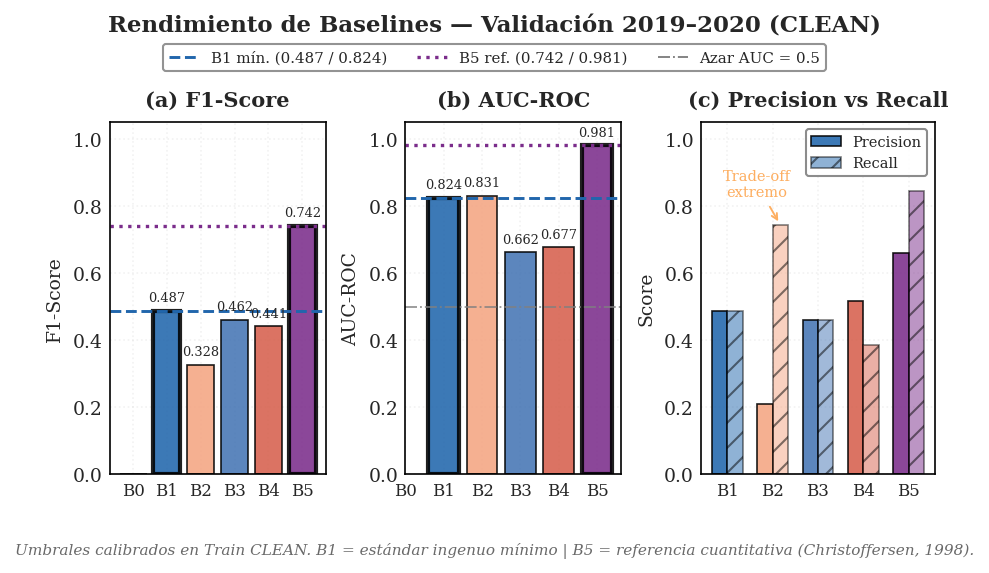

Figura guardada: fig_16_baselines_comparacion.png


In [ ]:
nombres = [r['nombre'] for r in resultados]
f1_vals = [r['f1'] for r in resultados]
auc_vals = [r['auc'] for r in resultados]

idx_ingenuo = next(i for i, r in enumerate(resultados) if r['nombre'] == best_ingenuo['nombre'])
idx_cuantitativo = next(i for i, r in enumerate(resultados) if r['nombre'] == best_cuantitativo['nombre'])

# Códigos cortos para el eje X: B0, B1, ...
codes = [n.split('—')[0].strip() if '—' in n else n for n in nombres]
codes_c = codes[1:]  # panel (c) excluye B0

bar_colors = COLORES_B[:len(resultados)]
light_colors = COLORES_B[1:len(resultados) + 1]

x_all = np.arange(len(resultados))

fig, axes = plt.subplots(1, 3,
    figsize=fig_size('full', aspect=0.62),
    gridspec_kw={'wspace': 0.36, 'width_ratios': [1.0, 1.0, 1.08]})

# ── Paneles (a) y (b) ───────────────────────────────────────────────────────
for ax, vals, titulo, etiqueta in [
    (axes[0], f1_vals,  '(a) F1-Score', 'F1-Score'),
    (axes[1], auc_vals, '(b) AUC-ROC',  'AUC-ROC'),
]:
    bars = ax.bar(
        x_all, vals,
        color=bar_colors,alpha=0.88,
        edgecolor='black', lw=0.8)

    ax.set_title(titulo, fontweight='bold', fontsize=10, pad=8)
    ax.set_ylabel(etiqueta, fontsize=9)
    ax.set_xticks(x_all)
    ax.set_xticklabels(codes, fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.grid(axis='y', alpha=0.25)

    umbral_ingenuo = best_ingenuo['f1'] if etiqueta == 'F1-Score' else best_ingenuo['auc']
    umbral_cuant = best_cuantitativo['f1'] if etiqueta == 'F1-Score' else best_cuantitativo['auc']

    ax.axhline(umbral_ingenuo, color=COLORES_B[1], ls='--', lw=1.4)
    ax.axhline(umbral_cuant, color=COLORES_B[5], ls=':', lw=1.6)

    if etiqueta == 'AUC-ROC':
        ax.axhline(0.5, color='gray', ls='-.', lw=0.9, alpha=0.8)

    for bar, val in zip(bars, vals):
        if pd.notna(val) and val > 0.005:
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                min(val + 0.02, 1.02), f'{val:.3f}', ha='center',
                va='bottom', fontsize=6.2
            )

    for idx in [idx_ingenuo, idx_cuantitativo]:
        bars[idx].set_linewidth(2.0)
        bars[idx].set_edgecolor('black')

# ── Panel (c): Precision vs Recall ──────────────────────────────────────────
ax3 = axes[2]
res_valid = resultados[1:]  # sin B0
x = np.arange(len(res_valid))
w = 0.34

prec_vals = [r['precision'] for r in res_valid]
rec_vals = [r['recall'] for r in res_valid]

ax3.bar( x - w/2, prec_vals, w,
    label='Precision', color=light_colors, alpha=0.88,
    edgecolor='black', lw=0.8
)
ax3.bar( x + w/2, rec_vals, w, label='Recall', color=light_colors,
    alpha=0.50, edgecolor='black',
    lw=0.8, hatch='//'
)

ax3.set_title('(c) Precision vs Recall', fontweight='bold', fontsize=10, pad=8)
ax3.set_ylabel('Score', fontsize=9)
ax3.set_xticks(x)
ax3.set_xticklabels(codes_c, fontsize=8)
ax3.set_ylim(0, 1.05)
ax3.grid(axis='y', alpha=0.25)
ax3.legend(loc='upper right', fontsize=7, framealpha=0.90, frameon=True)

# Anotación B2: trade-off extremo
b2_idx_c = next(i for i, r in enumerate(res_valid) if 'B2' in r['nombre'])
ax3.annotate(
    'Trade-off\nextremo',
    xy=(b2_idx_c + w/2, rec_vals[b2_idx_c]),
    xytext=(b2_idx_c - 0.35, 0.83),
    fontsize=7, ha='center', color=COLORS_P[90],
    arrowprops=dict(arrowstyle='->', color=COLORS_P[90], lw=0.9)
)

# Anotación B5: recall casi perfecto
b5_idx_c = next(i for i, r in enumerate(res_valid) if 'B5' in r['nombre'])
if rec_vals[b5_idx_c] >= 0.99:
    ax3.annotate(
        'Recall\n≈ 1.0',
        xy=(b5_idx_c + w/2, rec_vals[b5_idx_c]),
        xytext=(b5_idx_c - 0.10, 0.94),
        fontsize=7, ha='center', color=COLORES_B[5],
        arrowprops=dict(arrowstyle='->', color=COLORES_B[5], lw=0.9)
    )

# ── Leyenda global de referencias ───────────────────────────────────────────
ref_handles = [
    Line2D([0], [0], color=COLORES_B[1], lw=1.4, ls='--',
           label=f'B1 mín. ({best_ingenuo["f1"]:.3f} / {best_ingenuo["auc"]:.3f})'),
    Line2D([0], [0], color=COLORES_B[5], lw=1.6, ls=':',
           label=f'B5 ref. ({best_cuantitativo["f1"]:.3f} / {best_cuantitativo["auc"]:.3f})'),
    Line2D([0], [0], color='gray', lw=0.9, ls='-.',
           label='Azar AUC = 0.5'),
]

fig.legend(handles=ref_handles, loc='upper center',
    bbox_to_anchor=(0.5, 0.97),
    ncol=3, fontsize=7.2, frameon=True
)

fig.text(0.5, 0.06,
    (f'Umbrales calibrados en Train CLEAN. '
     f'B1 = estándar ingenuo mínimo | '
     f'B5 = referencia cuantitativa (Christoffersen, 1998).'),
    ha='center', fontsize=7.3, style='italic', color='dimgray'
)

fig.suptitle(
    'Rendimiento de Baselines — Validación 2019–2020 (CLEAN)',
    fontsize=11, fontweight='bold', y=1.01)

fig.subplots_adjust(
    top=0.82, bottom=0.20,left=0.08, right=0.98,
    wspace=0.36 )

save_fig(fig, 'fig_16_baselines_comparacion', output_path=FIG_PATH)
plt.show()
plt.close()
print("Figura guardada: fig_16_baselines_comparacion.png")

### Rendimiento de Baselines Ingenuos — Validación 2019–2020 (CLEAN)

**Qué muestra**
Tres paneles: (a) F1-Score de los 6 baselines (B0–B5), (b) AUC-ROC,
(c) curva Precision-Recall. B1 (|ret_lag1|>P95) se destaca como el
estándar mínimo que cualquier modelo del benchmark debe superar.

**Cómo se construye**
Evaluación de 6 reglas simples usando solo información disponible en t
para predecir is_extreme(t+1). Umbrales calibrados en train_clean.
Accuracy excluida (ratio 1:11.4 en val). Exportado al config como
baseline_ingenuo (B1) y baseline_cuantitativo (B5).

**Por qué tiene esta forma**
B5 (vol21/VaR ratio, Christoffersen 1998) alcanza F1=0.74 en validación
gracias al régimen COVID. B1 alcanza F1=0.49 con el retorno del día
anterior — referencia mínima justa y reproducible.

**Por qué es importante para la tesis**
Establece los estándares del benchmark NB02: todo modelo debe superar
B1 (F1>0.487 en test) para aportar valor sobre reglas simples, y superar
B5 (F1>0.547 en test) para superar la referencia cuantitativa. NB02
lee estos valores del config para garantizar consistencia.

---
# PARTE V: EXPORTACIÓN Y DOCUMENTACIÓN
---

## 5.1 Guardar Datasets

In [ ]:
# EXPORTAR DATASETS (MODEL_BASE vs CLEAN vs ALL)

if 'calendar_pos' not in df.columns:
    df = df.copy()
    df['calendar_pos'] = np.arange(len(df), dtype=int)
else:
    df = df.sort_index().copy()
    df['calendar_pos'] = df['calendar_pos'].astype(int)

columns_core = [
    'wti_raw', 'wti', 'returns',
    'vol21', 'vol21_clean', 'volatilidad_ratio21',
    'ma_short', 'ma_long', 'ma_cross',
    'ret_abs_lag1', 'ret_abs_lag5',
    'hl_spread', 'co_spread',
    'high', 'low', 'open',
    'volumen', 'volumen_ratio_21',
    'var_rolling_252',
    'var_rolling_252_lag1',
    'p95_vol21_rolling_252'
]
# ma_short y ma_long: exportados para auditoria y trazabilidad.
# NO usar en modelado; usar ma_cross (estacionaria, derivada de ambas).
columns_flags = [
    'bad_return', 'bad_vol21',
    'outlier_zscore_clean', 'returns_zscore_clean'
]

columns_labels = [
    'is_extreme_clean',
    'is_extreme_p90_clean', 'is_extreme_p95_clean', 'is_extreme_p99_clean',
    # is_extreme_dynamic: exportado para EDA/trazabilidad UNICAMENTE.
    # NO usar como feature en NB02/NB03.
    'is_extreme_dynamic'
]

model_base_cols = columns_core + columns_labels + columns_flags + ['split', 'calendar_pos']

# MODEL_BASE: calendario canonico downstream. No elimina filas bad_vol21.
df_model_base = df[model_base_cols].copy()
df_model_base.to_csv('wti_volatilidad_MODEL_BASE.csv', index=True)

# CLEAN: mantener para EDA y trazabilidad del recorte historico.
df_clean = df_model_base.loc[~df_model_base['bad_vol21']].copy()
df_clean.to_csv('wti_volatilidad_CLEAN.csv', index=True)

# ALL: para EDA descriptivo.
df_all = df[columns_core + columns_flags + ['split', 'calendar_pos']].copy()

train_all_vol = df_all[df_all['split'] == 'train']['vol21'].dropna()
thresholds_all = {p: train_all_vol.quantile(p/100) for p in PERCENTILES}

for p in PERCENTILES:
    df_all[f'is_extreme_p{p}_all'] = (df_all['vol21'] > thresholds_all[p]).astype(int)
df_all['is_extreme_all'] = df_all[f'is_extreme_p{PERCENTILE_PRIMARY}_all']
df_all.to_csv('wti_volatilidad_ALL.csv', index=True)

print(f"\n1) wti_volatilidad_MODEL_BASE.csv")
print("   Proposito: base canonica downstream para NB02")
print(f"   Observaciones: {len(df_model_base):,}")
print(f"   bad_vol21 preservados: {int(df_model_base['bad_vol21'].sum())}")
print(f"   calendar_pos consecutivo: {df_model_base['calendar_pos'].is_monotonic_increasing}")

print(f"\n2) wti_volatilidad_CLEAN.csv")
print("   Proposito: EDA, tablas descriptivas y modelado legado")
print(f"   Observaciones: {len(df_clean):,}")
print(f"   Eventos extremos P{PERCENTILE_PRIMARY} (CLEAN): {df_clean['is_extreme_clean'].sum():.0f}")
print(f"   Obs excluidas por bad_vol21: {int(df['bad_vol21'].sum())}")

print(f"\n3) wti_volatilidad_ALL.csv")
print("   Proposito: analisis descriptivo / EDA")
print(f"   Observaciones: {len(df_all):,}")
print(f"   Eventos extremos P{PERCENTILE_PRIMARY} (ALL): {df_all['is_extreme_all'].sum():.0f}")


1) wti_volatilidad_MODEL_BASE.csv
   Proposito: base canonica downstream para NB02
   Observaciones: 6,385
   bad_vol21 preservados: 22
   calendar_pos consecutivo: True

2) wti_volatilidad_CLEAN.csv
   Proposito: EDA, tablas descriptivas y modelado legado
   Observaciones: 6,363
   Eventos extremos P95 (CLEAN): 296
   Obs excluidas por bad_vol21: 22

3) wti_volatilidad_ALL.csv
   Proposito: analisis descriptivo / EDA
   Observaciones: 6,385
   Eventos extremos P95 (ALL): 318


## 5.2 Configuración

In [ ]:
# EXPORTAR CONFIGURACIÓN (preservando downstream ya existente)
from copy import deepcopy

CONFIG_RUNTIME_PATH = f"{BASE_PATH}/config_estudio_FINAL.json"
CONFIG_REPO_MIRROR = "config/config_estudio_FINAL.json"

NB01_RESET_DOWNSTREAM = False
NB01_DOWNSTREAM_KEYS = [
    "nb02_results",
    "nb02_metadata",
    "nb02_experiments",
    "nb03",
    "nb03b",
]

def safe_float(x):
    return float(x) if x is not None else None

def deep_merge_dict(base: dict, update: dict) -> dict:
    """
    Mezcla recursiva:
    - dict + dict -> merge recursivo
    - cualquier otro tipo -> update reemplaza
    """
    result = deepcopy(base)
    for k, v in update.items():
        if isinstance(v, dict) and isinstance(result.get(k), dict):
            result[k] = deep_merge_dict(result[k], v)
        else:
            result[k] = deepcopy(v)
    return result

# 1) Cargar config existente si ya existe
config_existing = {}
if os.path.exists(CONFIG_RUNTIME_PATH):
    with open(CONFIG_RUNTIME_PATH, "r", encoding="utf-8") as f:
        try:
            config_existing = json.load(f)
            print(f"Config existente cargado desde: {CONFIG_RUNTIME_PATH}")
        except json.JSONDecodeError:
            print("Aviso: el config existente no pudo parsearse. Se iniciará uno nuevo.")
            config_existing = {}

# Variables auxiliares para desbalanceo
_val_mask   = (df['split'] == 'validation')
_valid_mask = _val_mask & (~df['bad_vol21']) & (df['is_extreme_clean'].notna())
_n_valid    = int(_valid_mask.sum())
_n_extreme  = int(df.loc[_valid_mask, 'is_extreme_clean'].sum())

# 2) Construir SOLO la capa NB01
config_nb01 = {
    'metadata': {
        'fecha_ejecucion': datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
        'random_seed': RANDOM_SEED,
        'notebook': '1._WTI_Preparacion_Datos.ipynb',
    },
    'fechas': {
        'start_date': START_DATE,
        'end_date': END_DATE,
        'train_end': TRAIN_END,
        'val_start': VAL_START,
        'val_end': VAL_END,
        'test_start': TEST_START
    },
    'parametros': {
        'percentiles': PERCENTILES,
        'percentile_primary': PERCENTILE_PRIMARY,
        'volatility_window': VOLATILITY_WINDOW,
        'rolling_var_window': ROLLING_VAR_WINDOW,
        'clip_floor': CLIP_FLOOR
    },
    'umbrales_clean': {f'p{k}': safe_float(v) for k, v in thresholds_clean.items()},
    'umbrales_all': {f'p{k}': safe_float(v) for k, v in thresholds_all.items()}
                    if 'thresholds_all' in globals() else None,
    'var_all': {
        'global_95': safe_float(globals().get('var_global_95_all')),
        'train_95':  safe_float(globals().get('var_train_all')),
        'val_95':    safe_float(globals().get('var_val_all')),
        'test_95':   safe_float(globals().get('var_test_all'))
    },
    'var_clean': {
        'train_95': safe_float(globals().get('var_train_clean')),
        'val_95':   safe_float(globals().get('var_val_clean')),
        'test_95':  safe_float(globals().get('var_test_clean'))
    },
    'contaminacion': {
        'dias_bad_return': int(df['bad_return'].sum()),
        'dias_bad_vol21': int(df['bad_vol21'].sum()),
        'fecha_inicio': df[df['bad_vol21']].index.min().strftime('%Y-%m-%d')
                        if df['bad_vol21'].any() else None,
        'fecha_fin': df[df['bad_vol21']].index.max().strftime('%Y-%m-%d')
                     if df['bad_vol21'].any() else None
    },
    'estadisticas': {
        'n_total': int(len(df)),
        'n_train': int((df['split'] == 'train').sum()),
        'n_validation': int((df['split'] == 'validation').sum()),
        'n_test': int((df['split'] == 'test').sum()),
        'eventos_p95_clean': int(df['is_extreme_clean'].fillna(0).sum())
    },
    'export': {
        'columns_core': columns_core,
        'columns_labels': columns_labels,
        'columns_flags': columns_flags
    },
    'paths': {
        'dataset_all': 'data/raw/wti_volatilidad_ALL.csv',
        'dataset_clean': 'data/processed/wti_volatilidad_CLEAN.csv',
        'dataset_model_base': 'data/processed/wti_volatilidad_MODEL_BASE.csv',
    },
    'nb02': {
        'umbral_clasificacion': safe_float(thresholds_clean[PERCENTILE_PRIMARY]),
        'ventana_vol': VOLATILITY_WINDOW,
        'random_seed': RANDOM_SEED,
        'splits': {
            'train_end': TRAIN_END,
            'val_start': VAL_START,
            'val_end': VAL_END,
            'test_start': TEST_START
        },
        'baseline_ingenuo': {
            'evaluado_en': 'validation',
            'mejor_baseline': best_ingenuo['nombre'],
            'f1_minimo': round(best_ingenuo['f1'], 4),
            'auc_minimo': round(best_ingenuo['auc'], 4),
        },
        'baseline_cuantitativo': {
            'evaluado_en': 'validation',
            'nombre': best_cuantitativo['nombre'],
            'f1_val': round(best_cuantitativo['f1'], 4),
            'auc_val': round(best_cuantitativo['auc'], 4),
            'f1_test': round(b5_test['f1'], 4),
            'auc_test': round(b5_test['auc'], 4),
            'nota': 'Christoffersen (1998) — excedencia ajustada por riesgo'
        },
        'desbalanceo_validacion': {
            'n_total': int(_val_mask.sum()),
            'n_excluidos': int((_val_mask & df['bad_vol21']).sum()),
            'n_validos': _n_valid,
            'n_extremos': _n_extreme,
            'tasa_pct': round(_n_extreme / _n_valid * 100, 2),
            'ratio': round((_n_valid - _n_extreme) / _n_extreme, 1)
        },
        'features': {
            'FEATURES_UNI': ['vol21_clean'],
            'FEATURES_MULTI': [
                'vol21_clean', 'returns', 'ret_abs_lag1',
                'hl_spread', 'co_spread', 'var_rolling_252_lag1',
                'ma_cross', 'volumen_ratio_21'
            ],
            'FEATURES_ABLATION': [
                'returns', 'ret_abs_lag1',
                'hl_spread', 'co_spread', 'var_rolling_252_lag1',
                'ma_cross', 'volumen_ratio_21'
            ],
            'LOOKBACK': 21
        },
        'advertencias': [
            'umbral_clasificacion viene de train CLEAN — no recalcular en NB02',
            'normalizacion: fit en train, transform en val y test',
            'SMOTE prohibido — usar class_weight por estructura temporal',
            'validacion cruzada: usar TimeSeriesSplit, no KFold aleatorio',
            'ma_short y ma_long son niveles de precio no estacionarios — usar ma_cross en FEATURES_MULTI',
            'volatilidad_ratio21 excluida de FEATURES_MULTI: NaN post-bad_vol21 elimina 10/39 extremos en val (-25.6%) — disponible en CSV',
            'var_rolling_252 sin lag no debe usarse como feature — solo var_rolling_252_lag1'
        ]
    }
}

# 3) Verificar features sobre MODEL_BASE
features_nb02 = (
    config_nb01['nb02']['features']['FEATURES_UNI'] +
    config_nb01['nb02']['features']['FEATURES_MULTI'] +
    config_nb01['nb02']['features']['FEATURES_ABLATION']
)

for f in set(features_nb02):
    assert f in df_model_base.columns, f"FEATURE FALTANTE en MODEL_BASE: '{f}'"

print("Todas las features de NB02 verificadas en MODEL_BASE (backbone canónico downstream)")

# 4) Fusionar sin perder downstream
if NB01_RESET_DOWNSTREAM:
    config_final = deepcopy(config_nb01)
    print("[WARN] NB01_RESET_DOWNSTREAM=True -> se reseteará la capa downstream del config.")
else:
    config_final = deep_merge_dict(config_existing, config_nb01)

# Auditoría de claves preservadas
preserved_keys = [k for k in NB01_DOWNSTREAM_KEYS if k in config_existing and k in config_final]
if preserved_keys:
    print(f"[INFO] NB01 preserva downstream: {preserved_keys}")
else:
    print("[INFO] NB01 no encontró secciones downstream previas para preservar.")

# Exponer como config activo del notebook
config = config_final

print("\nConfig actualizado correctamente en memoria")
print(f"  Claves principales: {list(config_final.keys())}")
print(f"  Umbral P95 para NB02: {config_final['nb02']['umbral_clasificacion']*100:.4f}%")
print(f"  Features MULTI: {len(config_final['nb02']['features']['FEATURES_MULTI'])} variables")
print(f"  Desbalanceo val — tasa: {config_final['nb02']['desbalanceo_validacion']['tasa_pct']}%  "
      f"ratio: 1:{config_final['nb02']['desbalanceo_validacion']['ratio']}")

print(f"\n  Estándar mínimo (B1): F1={config_final['nb02']['baseline_ingenuo']['f1_minimo']} "
      f"| AUC={config_final['nb02']['baseline_ingenuo']['auc_minimo']}")
print(f"  Ref. cuantitativa (B5): F1_val={config_final['nb02']['baseline_cuantitativo']['f1_val']} "
      f"| F1_test={config_final['nb02']['baseline_cuantitativo']['f1_test']}")

Config existente cargado desde: /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/config_estudio_FINAL.json
Todas las features de NB02 verificadas en MODEL_BASE (backbone canónico downstream)
[INFO] NB01 preserva downstream: ['nb02_results', 'nb02_metadata']

Config actualizado correctamente en memoria
  Claves principales: ['metadata', 'fechas', 'parametros', 'umbrales_clean', 'umbrales_all', 'var_all', 'var_clean', 'contaminacion', 'estadisticas', 'export', 'paths', 'nb02', 'nb02_results', 'nb02_metadata']
  Umbral P95 para NB02: 4.2996%
  Features MULTI: 8 variables
  Desbalanceo val — tasa: 8.07%  ratio: 1:11.4

  Estándar mínimo (B1): F1=0.4872 | AUC=0.8241
  Ref. cuantitativa (B5): F1_val=0.7416 | F1_test=0.5474


In [ ]:
# El config declara las fechas, pero no puede verificar que el
# DataFrame resultante respeta el orden temporal sin solapamiento.

assert df[df['split'] == 'train'].index.max() < df[df['split'] == 'validation'].index.min(), \
    "Solapamiento train/validation"

assert df[df['split'] == 'validation'].index.max() < df[df['split'] == 'test'].index.min(), \
    "Solapamiento validation/test"

assert set(df['split'].dropna().unique()) == {'train', 'validation', 'test'}, \
    "Valores inesperados en columna split"

print("Splits temporales verificados — sin solapamiento")

Splits temporales verificados — sin solapamiento


## 5.3 Archivos (CSV + JSON + requirements)

In [ ]:
if IN_COLAB:
    csv_path = f"{NB01_PATH}/wti_volatilidad_MODEL_BASE.csv"
    df_model_base.to_csv(csv_path, index=True)
    print(f"CSV guardado en:          {csv_path}")

    csv_path = f"{NB01_PATH}/wti_volatilidad_CLEAN.csv"
    df_clean.to_csv(csv_path, index=True)
    print(f"CSV guardado en:          {csv_path}")

    csv_path = f"{NB01_PATH}/wti_volatilidad_ALL.csv"
    df_all.to_csv(csv_path, index=True)
    print(f"CSV guardado en:          {csv_path}")

    # Guardar config runtime
    with open(CONFIG_RUNTIME_PATH, 'w', encoding='utf-8') as f:
        json.dump(config_final, f, indent=2, default=str, ensure_ascii=False)
    print(f"JSON runtime guardado en: {CONFIG_RUNTIME_PATH}")

    # Guardar mirror en repo
    os.makedirs(os.path.dirname(CONFIG_REPO_MIRROR), exist_ok=True)
    with open(CONFIG_REPO_MIRROR, 'w', encoding='utf-8') as f:
        json.dump(config_final, f, indent=2, default=str, ensure_ascii=False)
    print(f"Espejo repo guardado en:  {CONFIG_REPO_MIRROR}")

    import re

    def _update_req_section(req_path, section_id, header_comment, packages):
        import subprocess, re, os

        result = subprocess.run(["pip", "freeze"], capture_output=True, text=True)
        lines_found = sorted(set([
            l for l in result.stdout.splitlines()
            if any(l.lower().startswith(pkg.lower()) for pkg in packages)
        ]))

        try:
            with open(req_path, encoding="utf-8") as _f:
                content = _f.read()
        except FileNotFoundError:
            content = (
                "=========\n"
                "# requirements.txt -- Proyecto WTI: Predicción de Volatilidad\n"
                "# Entorno: Python 3.10+ (Google Colab)\n"
                "# Creado: " + datetime.now().strftime("%Y-%m-%d") + "\n"
                "=========\n"
                "#\n"
                "# pip install -r requirements.txt   (instala todo)\n"
                "#\n"
            )

        sec_start = "# -- " + section_id + ": " + header_comment
        sec_end = "# -- [END " + section_id + "]"

        nueva = (
            "\n" + sec_start + " (actualizado " + datetime.now().strftime("%Y-%m-%d") + ") --\n"
            + "\n".join(lines_found)
            + "\n" + sec_end + "\n"
        )

        patron = re.compile(
            re.escape("# -- " + section_id + ":") + r".*?" + re.escape(sec_end) + r"\n",
            re.DOTALL
        )

        content = patron.sub(nueva, content) if patron.search(content) else content + nueva

        os.makedirs(os.path.dirname(req_path) or ".", exist_ok=True)
        with open(req_path, "w", encoding="utf-8") as _f:
            _f.write(content)

        print(f"  [OK] requirements.txt -- sección {section_id}: {len(lines_found)} paquetes")
        for l in lines_found:
            print("       " + l)

        return lines_found

    REQ_PATH = f"{BASE_PATH}/requirements.txt"
    _update_req_section(
        req_path=REQ_PATH,
        section_id="NB01",
        header_comment="Preparación de Datos (EDA)",
        packages=[
            "numpy", "pandas", "scipy", "statsmodels",
            "scikit-learn", "matplotlib", "seaborn", "yfinance",
            "matplotlib-inline",
        ]
    )

    import shutil as _shutil
    _shutil.copy2(REQ_PATH, f"{BASE_PATH}/requirements_eda.txt")
    print("  [COMPAT] requirements_eda.txt = copia de requirements.txt")

else:
    df_model_base.to_csv("wti_volatilidad_MODEL_BASE.csv", index=True)
    df_clean.to_csv("wti_volatilidad_CLEAN.csv", index=True)
    df_all.to_csv("wti_volatilidad_ALL.csv", index=True)

    with open("config_estudio_FINAL.json", "w", encoding="utf-8") as f:
        json.dump(config_final, f, indent=2, default=str, ensure_ascii=False)

    print("Ejecutando localmente - archivos guardados en directorio actual")

print("\nEXPORTACIÓN COMPLETA")
config

CSV guardado en:          /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB01_EDA/wti_volatilidad_MODEL_BASE.csv
CSV guardado en:          /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB01_EDA/wti_volatilidad_CLEAN.csv
CSV guardado en:          /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB01_EDA/wti_volatilidad_ALL.csv
JSON runtime guardado en: /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/config_estudio_FINAL.json
Espejo repo guardado en:  config/config_estudio_FINAL.json
  [OK] requirements.txt -- sección NB01: 13 paquetes
       matplotlib-inline==0.2.1
       matplotlib-venn==1.1.2
       matplotlib==3.10.0
       numpy==2.0.2
       pandas-datareader==0.10.0
       pandas-gbq==0.30.0
       pandas-stubs==2.2.2.240909
       pandas==2.2.2
       scikit-learn==1.6.1
       scipy==1.16.3
       seaborn==0.13.2
       statsmodels==0.14.6
       yfinance==0.2.66
  [COMPAT] requirements_eda.txt = copia de requirements.txt

EXPORTACIÓN C

{'metadata': {'fecha_ejecucion': '2026-03-29 14:57:20',
  'random_seed': 42,
  'notebook': '1._WTI_Preparacion_Datos.ipynb'},
 'fechas': {'start_date': '2000-01-01',
  'end_date': '2026-02-28',
  'train_end': '2018-12-31',
  'val_start': '2019-01-02',
  'val_end': '2020-12-31',
  'test_start': '2021-01-02'},
 'parametros': {'percentiles': [88, 90, 92, 93, 94, 95, 96, 97, 98, 99],
  'percentile_primary': 95,
  'volatility_window': 21,
  'rolling_var_window': 252,
  'clip_floor': 0.01},
 'umbrales_clean': {'p88': 0.03058860795902846,
  'p90': 0.03242720841915482,
  'p92': 0.03521517177128643,
  'p93': 0.036495096082968456,
  'p94': 0.04035643193422788,
  'p95': 0.04299581565948056,
  'p96': 0.04528206019463324,
  'p97': 0.04829558048568969,
  'p98': 0.053162545793952215,
  'p99': 0.05993497957210785},
 'umbrales_all': {'p88': 0.03058860795902846,
  'p90': 0.03242720841915482,
  'p92': 0.03521517177128643,
  'p93': 0.036495096082968456,
  'p94': 0.04035643193422788,
  'p95': 0.04299581565

## 5.4 Resumen Ejecutivo Final

## Alcance de este notebook

Este notebook construye y audita la base de datos del estudio, fija el umbral de evento extremo sobre **train CLEAN** y deja listos los exports estructurales consumidos por NB02, NB03A y NB03B.

Los análisis descriptivos incluidos (EDA, tests y baselines internos) sirven para caracterizar la serie y revisar supuestos del pipeline. No sustituyen la evaluación predictiva formal del benchmark temporal `t+1`.

Todos los artefactos de modelado se derivan de MODEL_BASE (backbone canónico downstream). CLEAN se conserva para EDA, tablas descriptivas y trazabilidad del recorte histórico.

In [ ]:
print(f"""
DATASETS GENERADOS

1. wti_volatilidad_MODEL_BASE.csv
   -> Proposito: base canonica downstream para NB02
   -> Observaciones: {len(df_model_base):,}
   -> bad_vol21 preservados: {int(df_model_base['bad_vol21'].sum()):,}
   -> calendar_pos ultimo valor: {int(df_model_base['calendar_pos'].iloc[-1]):,}

2. wti_volatilidad_CLEAN.csv
   -> Proposito: EDA y trazabilidad del recorte historico
   -> Observaciones: {len(df_clean):,}
   -> Eventos P95 validos: {df_clean['is_extreme_clean'].fillna(0).sum():.0f}
   -> Obs excluidas (bad_vol21): {int(df['bad_vol21'].sum())}

3. wti_volatilidad_ALL.csv
   -> Proposito: analisis descriptivo / hechos estilizados
   -> Observaciones: {len(df_all):,}
   -> Eventos P95: {int(df_all['is_extreme_all'].sum()):,}
""")


DATASETS GENERADOS

1. wti_volatilidad_MODEL_BASE.csv
   -> Proposito: base canonica downstream para NB02
   -> Observaciones: 6,385
   -> bad_vol21 preservados: 22
   -> calendar_pos ultimo valor: 6,384

2. wti_volatilidad_CLEAN.csv
   -> Proposito: EDA y trazabilidad del recorte historico
   -> Observaciones: 6,363
   -> Eventos P95 validos: 296
   -> Obs excluidas (bad_vol21): 22

3. wti_volatilidad_ALL.csv
   -> Proposito: analisis descriptivo / hechos estilizados
   -> Observaciones: 6,385
   -> Eventos P95: 318



In [ ]:
print("CHECKLIST DE CIERRE NB01")
print(f"  bad_vol21 = {int(df['bad_vol21'].sum())} dias contaminados")
print("  Split temporal sin solapamiento (assert pasado)")
print(f"  CSV MODEL_BASE exportado: {Path(NB01_PATH+'/wti_volatilidad_MODEL_BASE.csv').exists()}")
print(f"  CSV CLEAN exportado:      {Path(NB01_PATH+'/wti_volatilidad_CLEAN.csv').exists()}")
print(f"  calendar_pos consecutivo: {df_model_base['calendar_pos'].is_monotonic_increasing}")
print(f"  Config actualizado:       {Path(OUTPUT_PATH).exists()}")
print(f"  Fecha de cierre: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

CHECKLIST DE CIERRE NB01
  bad_vol21 = 22 dias contaminados
  Split temporal sin solapamiento (assert pasado)
  CSV MODEL_BASE exportado: True
  CSV CLEAN exportado:      True
  calendar_pos consecutivo: True
  Config actualizado:       True
  Fecha de cierre: 2026-03-29 14:57:24


In [ ]:
#  Valores dinámicos del baseline — actualiza el resumen de parámetros
print("BASELINE ESTÁNDAR MÍNIMO (última ejecución)")
print(f"  Mejor baseline : {best_ingenuo['nombre']}")
print(f"  F1  mínimo     : {best_ingenuo['f1']:.4f}")
print(f"  AUC mínimo     : {best_ingenuo['auc']:.4f}")
print(f"  Evaluado en    : validación 2019-2020 ({y_true.sum()} eventos extremos)")
print()
print("TODOS LOS BASELINES (resumen rápido)")
for r in resultados:
    marker = " ← ESTÁNDAR" if r['nombre'] == best_ingenuo['nombre'] else ""
    auc_s = f"{r['auc']:.4f}" if not np.isnan(r['auc']) else "  N/A "
    print(f"  {r['nombre']:<30}  F1={r['f1']:.4f}  AUC={auc_s}{marker}")

BASELINE ESTÁNDAR MÍNIMO (última ejecución)
  Mejor baseline : B1 — |ret_lag1| > P95
  F1  mínimo     : 0.4872
  AUC mínimo     : 0.8241
  Evaluado en    : validación 2019-2020 (39 eventos extremos)

TODOS LOS BASELINES (resumen rápido)
  B0 — Siempre Normal             F1=0.0000  AUC=  N/A 
  B1 — |ret_lag1| > P95           F1=0.4872  AUC=0.8241 ← ESTÁNDAR
  B2 — |ret_lag1| > P75           F1=0.3277  AUC=0.8313
  B3 — vol21_lag21 > P95          F1=0.4615  AUC=0.6616
  B4 — VaR violation lag1         F1=0.4412  AUC=0.6765
  B5 — vol21_lag1/VaR > P95       F1=0.7416  AUC=0.9805


In [ ]:
# -- Resumen de Parametros clave - generado dinamicamente --
# Nota: generado desde variables vivas del notebook; no hardcodeado.

from IPython.display import display, Markdown

def _get_any(*names, default=None):
    for name in names:
        if name in globals():
            value = globals()[name]
            if value is not None:
                return value
    return default

def _get_cfg(*keys, default=None):
    cfg = globals().get('config') or globals().get('config_base') or {}
    cur = cfg
    for key in keys:
        if not isinstance(cur, dict) or key not in cur:
            return default
        cur = cur[key]
    return cur

def _fmt_list(values, max_items=8):
    if not isinstance(values, (list, tuple)):
        return str(values)
    items = [f"`{x}`" for x in values[:max_items]]
    extra = f" ... (+{len(values) - max_items} mas)" if len(values) > max_items else ""
    return ", ".join(items) + extra

def _fmt_value(value):
    if value in (None, "", "None", "None -> None", "No disponible"):
        return "*No disponible en variables actuales*"
    if isinstance(value, float):
        return f"{value:.6f}"
    if isinstance(value, (list, tuple)):
        return _fmt_list(value)
    text = str(value)
    if "/" in text or text.endswith((".csv", ".json", ".ipynb")):
        return f"`{text}`"
    return text

_nb_file = "1._WTI_Preparacion_Datos.ipynb"
_nb_rol = "CANONICO - Preparacion de Datos y EDA"

_df_clean = _get_any("df_clean")
_n_clean = int(_df_clean.shape[0]) if hasattr(_df_clean, "shape") else _get_any("n_clean")

_seed = _get_any("RANDOM_SEED", "SEED", "seed")
_lookback = _get_any("LOOKBACK", "lookback", default=_get_cfg("nb02", "features", "LOOKBACK"))
_vol_window = _get_any("VOLATILITY_WINDOW", "VOL_WINDOW", "vol_window",
                       default=_get_cfg("parametros", "volatility_window"))
_pct_primary = _get_any("PERCENTILE_PRIMARY", default=_get_cfg("parametros", "percentile_primary"))

thresholds_clean = globals().get("thresholds_clean")
if isinstance(thresholds_clean, dict) and _pct_primary in thresholds_clean:
    _umbral_p95 = float(thresholds_clean[_pct_primary])
else:
    _umbral_p95 = _get_cfg("nb02", "umbral_clasificacion")
    if _umbral_p95 is None and _pct_primary is not None:
        _umbral_p95 = _get_cfg("umbrales_clean", f"p{_pct_primary}")

_feat = _get_any("FEATURES_MULTI", default=_get_cfg("nb02", "features", "FEATURES_MULTI", default=[]))
_feat_n = len(_feat) if isinstance(_feat, (list, tuple)) else None

_nb01_path = _get_any("NB01_PATH")
_base_path = _get_any("BASE_PATH")

_input_path = _get_any("DATA_PATH", "data_path")
_output_path = _nb01_path or _get_any("OUTPUT_PATH", "output_path") or _base_path

_clean_csv_path = (
    f"{_nb01_path.rstrip('/')}/wti_volatilidad_CLEAN.csv"
    if isinstance(_nb01_path, str)
    else _get_any("CLEAN_CSV", "CSV_PATH", "output_csv", "csv_path")
)

_json_runtime_path = _get_any("CONFIG_RUNTIME_PATH")
if _json_runtime_path is None and isinstance(_base_path, str):
    _json_runtime_path = f"{_base_path.rstrip('/')}/config_estudio_FINAL.json"

_lines = [
    "---",
    "### Resumen de Parametros clave generado dinamicamente",
    "",
    "> Generado desde variables del notebook. No hardcodeado.",
    "",
    f"- **Notebook:** `{_nb_file}`",
    f"- **Rol:** {_nb_rol}",
    f"- **DATA_PATH / entrada:** {_fmt_value(_input_path)}",
    f"- **OUTPUT_PATH / salida:** {_fmt_value(_output_path)}",
    f"- **Seed:** {_fmt_value(_seed)}",
    f"- **Percentil primario:** {_fmt_value(_pct_primary)}",
    f"- **Umbral P95 / clasificacion:** {_fmt_value(_umbral_p95)}",
    f"- **Lookback:** {_fmt_value(_lookback)}",
    f"- **Vol window:** {_fmt_value(_vol_window)}",
    f"- **Train hasta:** {_fmt_value(_get_any('TRAIN_END', 'train_end_date'))}",
    f"- **Val:** {_fmt_value(_get_any('VAL_START', 'val_start_date'))} -> {_fmt_value(_get_any('VAL_END', 'val_end_date'))}",
    f"- **Test desde:** {_fmt_value(_get_any('TEST_START', 'test_start_date'))}",
    f"- **Filas CLEAN:** {_fmt_value(_n_clean)}",
    f"- **CSV CLEAN exportado:** {_fmt_value(_clean_csv_path)}",
    f"- **JSON runtime:** {_fmt_value(_json_runtime_path)}",
    f"- **Features MULTI (n):** {_fmt_value(_feat_n)}",
    f"- **Features MULTI:** {_fmt_value(_feat)}",
    "",
    "---",
]

display(Markdown("\n".join(_lines)))


---
### Resumen de Parametros clave generado dinamicamente

> Generado desde variables del notebook. No hardcodeado.

- **Notebook:** `1._WTI_Preparacion_Datos.ipynb`
- **Rol:** CANONICO - Preparacion de Datos y EDA
- **DATA_PATH / entrada:** `/content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB01_EDA/wti_raw_frozen.csv`
- **OUTPUT_PATH / salida:** `/content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB01_EDA`
- **Seed:** 42
- **Percentil primario:** 95
- **Umbral P95 / clasificacion:** 0.042996
- **Lookback:** 21
- **Vol window:** 21
- **Train hasta:** 2018-12-31
- **Val:** 2019-01-02 -> 2020-12-31
- **Test desde:** 2021-01-02
- **Filas CLEAN:** 6363
- **CSV CLEAN exportado:** `/content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB01_EDA/wti_volatilidad_CLEAN.csv`
- **JSON runtime:** `/content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/config_estudio_FINAL.json`
- **Features MULTI (n):** 8
- **Features MULTI:** `vol21_clean`, `returns`, `ret_abs_lag1`, `hl_spread`, `co_spread`, `var_rolling_252_lag1`, `ma_cross`, `volumen_ratio_21`

---

In [ ]:
# ── Resumen de Parámetros Clave — generado dinámicamente
# Todos los valores se leen desde variables calculadas en celdas anteriores
# Variables auxiliares para splits
_sp = {}
for s in ['train', 'validation', 'test']:
    mask = (df['split'] == s) & (~df['bad_vol21']) & (df['is_extreme_clean'].notna())
    n_ext = int(df.loc[mask, 'is_extreme_clean'].sum())
    n_tot = mask.sum()
    _sp[s] = {
        'n':     n_tot,
        'n_ext': n_ext,
        'rate':  df.loc[mask, 'is_extreme_clean'].mean() * 100,
        'ratio': int((n_tot - n_ext) / max(n_ext, 1)),
        'start': df[df['split'] == s].index.min().date(),
        'end':   df[df['split'] == s].index.max().date(),
    }

_rc       = returns_clean.dropna()
_b5       = next(r for r in resultados if 'B5' in r['nombre'])

# ── VaR values — leer desde globals con fallback seguro ──
_var_g95  = globals().get('var_global_95_all',  float('nan'))
_cvar_g95 = globals().get('cvar_global_95_all', float('nan'))
_var_tr   = globals().get('var_train_clean',    float('nan'))
_var_va   = globals().get('var_val_clean',      float('nan'))
_var_te   = globals().get('var_test_clean',     float('nan'))
_var_roll = df['var_rolling_252'].mean()

# Backtesting VaR
_roll_mask  = df['var_rolling_252_lag1'].notna()
_ret_roll   = df.loc[_roll_mask, 'returns']
_var_roll_l = df.loc[_roll_mask, 'var_rolling_252_lag1']
_violations = (_ret_roll < _var_roll_l).sum()
_n_roll     = _roll_mask.sum()
_pct_viol   = _violations / _n_roll * 100

# Chow results — leer desde globals con fallback
_chow_tv = globals().get('chow_tv', None)
_chow_vt = globals().get('chow_vt', None)

print("=" * 70)
print("   RESUMEN DE PARÁMETROS CLAVE — NB01")
print("=" * 70)

# ── 1. Datos y Cobertura
print("\n### 1. Datos y Cobertura")
print(f"| Elemento | Valor | Rol en la Tesis |")
print(f"|---|---|---|")
print(f"| Período total | {df.index.min().date()} → {df.index.max().date()} "
      f"| 25 años de historia, 3 regímenes distintos |")
df_clean_tmp = df[~df['bad_vol21']]
print(f"| Observaciones (CLEAN) | {len(df_clean_tmp):,} "
      f"| Dataset principal para modelado |")
print(f"| Observaciones (ALL) | {len(df):,} "
      f"| Solo para EDA descriptivo |")
print(f"| Precio mínimo (raw) | ${df['wti_raw'].min():.2f} "
      f"({df['wti_raw'].idxmin().date()}) | Evento histórico — tratado con clipping |")
print(f"| Precio máximo (raw) | ${df['wti_raw'].max():.2f} "
      f"| Rango total: ${df['wti_raw'].max() - df['wti_raw'].min():.2f} |")

# ── 2. División Temporal
print("\n### 2. División Temporal")
print(f"| Split | Obs (CLEAN) | Período | Proporción |")
print(f"|---|---|---|---|")
_total_clean = sum(_sp[s]['n'] for s in ['train', 'validation', 'test'])
for s, label in [('train','Train'), ('validation','Validation'), ('test','Test')]:
    pct = _sp[s]['n'] / _total_clean * 100
    print(f"| {label} | {_sp[s]['n']:,} "
          f"| {_sp[s]['start']} → {_sp[s]['end']} "
          f"| {pct:.1f}% |")

# ── 3. Tratamiento del Precio Negativo
print("\n### 3. Tratamiento del Precio Negativo")
print(f"| Elemento | Valor | Rol en la Tesis |")
print(f"|---|---|---|")
_bad_ret_dates = df[df['bad_return']].index
_bad_vol_dates = df[df['bad_vol21']].index
print(f"| Días bad_return | {int(df['bad_return'].sum())} "
      f"| {' y '.join(str(d.date()) for d in _bad_ret_dates[:2])} "
      f"— retornos {df.loc[_bad_ret_dates[0], 'returns']*100:.0f}% y "
      f"{df.loc[_bad_ret_dates[1], 'returns']*100:.0f}% |")
print(f"| Días bad_vol21 | {int(df['bad_vol21'].sum())} "
      f"| {_bad_vol_dates.min().date()} → {_bad_vol_dates.max().date()} "
      f"— ventana contaminada excluida del target |")
print(f"| Solución aplicada | Clipping a ${CLIP_FLOOR} "
      f"| Auditable y trazable — decisión documentada en config |")

# ── 4. Estadísticas de Retornos (CLEAN)
print("\n### 4. Estadísticas de Retornos (CLEAN)")
print(f"| Elemento | Valor | Rol en la Tesis |")
print(f"|---|---|---|")
_vol_diaria = _rc.std() * 100
_vol_anual  = _rc.std() * (252 ** 0.5) * 100
_jb_stat, _jb_p = jarque_bera(_rc.dropna())
print(f"| Volatilidad diaria | {_vol_diaria:.2f}% "
      f"| Referencia para escala de features |")
print(f"| Volatilidad anualizada | {_vol_anual:.2f}% "
      f"| Convención de mercado (σ × √252) |")
print(f"| Skewness | {_rc.skew():.2f} "
      f"| {'Sin sesgo significativo' if abs(_rc.skew()) < 0.5 else 'Asimetría relevante'} |")
print(f"| Kurtosis | {_rc.kurtosis():.2f} "
      f"| Colas pesadas — justifica GARCH-t y LSTM |")
print(f"| Jarque-Bera p-value | {_jb_p:.2e} "
      f"| Rechaza normalidad — distribución-t requerida |")
print(f"| Coef. variación precio | {df['wti_raw'].std()/df['wti_raw'].mean():.2f} "
      f"| Alta dispersión estructural del mercado |")

# ── 5. Definición de Evento Extremo ───
print("\n### 5. Definición de Evento Extremo")
print(f"| Elemento | Valor | Rol en la Tesis |")
print(f"|---|---|---|")
_train_clean_vol = df[(df['split']=='train') & (~df['bad_vol21'])]['vol21_clean'].dropna()
print(f"| Umbral P95 (CLEAN) | {thresholds_clean[PERCENTILE_PRIMARY]*100:.4f}% "
      f"| Define volatilidad extrema — calibrado solo en train |")
print(f"| Ventana seleccionada | {VOLATILITY_WINDOW} días "
      f"| Mayor correlación predictiva — referencia Ederington & Guan (2010) |")

# Cohen's d y Mann-Whitney — leer desde globals si existen
_cohens_d  = globals().get('cohens_d',  None)
_mw_pvalue = globals().get('mw_pvalue', None)
if _cohens_d is not None:
    print(f"| Cohen's d (normal vs extremo) | {_cohens_d:.3f} "
          f"| Separación por construcción del umbral — coherencia del etiquetado |")
if _mw_pvalue is not None:
    print(f"| Mann-Whitney p-value | {_mw_pvalue:.2e} "
          f"| Clases estadísticamente distintas |")

# ── 6. Desbalanceo de Clases ─
print("\n### 6. Desbalanceo de Clases (P95 CLEAN)")
print(f"| Split | Válidos | Extremos | Tasa | Desbalanceo |")
print(f"|---|---|---|---|---|")
for s, label in [('train','Train'), ('validation','Validation'), ('test','Test')]:
    print(f"| {label} | {_sp[s]['n']:,} | {_sp[s]['n_ext']} "
          f"| {_sp[s]['rate']:.2f}% | 1:{_sp[s]['ratio']} |")

# ── 7. Riesgo y VaR
print("\n### 7. Riesgo y VaR")
print(f"| Elemento | Valor | Rol en la Tesis |")
print(f"|---|---|---|")
if not np.isnan(_var_g95):
    print(f"| VaR 95% global | {_var_g95*100:.2f}% "
          f"| 1 de cada 20 días, pérdidas superan este umbral |")
if not np.isnan(_cvar_g95):
    print(f"| CVaR 95% global | {_cvar_g95*100:.2f}% "
          f"| Pérdida promedio en el 5% peor de los días |")
print(f"| VaR por split (CLEAN) | "
      f"Train: {_var_tr*100:.2f}% / Val: {_var_va*100:.2f}% / Test: {_var_te*100:.2f}% "
      f"| Evidencia de concept drift — Val más riesgoso |")
print(f"| VaR Rolling promedio | {_var_roll*100:.2f}% "
      f"| Variación entre {df['var_rolling_252'].min()*100:.2f}% "
      f"y {df['var_rolling_252'].max()*100:.2f}% — no es constante |")
print(f"| Backtesting VaR 95% | {_violations:,}/{_n_roll:,} "
      f"violaciones ({_pct_viol:.2f}%) "
      f"| Out-of-sample — "
      f"{'bien calibrado' if 4.5 <= _pct_viol <= 5.5 else '⚠ revisar calibración'} "
      f"(rango aceptable: 4.5%–5.5%) |")

# ── 8. Tests Estadísticos
print("\n### 8. Tests Estadísticos")
print(f"| Test | Estadístico | p-value | Conclusión |")
print(f"|---|---|---|---|")
print(f"| ADF (estacionariedad) | {adf_result_clean[0]:.2f} | {adf_pvalue:.2e} "
      f"| Estacionaria — adecuada para GARCH y LSTM |")
_kpss_str = f'≥0.10' if kpss_pvalue >= 0.1 else f'{kpss_pvalue:.4f}'
print(f"| KPSS (estacionariedad) | {kpss_result_clean[0]:.3f} | {_kpss_str} "
      f"| Confirma estacionariedad |")
print(f"| ARCH LM (heteroscedasticidad) | {lm_stat:.2f} | {lm_pval:.2e} "
      f"| Clustering de volatilidad — justifica GARCH |")
print(f"| KS Train vs Val | {ks_train_val.statistic:.3f} | {ks_train_val.pvalue:.2e} "
      f"| Drift detectado "
      f"({(val_vol.mean()/train_vol.mean()-1)*100:+.1f}% en media) |")
print(f"| KS Train vs Test | {ks_train_test.statistic:.3f} | {ks_train_test.pvalue:.2e} "
      f"| Drift detectado "
      f"({(test_vol.mean()/train_vol.mean()-1)*100:+.1f}% en media) |")
print(f"| KS Val vs Test | {ks_val_test.statistic:.3f} | {ks_val_test.pvalue:.2e} "
      f"| Drift detectado "
      f"({(test_vol.mean()/val_vol.mean()-1)*100:+.1f}% en media) |")
if chow_ret_tv:
    print(f"| Chow returns Train→Val | F={chow_ret_tv['F_stat']:.2f} "
          f"| {chow_ret_tv['p_value']:.6f} "
          f"| {chow_ret_tv['conclusion']} |")
if chow_vol_tv:
    print(f"| Chow vol21 Train→Val | F={chow_vol_tv['F_stat']:.2f} "
          f"| {chow_vol_tv['p_value']:.4f} "
          f"| {chow_vol_tv['conclusion']} |")
if chow_vol_tt:
    print(f"| Chow vol21 Train→Test | F={chow_vol_tt['F_stat']:.2f} "
          f"| {chow_vol_tt['p_value']:.4f} "
          f"| {chow_vol_tt['conclusion']} |")

# ── 9. Solapamiento de Ventanas y Baselines ─
print("\n### 9. Solapamiento de Ventanas y Baselines")
print(f"| Elemento | Valor | Rol en la Tesis |")
print(f"|---|---|---|")
print(f"| r(vol21_t, vol21_{{t-1}}) | {corr_lag1:.3f} "
      f"| Solapamiento 20/21 días — descarta vol21_lag1 como predictor válido |")
print(f"| r(vol21_t, vol21_{{t-21}}) | {corr_lag21:.3f} "
      f"| Sin solapamiento — persistencia de medio plazo real |")
print(f"| Estándar mínimo F1 (B1) | {best_ingenuo['f1']:.4f} "
      f"| Baseline {best_ingenuo['nombre']} — umbral que GARCH y LSTM deben superar |")
print(f"| Estándar mínimo AUC (B1) | {best_ingenuo['auc']:.4f} "
      f"| Mismo origen |")
print(f"| Referencia cuant. F1 val (B5) | {_b5['f1']:.4f} "
      f"| Christoffersen (1998) — ratio vol21/VaR calibrado en train |")

# B5 test — desde b5_test si existe, sino desde globals
_b5_test = globals().get('b5_test', None)
if _b5_test:
    print(f"| Referencia cuant. F1 test (B5) | {_b5_test['f1']:.4f} "
          f"| Estabilidad out-of-sample del baseline cuantitativo |")
    print(f"| Referencia cuant. AUC test (B5) | {_b5_test['auc']:.4f} "
          f"| AUC elevado por TN masivos (1:47) — usar F1 para comparar |")

# ── 10. Años Más Volátiles (Top 5)
print("\n### 10. Años Más Volátiles (Top 5)")
print(f"| Año | Vol21 mediana | Split |")
print(f"|---|---|---|")
_vol_anual_df = (df[~df['bad_vol21']]
                 .groupby([df[~df['bad_vol21']].index.year, 'split'])['vol21_clean']
                 .median()
                 .reset_index())
_vol_anual_df.columns = ['año', 'split', 'vol21_med']
_top5 = _vol_anual_df.nlargest(5, 'vol21_med')
for _, row in _top5.iterrows():
    print(f"| {int(row['año'])} | {row['vol21_med']*100:.2f}% | {row['split']} |")

print("\n" + "=" * 70)
print(f"  Generado: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(f"  Fuente:   variables calculadas en celdas anteriores")
print(f"  Versión:  config_estudio_FINAL.json")

   RESUMEN DE PARÁMETROS CLAVE — NB01

### 1. Datos y Cobertura
| Elemento | Valor | Rol en la Tesis |
|---|---|---|
| Período total | 2000-09-22 → 2026-02-27 | 25 años de historia, 3 regímenes distintos |
| Observaciones (CLEAN) | 6,363 | Dataset principal para modelado |
| Observaciones (ALL) | 6,385 | Solo para EDA descriptivo |
| Precio mínimo (raw) | $-37.63 (2020-04-20) | Evento histórico — tratado con clipping |
| Precio máximo (raw) | $145.29 | Rango total: $182.92 |

### 2. División Temporal
| Split | Obs (CLEAN) | Período | Proporción |
|---|---|---|---|
| Train | 4,584 | 2000-09-22 → 2018-12-31 | 72.0% |
| Validation | 483 | 2019-01-02 → 2020-12-31 | 7.6% |
| Test | 1,296 | 2021-01-04 → 2026-02-27 | 20.4% |

### 3. Tratamiento del Precio Negativo
| Elemento | Valor | Rol en la Tesis |
|---|---|---|
| Días bad_return | 2 | 2020-04-20 y 2020-04-21 — retornos -751% y 691% |
| Días bad_vol21 | 22 | 2020-04-20 → 2020-05-19 — ventana contaminada excluida del target |
| Solución ap